# Notebook 1 of 3: from documents to vectors

**What this is.** A general notebook for thematic analysis of qualitative text with language models:
deductive coding with a lexicon, and inductive themes from embeddings and clustering. It works on
any collection of documents; Stage 1 says what to change. **Example data:** humanitarian reports
(MSF documents on ReliefWeb) about eight countries, in English, French and Spanish.

**This notebook** turns documents into passages, codes them with a health lexicon, embeds them, and
reduces the dimensions. **Notebook 2** clusters the passages into themes and names them. **Notebook 3**
compares countries statistically.

**What every result measures.** Visibility in public reporting: what agencies chose to write about.
Never prevalence, burden, incidence or severity.

### How to run
1. Open in Google Colab with a **GPU** runtime (Stage 9 needs one), then *Runtime > Run all*.
2. The corpus file is found in `/content` or in the Drive folder set in Stage 0.
3. Stages 9 and 10 are cached on Drive: a second run takes minutes, not an hour.
4. The last cell writes a bundle to Drive. Then open notebook 2.

### Design in four rules
- **Settings in one place.** Every adjustable value is in Stage 1, classified as *upstream* (it can
  change what this notebook produces) or *downstream*. Notebook 2 checks the upstream ones.
- **Every number is registered.** Each reported number passes through `report()`, with its unit and
  stage.
- **Every removal is counted.** Documents, passages and words are counted separately and reconciled.
- **Every stage shows a figure,** saved to Drive as PNG and SVG.

### Another corpus
Only Stage 1 changes: `COLUMN_MAP` (which column is the text, the identifier, the group, the date),
`GROUP_NOUN`, `DOCUMENT_TYPE`, `SUBJECT_NAME`, `CODEBOOK_FILE` (your lexicon as JSON; Stage 6 writes
the built-in one in that format) and `EXTRA_PLACE_NAMES`. Cluster sizes and counts follow the data.

## Where every cell is: the map of this notebook

In plain words the whole pipeline is this:

```
data  ->  cleaning  ->  embedding  ->  dimension reduction  ->  clustering  ->  naming  ->  summary
```

This notebook holds 18 cells in 7 phases of it, listed below.

A cell has a STAGE NUMBER, which is its identity: stage 14 is the sub-themes cell and nothing else, and every reference to Stage 14 anywhere in this notebook means that cell. Stages are grouped into PHASES, which have names and no numbers, so that no cell ever carries two competing numbers.

Every code cell below opens with a banner giving its phase, its stage number, its title and what it does, and prints the same stage heading when it runs.

| Phase | What this phase is for | Stages in it |
|---|---|---|
| **SETUP** | storage, settings and shared functions | **Stage 0** environment and storage: finds the corpus, mounts storage, records software versions<br><br>**Stage 1** configuration: every adjustable setting, in one place<br><br>**Stage 2** library: shared functions: cache, figures, number register, UMAP, clustering |
| **DATA** | load, clean, find duplicates and translations, detect language | **Stage 3** load the corpus: reads the file, maps its columns, lists what the corpus can support<br><br>**Stage 4** cleaning: removes links, markup and credits; keeps a ledger of every change<br><br>**Stage 4b** near-duplicates: finds near-copies of the same document<br><br>**Stage 5** language: detects each document's language from its text<br><br>**Stage 5a** one version per story: groups translations and near-copies into stories and keeps one version of each |
| **PASSAGES** | split documents into passages and hide place names | **Stage 5b** split into passages: splits documents into passages of about 160 words and marks the analysis set<br><br>**Stage 5c** mask place names: replaces place names, so topics cannot form around countries |
| **LEXICON** | a deductive lexicon, how accurate it is, and counts corrected by a human sample | **Stage 6** the health lexicon: marks which passages mention each of 12 health categories<br><br>**Stage 7** precision of the lexicon: checks the lexicon: a sample to judge, and the same story in two languages<br><br>**Stage 7b** recall of the lexicon: lists words in unmatched passages that the lexicon may be missing<br><br>**Stage 7c** corrected counts from a human sample: a random sample coded by a person corrects the lexicon's shares and measures its recall<br><br>**Stage 8** country by category table: per cent of stories per country that mention each category |
| **EMBEDDING** | each passage becomes a vector that encodes its meaning | **Stage 9** embed the passages: turns each passage into a 4,096-number vector (Qwen3-Embedding-8B, GPU, cached) |
| **DIMENSION REDUCTION** | UMAP: from 4,096 dimensions to a few | **Stage 10** umap: reduces 4,096 dimensions to a few with UMAP, settings chosen by measurement |
| **HANDOVER** | one checked bundle for notebook 2 | **Stage 11** hand over to notebook 2: saves everything notebook 2 needs in one checked bundle |

The SETUP phase is the same three cells in both notebooks, from the same text, because notebook 2 needs the same settings and the same helper functions.

In [ ]:
# ==================================================================================================
# PHASE: SETUP                                                          stage 1 of 3 in this phase
# STAGE 0  ENVIRONMENT AND STORAGE
# WHAT THIS CELL DOES: finds the corpus, mounts storage, records software versions
# ==================================================================================================
# WHAT THIS CELL DOES
#   Resolves where the corpus comes from, sets up local and Drive storage, and records the
#   software environment, printing all three so later results carry a provenance trail.
#
# WHY
#   The embedding step is the most expensive part of the pipeline, so its cache lives on Drive
#   when available and is reused across runs. Figures go to fast local storage during the run
#   and are copied to Drive as each one is produced, since writing directly to Drive is slow.

import subprocess, sys, os, shutil, platform, json
import importlib
import importlib.util   # explicit: `import importlib` alone does not expose importlib.util

# =============================================================================
#  EDIT HERE
# =============================================================================

# "auto"  : mount Drive if this is Colab; carry on locally if that fails
# True     : require Drive; stop if it cannot be mounted
# False    : never use Drive; everything stays in session storage and is lost when it ends
USE_DRIVE = "auto"

DRIVE_PROJECT_DIR = "MyDrive/CIRP_MSF"     # the project folder inside your Drive

# Where the corpus comes from. "auto" tries, in order: CORPUS_URL, then Drive, then an upload.
# Set it explicitly to "drive", "upload" or "url" to remove the guessing.
CORPUS_SOURCE = "auto"
CORPUS_FILENAME = "corpus.csv"             # the file name inside DRIVE_PROJECT_DIR, or uploaded
CORPUS_URL = ""                            # a direct download link, if you use one

# =============================================================================
#  END EDIT
# =============================================================================

REQUIRED = [
    ("sentence_transformers", "sentence-transformers>=3.0.0"),
    ("umap",                  "umap-learn>=0.5.5"),
    ("sklearn",               "scikit-learn>=1.3"),
    ("scipy",                 "scipy"),
    ("pandas",                "pandas"),
    ("matplotlib",            "matplotlib"),
    ("plotly",                "plotly>=5.20"),
    ("bitsandbytes",          "bitsandbytes>=0.46.1"),   # 4-bit loading for the naming model
    ("accelerate",            "accelerate>=0.30"),       # device_map="auto"
    ("spacy",                 "spacy>=3.7"),             # multilingual NER for place masking
    ("lingua",                "lingua-language-detector>=2.0"),  # replaces the stopword heuristic
    ("datasketch",            "datasketch>=1.6"),        # near-duplicates without an N by N matrix
]

missing = [spec for module, spec in REQUIRED
           if not importlib.util.find_spec(module.split(".")[0])]
if missing:
    print("Installing: " + ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False)
else:
    print("All required packages are already present.")

IN_COLAB = importlib.util.find_spec("google.colab") is not None

# ---- storage ----------------------------------------------------------------
DRIVE_ROOT = None
DRIVE_STATUS = "not requested"

if USE_DRIVE is not False:
    if not IN_COLAB:
        DRIVE_STATUS = "not Colab, so no Drive; using local storage"
    else:
        try:
            from google.colab import drive
            drive.mount("/content/drive", force_remount=False)
            candidate = os.path.join("/content/drive", DRIVE_PROJECT_DIR)
            os.makedirs(candidate, exist_ok=True)
            DRIVE_ROOT = candidate
            DRIVE_STATUS = "mounted"
        except Exception as exc:
            DRIVE_STATUS = f"mount failed ({type(exc).__name__}: {str(exc)[:70]})"

if USE_DRIVE is True and DRIVE_ROOT is None:
    raise RuntimeError(
        "USE_DRIVE is True but Drive could not be mounted: " + DRIVE_STATUS + "\n"
        "Set USE_DRIVE = 'auto' to continue in session storage instead, accepting that the "
        "cache and the outputs will be lost when this runtime ends."
    )

# Durable storage holds the cache. Working storage holds figures during the run, on fast local
# disk; each figure is also copied to Drive as soon as it is written (keep_on_drive, Stage 2).
DURABLE_DIR = os.path.join(DRIVE_ROOT, "checkpoints") if DRIVE_ROOT else "checkpoints"
DURABLE_OUTPUT_DIR = os.path.join(DRIVE_ROOT, "outputs") if DRIVE_ROOT else None
WORKING_DIR = "run_outputs"
os.makedirs(DURABLE_DIR, exist_ok=True)
os.makedirs(WORKING_DIR, exist_ok=True)
if DURABLE_OUTPUT_DIR:
    os.makedirs(DURABLE_OUTPUT_DIR, exist_ok=True)

# ---- the corpus file --------------------------------------------------------
# Looks for the named file first; if absent, looks for any data file in the places a corpus can
# arrive, and uses it when exactly one candidate is found.

DATA_SUFFIXES = (".csv", ".tsv", ".jsonl", ".json")
# WORKING_DIR is not searched: it holds this notebook's own output, not the corpus. A corpus
# arrives in /content (a Colab upload), in the notebook's folder, or in Drive.
SEARCH_FOLDERS = [f for f in ["/content", ".", DRIVE_ROOT] if f]
NOTEBOOK_OWN_FILES = {"environment.json", "MANIFEST.json"}


def _candidates():
    """Every data file in the places a corpus arrives, largest first. A corpus is almost always the
    biggest data file present, and the notebook's own outputs are excluded by folder."""
    found, seen = [], set()
    for folder in SEARCH_FOLDERS:
        if not folder or not os.path.isdir(folder):
            continue
        try:
            names = sorted(os.listdir(folder))
        except OSError:
            continue
        for name in names:
            path = os.path.join(folder, name)
            if (name.lower().endswith(DATA_SUFFIXES) and os.path.isfile(path)
                    and name not in NOTEBOOK_OWN_FILES
                    and os.path.getsize(path) > 1024          # a corpus is never a few bytes
                    and os.path.realpath(path) not in seen):
                seen.add(os.path.realpath(path))
                found.append((path, os.path.getsize(path)))
    return sorted(found, key=lambda pair: -pair[1])


def resolve_corpus(source, filename, url):
    """Return (path, how it was found). Tries the named file, then any data file present."""
    tried = []

    def try_url():
        if not url:
            tried.append("no CORPUS_URL is set")
            return None
        local = os.path.join(WORKING_DIR, filename or "corpus_downloaded.csv")
        try:
            import urllib.request
            urllib.request.urlretrieve(url, local)
            return (local, f"downloaded from CORPUS_URL to {local}")
        except Exception as exc:
            tried.append(f"the CORPUS_URL download failed ({type(exc).__name__})")
            return None

    def try_named():
        if not filename:
            tried.append("CORPUS_FILENAME is empty, so no exact name was looked for")
            return None
        for folder in SEARCH_FOLDERS:
            if not folder:
                continue
            candidate = os.path.join(folder, filename)
            if os.path.exists(candidate):
                where = "Drive" if DRIVE_ROOT and candidate.startswith(DRIVE_ROOT) else "the session"
                return (candidate, f"found '{filename}' in {where} at {candidate}")
        tried.append(f"'{filename}' is not in {', '.join(f for f in SEARCH_FOLDERS if f)}")
        return None

    def try_any():
        found = _candidates()
        if not found:
            tried.append("no .csv, .tsv, .jsonl or .json file is present in any of those folders")
            return None
        if len(found) == 1:
            path, size = found[0]
            return (path, f"the only data file present, {path} ({size / 1e6:.2f} MB). "
                          f"CORPUS_FILENAME said '{filename}', which is not here.")
        print("  SEVERAL data files are present and the notebook will not guess between them:")
        for path, size in found[:12]:
            print(f"    {size / 1e6:>8.2f} MB   {path}")
        print(f"  Set CORPUS_FILENAME to the one you want and run this cell again. The largest is")
        print(f"  usually the corpus; the smaller ones are usually its tables or outputs.")
        tried.append(f"{len(found)} data files are present, so the choice was left to you")
        return None

    routes = {"url": [try_url], "drive": [try_named], "upload": [try_named, try_any],
              "auto": [try_url, try_named, try_any]}
    for route in routes[source]:
        outcome = route()
        if outcome:
            return outcome

    raise FileNotFoundError(
        "No corpus file was found: upload it, place it in your Drive folder "
        f"{DRIVE_PROJECT_DIR}, or set CORPUS_FILENAME or CORPUS_URL, then run this cell again."
    )


CORPUS_PATH, CORPUS_ORIGIN = resolve_corpus(CORPUS_SOURCE, CORPUS_FILENAME, CORPUS_URL)

# ---- hardware --------------------------------------------------------------
try:
    import torch
    GPU_AVAILABLE = torch.cuda.is_available()
    GPU_NAME = torch.cuda.get_device_name(0) if GPU_AVAILABLE else "none"
    GPU_MEMORY_GB = (torch.cuda.get_device_properties(0).total_memory / 1e9) if GPU_AVAILABLE else 0.0
except Exception:
    GPU_AVAILABLE, GPU_NAME, GPU_MEMORY_GB = False, "none", 0.0

try:
    import spacy
    try:
        spacy.load("xx_ent_wiki_sm")
        NER_READY = True
    except OSError:
        print("Downloading the multilingual NER model xx_ent_wiki_sm ...")
        subprocess.run([sys.executable, "-m", "spacy", "download", "xx_ent_wiki_sm"], check=False)
        try:
            spacy.load("xx_ent_wiki_sm"); NER_READY = True
        except Exception:
            NER_READY = False
except Exception as exc:
    NER_READY = False
    print(f"spaCy setup skipped ({type(exc).__name__}); place masking will use its word list.")

# ---- the version record ----------------------------------------------------
def _version(module_name):
    """Version string for `module_name`: "not installed", the installed distribution's version,
    or "installed, version not exposed" for a package with no version metadata at all."""
    try:
        from importlib.metadata import version as _metadata_version, PackageNotFoundError
    except Exception:
        _metadata_version, PackageNotFoundError = None, Exception

    if importlib.util.find_spec(module_name) is None:
        return "not installed"

    # importlib.metadata reads the installed distribution, so it works for packages whose module
    # does not carry __version__. The distribution name can differ from the import name.
    DISTRIBUTION_NAME = {"lingua": "lingua-language-detector",
                         "sklearn": "scikit-learn",
                         "umap": "umap-learn"}
    if _metadata_version is not None:
        for candidate in (DISTRIBUTION_NAME.get(module_name, module_name), module_name):
            try:
                return _metadata_version(candidate)
            except Exception:
                continue
    try:
        return str(importlib.import_module(module_name).__version__)
    except Exception:
        return "installed, version not exposed"

ENVIRONMENT = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "in_colab": IN_COLAB,
    "gpu": GPU_NAME,
    "gpu_memory_gb": round(GPU_MEMORY_GB, 1),
    "drive": DRIVE_STATUS,
    "durable_dir": DURABLE_DIR,
    "working_dir": WORKING_DIR,
    "corpus_path": CORPUS_PATH,
    "corpus_origin": CORPUS_ORIGIN,
    "ner_model_ready": NER_READY,
    "versions": {m: _version(m) for m in
                 ["numpy", "pandas", "sklearn", "scipy", "umap", "matplotlib", "plotly",
                  "sentence_transformers", "transformers", "torch", "lingua", "datasketch"]},
}

# OUTPUT_WIDTH is defined here, before the configuration cell exists, and reused by every later
# cell rather than being redefined.
OUTPUT_WIDTH = 78
print("=" * OUTPUT_WIDTH)
print("  STAGE 0  ENVIRONMENT AND STORAGE")
print("=" * OUTPUT_WIDTH)
print(f"  running in Colab   : {IN_COLAB}")
print(f"  GPU                : {GPU_NAME}  ({GPU_MEMORY_GB:.1f} GB)")
print(f"  Google Drive       : {DRIVE_STATUS}")
print(f"  durable storage    : {DURABLE_DIR}")
print(f"  working storage    : {WORKING_DIR}")
if DURABLE_OUTPUT_DIR:
    print(f"    figures are written here, and copied to {DURABLE_OUTPUT_DIR} as each one is saved")
else:
    print(f"    WARNING: no Drive. Figures are written here only and are lost when this runtime")
    print(f"    ends; download the figures folder before closing the session.")
print(f"  NER model ready    : {NER_READY}")
print()
print(f"  CORPUS             : {CORPUS_PATH}")
print(f"    origin           : {CORPUS_ORIGIN}")
print(f"    size             : {os.path.getsize(CORPUS_PATH) / 1e6:.2f} MB")
print()
print("  software versions (affect reproducibility):")
for name, version in ENVIRONMENT["versions"].items():
    print(f"    {name:<24} {version}")
if DRIVE_ROOT is None:
    print()
    print("  WARNING: no Drive. The cache and every output are lost when this runtime ends, and")
    print("  the embedding will be recomputed from scratch on the next run.")
print("=" * OUTPUT_WIDTH)

with open(os.path.join(WORKING_DIR, "environment.json"), "w") as fh:
    json.dump(ENVIRONMENT, fh, indent=2)

Installing: bitsandbytes>=0.46.1, lingua-language-detector>=2.0, datasketch>=1.6
Mounted at /content/drive
  STAGE 0  ENVIRONMENT AND STORAGE
  running in Colab   : True
  GPU                : NVIDIA A100-SXM4-80GB  (85.1 GB)
  Google Drive       : mounted
  durable storage    : /content/drive/MyDrive/CIRP_MSF/checkpoints
  working storage    : run_outputs
    figures are written here, and copied to /content/drive/MyDrive/CIRP_MSF/outputs as each one is saved
  NER model ready    : True

  CORPUS             : /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv
    origin           : the only data file present, /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv (7.41 MB). CORPUS_FILENAME said 'corpus.csv', which is not here.
    size             : 7.41 MB

  software versions (affect reproducibility):
    numpy                    2.1.3
    pandas                   2.2.3
    sklearn                  1.6.1
    scipy                    1.16.3
    umap                     0.5.12
    matplotlib     

  STAGE 1  CONFIGURATION
  seed                : 42
  input file          : /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv  (the only data file present, /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv (7.41 MB). CORPUS_FILENAME said 'corpus.csv', which is not here.)
  group variable      : country   (column: country_searched)
  optional mapped     : date, doc_type, external_label, group, group_all, group_label, lang_declared, title, year
  optional not mapped : none
  embedding model     : qwen3-8b; second model bge-m3
  dimension reduction : UMAP, setting chosen by trustworthiness and continuity (mode 'auto')
  sub-themes          : HDBSCAN (leaf clusters), over 5 UMAP seeds
  themes              : sub-themes grouped by Ward, cut at the largest fusion jump in (4, 12)
  stability           : bootstrap Jaccard, stable at 0.75, dissolved at 0.5 (Hennig 2007)
  documents, subject  : humanitarian report; health
  lexicon             : built-in (Stage 6)
  health scope        : a sub-theme i

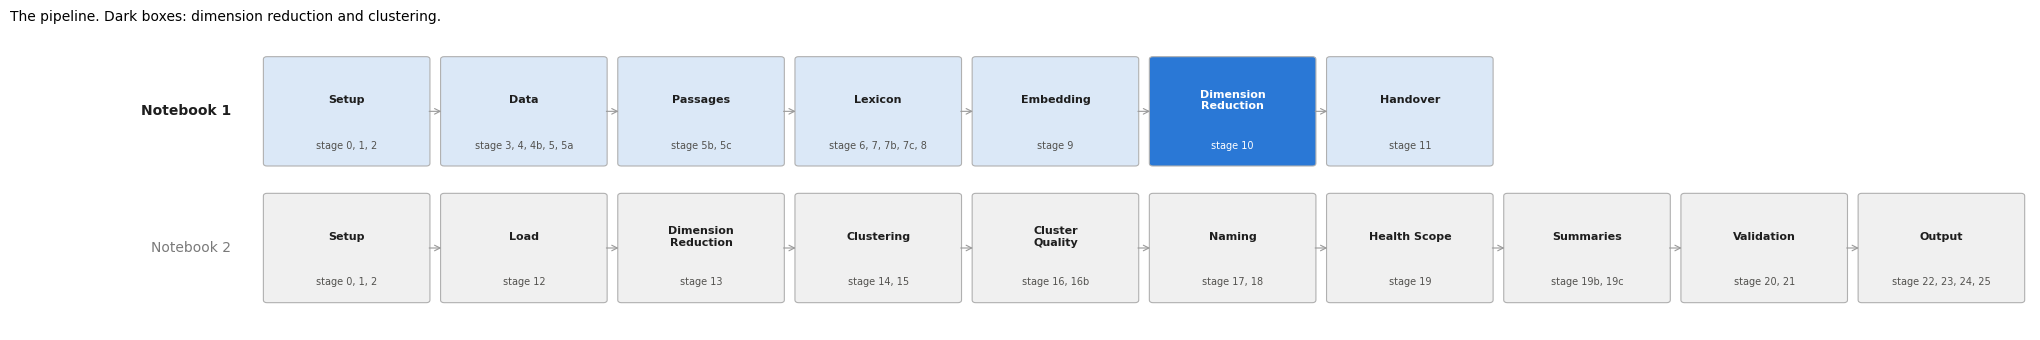


PRACTITIONER NOTE
  Keep every adjustable value in one place and publish it beside the results: a reader who cannot see
  the settings cannot check a figure. Describe the corpus with a column map, so the notebook runs on
  another collection and says which comparisons it could not make.


In [ ]:
# @title
# ==================================================================================================
# PHASE: SETUP                                                          stage 2 of 3 in this phase
# STAGE 1  CONFIGURATION
# WHAT THIS CELL DOES: every adjustable setting, in one place
# ==================================================================================================
# WHAT THIS CELL DOES
#   Holds every adjustable setting of notebooks 1 and 2, checks them, and draws the pipeline.
#
# WHY
#   A reader can see here, in one place, what produced every result. Each setting is classified
#   UPSTREAM (it can change the passages, the lexicon columns or the vectors) or DOWNSTREAM (it
#   cannot). The cache and the handover check both use this classification.
#
# HOW
#   The corpus is described by a column map: only an identifier and the text are required. Stages
#   that need a missing column say that they were skipped instead of failing.

from dataclasses import dataclass, asdict
import os, random
import numpy as np

# =============================================================================
#  EDIT HERE
# =============================================================================

SEED          = 42
CACHE_VERSION = "v2"          # raise to force every cached stage to recompute

# ---- the corpus -------------------------------------------------------------
DATA_PATH = CORPUS_PATH       # located by Stage 0 (Drive, an upload or a URL)

# Left: the name the notebook uses (do not change). Right: the column in your file, or None.
COLUMN_MAP = {
    "doc_id":         "url",              # REQUIRED. Unique per document.
    "text":           "body",             # REQUIRED. The text to analyse.
    "title":          "title",
    "group":          "country_searched", # the comparison variable
    "group_label":    "country_name",     # a readable name for the group
    "group_all":      "all_countries",    # every group of a document, separated by "|"
    "date":           "date",             # ISO date
    "year":           "year",
    "doc_type":       "format",           # the publisher's document type
    "lang_declared":  "language",         # the publisher's language label; not trusted (Stage 5)
    "external_label": "theme_name",       # an independent editorial label, for validation only
}
GROUP_NOUN = "country"        # what one group is, in words; used in labels only

# What the documents are, and the subject the lexicon defines, in words. They go into the
# instructions given to the models and into labels. Another corpus needs these two lines, the
# column map above and, for another subject, CODEBOOK_FILE below.
DOCUMENT_TYPE = "humanitarian report"   # singular
SUBJECT_NAME  = "health"

# ---- cleaning (Stage 4) -----------------------------------------------------
BOILERPLATE_MIN_DOC_FRACTION   = 0.15  # a sentence in this share of documents is boilerplate
BOILERPLATE_MIN_SENTENCE_CHARS = 40    # shorter sentences are never boilerplate
NEAR_DUPLICATE_THRESHOLD       = 0.90  # cosine at or above this is flagged, never deleted
NEAR_DUPLICATE_EXACT_MAX_DOCS  = 5000  # above this, an approximate search is used
MIN_WORDS_AFTER_CLEANING       = 50    # a shorter document leaves the analysis set

# ---- stories: one version per release (Stage 5a) ----------------------------
STORY_WINDOW_DAYS        = 10     # translations of one release appear within this many days
STORY_NULL_QUANTILE      = 0.99   # threshold = this quantile of scores between impossible pairs
STORY_PREFERRED_LANGUAGE = "en"   # the version kept when a story exists in several languages

# ---- passages (Stages 5b and 5c) --------------------------------------------
PASSAGE_TARGET_WORDS     = 160
PASSAGE_MAX_WORDS        = 250
PASSAGE_MIN_WORDS        = 20     # shorter passages are discarded and counted
PASSAGE_MERGE_TAIL_UNDER = 80     # a shorter final fragment joins the previous passage
PLACE_PLACEHOLDER  = "location"   # replaces a masked place name
# Place names to mask beyond the built-in list (the eight countries of this corpus) and the entity
# model: for another corpus, its countries, regions, cities and demonyms, one whole name per entry.
EXTRA_PLACE_NAMES  = []
LIST_CAPITAL_SHARE = 0.55         # at or above this share of capitalised words, a passage is a list
                                  # of names, not prose (prose median on this corpus: 0.12)

# ---- embedding (Stage 9) ----------------------------------------------------
EMBEDDING_MODELS      = [("qwen3-8b", "Qwen/Qwen3-Embedding-8B")]
EMBEDDING_BATCH_SIZE  = 16
EMBEDDING_MAX_SEQ_LEN = 512       # passages stop at PASSAGE_MAX_WORDS, so 512 tokens is enough
# The task instruction, in English as the model card advises, in the format of the developers'
# clustering evaluation: "Instruct: {task}\nQuery:{text}" (Zhang et al. 2025). Empty = none.
EMBEDDING_INSTRUCTION = ("Identify the topic or theme of the given passage from "
                         f"{'an' if DOCUMENT_TYPE[:1].lower() in 'aeiou' else 'a'} {DOCUMENT_TYPE}")
# A multilingual model still sets each language slightly apart. "auto": remove each language's
# offset (estimated on translation pairs) only if held-out translations then find their original
# more often. "on": always. "off": never. See Stage 9.
LANGUAGE_CORRECTION = "auto"
# A second, independent embedding model. Notebook 2 (Stage 16b) clusters its vectors the same way
# and reports which sub-themes come back: themes that depend on one model are marked. None = skip.
SECOND_EMBEDDING_MODEL = ("bge-m3", "BAAI/bge-m3")   # (short name, Hugging Face id); MIT licence

# ---- dimension reduction: UMAP (Stage 10) -----------------------------------
# "auto": search the grid, unless UMAP_FROZEN was tuned on this very analysis set and still measures
# above the floor. "search": always search. "frozen": never search.
PROJECTION_MODE            = "auto"
PROJECTION_TUNED_ON_CORPUS = ""        # the fingerprint Stage 10 prints after a search
UMAP_FROZEN          = (80, 0.1, 10)   # (n_neighbors, min_dist, n_components)
UMAP_NEIGHBORS_GRID  = [15, 30, 50, 80]
UMAP_MIN_DIST_GRID   = [0.0, 0.1]
UMAP_COMPONENTS_GRID = [5, 10, 20]
TRUSTWORTHINESS_K    = 15              # neighbourhood size for trustworthiness and continuity
PROJECTION_RECORDED_HARMONIC = 0.904   # the quality UMAP_FROZEN measured when it was tuned
PROJECTION_QUALITY_TOLERANCE = 0.06    # floor = record minus this
PROJECTION_TIE_TOLERANCE     = 0.001   # settings within this of the best score are tied; the tie
                                       # goes to fewer dimensions, then fewer neighbours. On this
                                       # corpus 0.001 absorbs sampling noise (0.0003) and no more.

# ---- clustering (notebook 2, Stages 14 and 15) ------------------------------
# Two levels. How many clusters each level has is found by a stated rule, never fixed in advance.
#   SUB-THEMES, the fine level: every distinct topic, found on the UMAP projection.
#   THEMES, the standard level: similar sub-themes grouped together in the embedding space.
SUBTHEME_METHOD  = "hdbscan"  # "hdbscan": density-based; unclear passages are held aside (default)
                              # "ward":    centroid-based; every passage is placed at once
HDBSCAN_MIN_SIZE = None       # smallest sub-theme. None = MIN_EXPECTED_CELL x number of groups:
                              # the smallest sub-theme that can be compared across groups
WARD_K_RANGE     = (10, 60)   # "ward": the number of sub-themes is sought in this range
THEME_K_RANGE    = (4, 12)    # the number of themes is sought in this range: the size of a
                              # thematic map a reader can take in at once
                              # Both are cut at the largest jump in Ward fusion height (Mojena 1977)
SUBTHEME_COUNT_FIXED = None   # an integer replaces the rule for the number of "ward" sub-themes
THEME_COUNT_FIXED    = None   # an integer replaces the rule for the number of themes
CLUSTER_SEEDS     = 5         # UMAP runs with different seeds; the reported partition is the one
                              # that agrees best with the others
CONFIDENCE_FLOOR  = 0.60      # a passage in its sub-theme on fewer of the seeds is "held weakly"
COHERENCE_FLOOR   = 0.0       # mean silhouette below this: passages sit closer to another cluster
MAX_CLUSTER_SHARE = 0.50      # one cluster above this share of passages dominates the partition
LANGUAGE_ARTEFACT_SHARE      = 0.90  # one language holding this share of a cluster ...
LANGUAGE_ARTEFACT_CORPUS_MAX = 0.50  # ... while holding at most this share of all passages

# ---- cluster quality (notebook 2, Stages 16 and 18) -------------------------
BOOTSTRAP_N            = 50     # resampling rounds for cluster stability (Hennig 2007)
STABILITY_JACCARD_MIN  = 0.75   # Hennig (2007): mean Jaccard at or above this is a stable cluster
UNSTABLE_CLUSTER_FLOOR = 0.50   # Hennig (2007): at or below this the cluster dissolves
SILHOUETTE_FLOOR       = 0.05   # the name gate's floor for a theme's silhouette
PERMUTATION_MAX_N      = 1500   # the permutation null is computed on a sample above this size

# ---- naming (Stages 17 and 18) ----------------------------------------------
# Words a name may not contain. QUANTITY words would claim a level in the world; the corpus shows
# only what is reported. META words name the method, not the subject.
NAME_FORBIDDEN_QUANTITY = (
    "high", "low", "rising", "falling", "increasing", "decreasing", "growing", "declining",
    "severe", "severity", "acute", "widespread", "prevalent", "prevalence", "incidence",
    "burden", "crisis", "emergency", "epidemic", "surge", "spike", "worsening", "improving",
    "majority", "minority", "most", "least", "more", "less", "many", "few", "rate", "rates",
    "level", "levels", "trend", "trends", "significant", "significantly", "massive", "extreme",
)
NAME_FORBIDDEN_META = (
    "theme", "themes", "cluster", "clusters", "topic", "topics", "group", "groups",
    "category", "categories", "class", "classes", "unnamed", "miscellaneous", "other", "various",
    "general", "mixed",
)
NAME_MAX_WORDS  = 6
NAME_MIN_WORDS  = 1      # one word is enough when it is a subject: cholera, migration
NAME_MIN_LIFT   = 1.30   # the name's words must be this much more frequent in its own cluster,
                         # on the smoothed lift (Monroe, Colaresi and Quinn 2008)
NAME_MIN_MARGIN = 0.04   # below this, the name fits another cluster about as well
NAME_STEM_CHARS = 6      # de-duplicates the words of a label built from terms
NAME_MISDIRECTED_MAX_SHARE = 0.75  # share of a cluster's passages that may contain no name word
NAME_LANGUAGE   = "en"   # every name is written in this language
NAME_LEXICAL_MIN_SHARE = 0.50  # the word-based name tests apply only when at least this share of
                               # the cluster is in NAME_LANGUAGE
NAME_FOREIGN_MAX_SHARE = 0.25  # a name word found mostly outside NAME_LANGUAGE is foreign
NAME_RETRY = True        # a rejected name is asked for once more, with the reason
# Fixed terms that contain a forbidden word but name a subject, not a quantity or the method.
NAME_ALLOWED_PHRASES = (
    "armed group", "armed groups", "support group", "support groups",
    "acute malnutrition", "severe acute malnutrition", "acute watery diarrhoea",
    "acute watery diarrhea", "emergency care", "emergency surgery", "emergency room",
    "emergency department", "emergency obstetric care",
)

# ---- the instruction model (Stages 7, 17, 19b and 20) -----------------------
LLM_ENABLE       = True
LLM_MODEL        = "Qwen/Qwen3-4B-Instruct-2507"   # Apache-2.0, July 2025; transformers >= 4.51
LLM_LOAD_IN_4BIT = False  # 16-bit fits a 16 GB GPU; True halves the memory
LLM_N_QUOTES     = 7      # passages shown to the model per cluster

# ---- summaries (Stage 19b) --------------------------------------------------
# SUMMARY_PASSAGE_SCOPE: "auto" (every passage when a GPU is present, else the quoted passages
# only), "all" (every passage; about 20 to 60 minutes on a GPU for 4,000 passages),
# "representative" (the quoted passages only, a few minutes) or "none". The dashboard shows a
# passage's own summary on hover, so "auto" or "all" is needed for every point to have one.
SUMMARY_ENABLE             = True
SUMMARY_CLUSTER_SENTENCES  = 3
SUMMARY_PASSAGE_SCOPE      = "auto"
SUMMARY_PASSAGE_MAX_WORDS  = 28   # a longer passage summary is rejected
SUMMARY_BATCH              = 8
SUMMARY_MAX_QUOTE_WORDS    = 110  # a quotation is cut to this before it is sent to the model
# Stage 19c checks every summary against its source text with a fact-checking model (MiniCheck,
# Tang, Laban and Durrett 2024): "flan-t5-large" (770M, MIT, English). "" = skip the check.
GROUNDING_MODEL     = "flan-t5-large"
GROUNDING_THRESHOLD = 0.5    # below this support probability a summary is marked "not supported"

# The corpus shows what agencies chose to publish: VISIBILITY in public reporting, never prevalence,
# incidence, burden or severity. A summary with one of these phrases is asked for once more; if it
# still contains one, it is withheld.
SUMMARY_FORBIDDEN_CLAIMS = (
    "most common", "commonest", "most frequent", "most prevalent", "prevalence",
    "incidence", "burden of disease", "disease burden", "high burden",
    "widespread", "epidemic of", "rates of", "morbidity", "mortality rate",
    "leading cause", "main cause", "primary cause", "majority of patients",
    "majority of people", "majority of cases", "increasing number of cases",
    "on the rise", "growing crisis", "worsening health", "severity of",
    "more severe", "affected the most", "worst affected", "hardest hit",
)
# Words that judge severity. A summary using one is asked for once more and the second answer is
# marked. "acute" and "emergency" are absent: "acute malnutrition" is a clinical term.
SUMMARY_SEVERITY_WORDS = (
    "critical", "critically", "severe", "severely", "dire", "alarming", "catastrophic",
    "catastrophe", "crisis", "crises", "devastating", "deteriorating", "deteriorated",
    "exacerbated", "overwhelming", "overwhelmed", "unprecedented", "grave", "desperate",
)

# ---- the lexicon and scope (Stages 6, 7, 8 and 19) ---------------------------
# CODEBOOK_FILE: "" uses the built-in lexicon (12 health categories, English, French, Spanish,
# Arabic). For another subject, a JSON file: {"categories": {category: {language: [regex, ...]}},
# "short_labels": {category: label}} and, optionally, "canonical": {regex: label} and
# "sub_concepts": {name: [regex, ...]}. Stage 6 writes the built-in lexicon in this format.
CODEBOOK_FILE = ""
SCOPE_SHARE_FLOOR  = 0.40   # a sub-theme is in scope when this share of its passages matches
SCOPE_SENSITIVITY  = (0.30, 0.40, 0.50)   # the rule is re-applied at each and compared
SCOPE_MANUAL_OVERRIDE = []  # sub-theme numbers to force into scope; empty uses the rule
VALIDATION_SAMPLE_PER_CATEGORY = 20       # matches judged per category for precision
PRECISION_FLOOR = 0.80                    # a category below this is reported as weak
# A random sample of ALL passages, coded by a person for every category (Stage 7c). It corrects the
# lexicon's shares per group and measures recall. 40 per group is about 3 hours of reading for 8
# groups. 0 = no sample.
HUMAN_SAMPLE_PER_GROUP = 40

# ---- group comparison (Stage 8) ---------------------------------------------
SMALL_GROUP_N     = 40   # a group with fewer documents is marked as small
MIN_EXPECTED_CELL = 5    # below this expected count a cell is not interpreted

# ---- statistics carried to notebook 3 (notebooks 1 and 2 do not read them) ---
RESIDUAL_NOTABLE       = 2.0   # a standardised residual beyond this is notable
FDR_ALPHA              = 0.05
MIN_DOCS_FOR_SUBJECT   = 3
TOP_SUBJECTS_PER_THEME = 8
MIN_DOCS_WITH_BARRIER  = 20
NEGATION_CONCERN_SHARE = 0.15
QUOTES_PER_CELL        = 3
CASE_STUDY_PAIR        = None  # None: the two largest groups

# ---- figures and output -----------------------------------------------------
FIGURE_STYLE = {"point_size": 4.6, "point_opacity": 0.55}
OUTPUT_NAMES = {"dashboard": "nb2_dashboard.html", "download": "thematic_analysis_outputs.zip"}

# ---- the interactive dashboard (Stage 24): what is SHOWN, never a result -----
DASHBOARD_QUOTES_PER_CLUSTER = 8      # passages shown per cluster, the most central first
DASHBOARD_POINT_LIMIT        = 12000  # above this, a seeded sample of points is drawn
DASHBOARD_TEXT_CHARS         = 900    # a longer passage is cut at a word

CHECKPOINT_DIR = DURABLE_DIR   # from Stage 0
OUTPUT_DIR     = WORKING_DIR   # from Stage 0

# =============================================================================
#  END EDIT
# =============================================================================

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
REQUIRED_INTERNAL_COLUMNS = ("doc_id", "text")


@dataclass(frozen=True)
class Config:
    seed: int
    cache_version: str
    data_path: str
    column_map: tuple
    group_noun: str
    document_type: str
    subject_name: str
    codebook_file: str
    boilerplate_min_doc_fraction: float
    boilerplate_min_sentence_chars: int
    near_duplicate_threshold: float
    near_duplicate_exact_max_docs: int
    min_words_after_cleaning: int
    story_window_days: int
    story_null_quantile: float
    story_preferred_language: str
    passage_target_words: int
    passage_min_words: int
    passage_max_words: int
    passage_merge_tail_under: int
    place_placeholder: str
    extra_place_names: tuple
    list_capital_share: float
    embedding_models: tuple
    embedding_batch_size: int
    embedding_max_seq_len: int
    embedding_instruction: str
    language_correction: str
    second_embedding_model: tuple
    projection_mode: str
    projection_tuned_on_corpus: str
    umap_frozen: tuple
    umap_neighbors_grid: tuple
    umap_min_dist_grid: tuple
    umap_components_grid: tuple
    trustworthiness_k: int
    projection_recorded_harmonic: float
    projection_quality_tolerance: float
    projection_tie_tolerance: float
    subtheme_method: str
    hdbscan_min_size: object
    ward_k_range: tuple
    theme_k_range: tuple
    subtheme_count_fixed: object
    theme_count_fixed: object
    cluster_seeds: int
    confidence_floor: float
    coherence_floor: float
    max_cluster_share: float
    language_artefact_share: float
    language_artefact_corpus_max: float
    bootstrap_n: int
    stability_jaccard_min: float
    unstable_cluster_floor: float
    silhouette_floor: float
    permutation_max_n: int
    name_forbidden_quantity: tuple
    name_forbidden_meta: tuple
    name_max_words: int
    name_min_words: int
    name_min_lift: float
    name_min_margin: float
    name_stem_chars: int
    name_misdirected_max_share: float
    name_language: str
    name_lexical_min_share: float
    name_foreign_max_share: float
    name_retry: bool
    name_allowed_phrases: tuple
    llm_enable: bool
    llm_model: str
    llm_load_in_4bit: bool
    llm_n_quotes: int
    summary_enable: bool
    summary_cluster_sentences: int
    summary_passage_scope: str
    summary_passage_max_words: int
    summary_batch: int
    summary_max_quote_words: int
    summary_forbidden_claims: tuple
    summary_severity_words: tuple
    grounding_model: str
    grounding_threshold: float
    scope_share_floor: float
    scope_sensitivity: tuple
    scope_manual_override: tuple
    validation_sample_per_category: int
    precision_floor: float
    human_sample_per_group: int
    small_group_n: int
    min_expected_cell: int
    residual_notable: float
    fdr_alpha: float
    min_docs_for_subject: int
    top_subjects_per_theme: int
    min_docs_with_barrier: int
    negation_concern_share: float
    quotes_per_cell: int
    case_study_pair: tuple
    figure_style: tuple
    output_names: tuple
    dashboard_quotes_per_cluster: int
    dashboard_point_limit: int
    dashboard_text_chars: int
    checkpoint_dir: str
    output_dir: str

    def as_dict(self):
        return asdict(self)

    def upstream_dict(self):
        """Only the settings that could change the passages, lexicon columns or vectors."""
        return {k: v for k, v in sorted(asdict(self).items()) if k in UPSTREAM_SETTINGS}

    def style(self, key):
        return dict(self.figure_style)[key]

    def output(self, key):
        return dict(self.output_names)[key]

    def column(self, internal_name):
        """The column in the loaded file that carries this internal name, or None."""
        return dict(self.column_map).get(internal_name)

    @property
    def projection_quality_floor(self):
        return self.projection_recorded_harmonic - self.projection_quality_tolerance


# UPSTREAM: changing it could change the passages, the lexicon columns or the vectors, so notebook 2
# stops if it differs from notebook 1. DOWNSTREAM: nothing that produces those reads it.
UPSTREAM_SETTINGS = frozenset({
    "seed", "cache_version", "data_path", "column_map", "group_noun", "codebook_file",
    "boilerplate_min_doc_fraction", "boilerplate_min_sentence_chars",
    "near_duplicate_threshold", "near_duplicate_exact_max_docs", "min_words_after_cleaning",
    "story_window_days", "story_null_quantile", "story_preferred_language",
    "passage_target_words", "passage_min_words", "passage_max_words",
    "passage_merge_tail_under", "place_placeholder", "extra_place_names", "list_capital_share",
    "embedding_models", "embedding_batch_size", "embedding_max_seq_len", "embedding_instruction",
    "language_correction", "second_embedding_model",
    "projection_mode", "projection_tuned_on_corpus",
    "umap_frozen", "umap_neighbors_grid", "umap_min_dist_grid", "umap_components_grid",
    "trustworthiness_k", "projection_recorded_harmonic", "projection_quality_tolerance",
    "projection_tie_tolerance",
    "validation_sample_per_category", "precision_floor", "human_sample_per_group",
    "scope_share_floor", "scope_sensitivity", "scope_manual_override",
    "small_group_n", "min_expected_cell",
})
DOWNSTREAM_SETTINGS = frozenset({
    "document_type", "subject_name", "name_allowed_phrases",
    "subtheme_method", "hdbscan_min_size", "ward_k_range", "theme_k_range",
    "subtheme_count_fixed", "theme_count_fixed", "cluster_seeds", "confidence_floor",
    "coherence_floor", "max_cluster_share", "language_artefact_share",
    "language_artefact_corpus_max",
    "bootstrap_n", "stability_jaccard_min", "unstable_cluster_floor", "silhouette_floor",
    "permutation_max_n",
    "name_forbidden_quantity", "name_forbidden_meta", "name_max_words", "name_min_words",
    "name_min_lift", "name_min_margin", "name_stem_chars", "name_misdirected_max_share",
    "name_language", "name_lexical_min_share", "name_foreign_max_share", "name_retry",
    "llm_enable", "llm_model", "llm_load_in_4bit", "llm_n_quotes",
    "summary_enable", "summary_cluster_sentences", "summary_passage_scope",
    "summary_passage_max_words", "summary_batch", "summary_max_quote_words",
    "summary_forbidden_claims", "summary_severity_words", "grounding_model", "grounding_threshold",
    "residual_notable", "fdr_alpha", "min_docs_for_subject", "top_subjects_per_theme",
    "min_docs_with_barrier", "negation_concern_share", "quotes_per_cell", "case_study_pair",
    "figure_style", "output_names",
    "dashboard_quotes_per_cluster", "dashboard_point_limit", "dashboard_text_chars",
    "checkpoint_dir", "output_dir",
})

CFG = Config(
    seed=SEED, cache_version=CACHE_VERSION, data_path=DATA_PATH,
    column_map=tuple(sorted(COLUMN_MAP.items())), group_noun=GROUP_NOUN,
    document_type=str(DOCUMENT_TYPE), subject_name=str(SUBJECT_NAME),
    codebook_file=str(CODEBOOK_FILE or ""),
    boilerplate_min_doc_fraction=BOILERPLATE_MIN_DOC_FRACTION,
    boilerplate_min_sentence_chars=BOILERPLATE_MIN_SENTENCE_CHARS,
    near_duplicate_threshold=NEAR_DUPLICATE_THRESHOLD,
    near_duplicate_exact_max_docs=NEAR_DUPLICATE_EXACT_MAX_DOCS,
    min_words_after_cleaning=MIN_WORDS_AFTER_CLEANING,
    story_window_days=int(STORY_WINDOW_DAYS), story_null_quantile=float(STORY_NULL_QUANTILE),
    story_preferred_language=str(STORY_PREFERRED_LANGUAGE),
    passage_target_words=PASSAGE_TARGET_WORDS, passage_min_words=PASSAGE_MIN_WORDS,
    passage_max_words=PASSAGE_MAX_WORDS, passage_merge_tail_under=PASSAGE_MERGE_TAIL_UNDER,
    place_placeholder=PLACE_PLACEHOLDER, list_capital_share=float(LIST_CAPITAL_SHARE),
    extra_place_names=tuple(str(n) for n in EXTRA_PLACE_NAMES),
    embedding_models=tuple(EMBEDDING_MODELS), embedding_batch_size=EMBEDDING_BATCH_SIZE,
    embedding_max_seq_len=EMBEDDING_MAX_SEQ_LEN, embedding_instruction=str(EMBEDDING_INSTRUCTION),
    language_correction=str(LANGUAGE_CORRECTION),
    second_embedding_model=(tuple(SECOND_EMBEDDING_MODEL) if SECOND_EMBEDDING_MODEL else ()),
    projection_mode=str(PROJECTION_MODE),
    projection_tuned_on_corpus=str(PROJECTION_TUNED_ON_CORPUS),
    umap_frozen=tuple(UMAP_FROZEN), umap_neighbors_grid=tuple(UMAP_NEIGHBORS_GRID),
    umap_min_dist_grid=tuple(UMAP_MIN_DIST_GRID), umap_components_grid=tuple(UMAP_COMPONENTS_GRID),
    trustworthiness_k=TRUSTWORTHINESS_K,
    projection_recorded_harmonic=PROJECTION_RECORDED_HARMONIC,
    projection_quality_tolerance=PROJECTION_QUALITY_TOLERANCE,
    projection_tie_tolerance=PROJECTION_TIE_TOLERANCE,
    subtheme_method=str(SUBTHEME_METHOD),
    hdbscan_min_size=None if HDBSCAN_MIN_SIZE is None else int(HDBSCAN_MIN_SIZE),
    ward_k_range=tuple(int(v) for v in WARD_K_RANGE),
    theme_k_range=tuple(int(v) for v in THEME_K_RANGE),
    subtheme_count_fixed=None if SUBTHEME_COUNT_FIXED is None else int(SUBTHEME_COUNT_FIXED),
    theme_count_fixed=None if THEME_COUNT_FIXED is None else int(THEME_COUNT_FIXED),
    cluster_seeds=int(CLUSTER_SEEDS),
    confidence_floor=float(CONFIDENCE_FLOOR), coherence_floor=float(COHERENCE_FLOOR),
    max_cluster_share=float(MAX_CLUSTER_SHARE),
    language_artefact_share=float(LANGUAGE_ARTEFACT_SHARE),
    language_artefact_corpus_max=float(LANGUAGE_ARTEFACT_CORPUS_MAX),
    bootstrap_n=int(BOOTSTRAP_N), stability_jaccard_min=float(STABILITY_JACCARD_MIN),
    unstable_cluster_floor=float(UNSTABLE_CLUSTER_FLOOR),
    silhouette_floor=float(SILHOUETTE_FLOOR), permutation_max_n=int(PERMUTATION_MAX_N),
    name_forbidden_quantity=NAME_FORBIDDEN_QUANTITY,
    name_forbidden_meta=NAME_FORBIDDEN_META, name_max_words=NAME_MAX_WORDS,
    name_min_words=NAME_MIN_WORDS, name_min_lift=NAME_MIN_LIFT, name_min_margin=NAME_MIN_MARGIN,
    name_stem_chars=NAME_STEM_CHARS, name_misdirected_max_share=NAME_MISDIRECTED_MAX_SHARE,
    name_language=NAME_LANGUAGE, name_lexical_min_share=NAME_LEXICAL_MIN_SHARE,
    name_foreign_max_share=NAME_FOREIGN_MAX_SHARE, name_retry=bool(NAME_RETRY),
    name_allowed_phrases=tuple(str(p).lower() for p in NAME_ALLOWED_PHRASES),
    llm_enable=LLM_ENABLE, llm_model=LLM_MODEL, llm_load_in_4bit=bool(LLM_LOAD_IN_4BIT),
    llm_n_quotes=LLM_N_QUOTES,
    summary_enable=SUMMARY_ENABLE,
    summary_cluster_sentences=SUMMARY_CLUSTER_SENTENCES,
    summary_passage_scope=SUMMARY_PASSAGE_SCOPE,
    summary_passage_max_words=SUMMARY_PASSAGE_MAX_WORDS,
    summary_batch=SUMMARY_BATCH,
    summary_max_quote_words=SUMMARY_MAX_QUOTE_WORDS,
    summary_forbidden_claims=SUMMARY_FORBIDDEN_CLAIMS,
    summary_severity_words=tuple(SUMMARY_SEVERITY_WORDS),
    grounding_model=str(GROUNDING_MODEL or ""), grounding_threshold=float(GROUNDING_THRESHOLD),
    scope_share_floor=SCOPE_SHARE_FLOOR, scope_sensitivity=tuple(SCOPE_SENSITIVITY),
    scope_manual_override=tuple(SCOPE_MANUAL_OVERRIDE),
    validation_sample_per_category=VALIDATION_SAMPLE_PER_CATEGORY, precision_floor=PRECISION_FLOOR,
    human_sample_per_group=int(HUMAN_SAMPLE_PER_GROUP),
    small_group_n=SMALL_GROUP_N, min_expected_cell=MIN_EXPECTED_CELL,
    residual_notable=RESIDUAL_NOTABLE, fdr_alpha=FDR_ALPHA,
    min_docs_for_subject=MIN_DOCS_FOR_SUBJECT, top_subjects_per_theme=TOP_SUBJECTS_PER_THEME,
    min_docs_with_barrier=MIN_DOCS_WITH_BARRIER,
    negation_concern_share=NEGATION_CONCERN_SHARE, quotes_per_cell=QUOTES_PER_CELL,
    case_study_pair=(tuple(CASE_STUDY_PAIR) if CASE_STUDY_PAIR else ()),
    figure_style=tuple(sorted(FIGURE_STYLE.items())),
    output_names=tuple(sorted(OUTPUT_NAMES.items())),
    dashboard_quotes_per_cluster=int(DASHBOARD_QUOTES_PER_CLUSTER),
    dashboard_point_limit=int(DASHBOARD_POINT_LIMIT),
    dashboard_text_chars=int(DASHBOARD_TEXT_CHARS),
    checkpoint_dir=CHECKPOINT_DIR, output_dir=OUTPUT_DIR,
)

# ---- checks -----------------------------------------------------------------
# An unclassified setting would be ignored by the cache and the handover check without any warning.
_fields = set(CFG.as_dict())
_unclassified = sorted(_fields - UPSTREAM_SETTINGS - DOWNSTREAM_SETTINGS)
_both = sorted(UPSTREAM_SETTINGS & DOWNSTREAM_SETTINGS)
_phantom = sorted((UPSTREAM_SETTINGS | DOWNSTREAM_SETTINGS) - _fields)
assert not _unclassified, f"Add these settings to UPSTREAM or DOWNSTREAM: {_unclassified}."
assert not _both, f"These settings are in both lists: {_both}."
assert not _phantom, f"These classified names are not settings: {_phantom}."

_SUMMARY_SCOPES = ("auto", "representative", "all", "none")
assert CFG.summary_passage_scope in _SUMMARY_SCOPES, (
    f"SUMMARY_PASSAGE_SCOPE must be one of {_SUMMARY_SCOPES}.")
assert int(CFG.summary_cluster_sentences) >= 1, "SUMMARY_CLUSTER_SENTENCES must be at least 1."
assert CFG.subtheme_method in ("hdbscan", "ward"), 'SUBTHEME_METHOD must be "hdbscan" or "ward".'
assert CFG.language_correction in ("auto", "on", "off"), (
    'LANGUAGE_CORRECTION must be "auto", "on" or "off".')
assert not CFG.second_embedding_model or len(CFG.second_embedding_model) == 2, (
    "SECOND_EMBEDDING_MODEL must be (short name, Hugging Face id) or None.")
assert 0.0 < CFG.grounding_threshold < 1.0, "GROUNDING_THRESHOLD must be between 0 and 1."
assert not CFG.codebook_file or os.path.exists(CFG.codebook_file), (
    f"CODEBOOK_FILE not found: {CFG.codebook_file}. Leave it empty for the built-in lexicon.")
assert CFG.theme_k_range[0] >= 2 and CFG.theme_k_range[0] <= CFG.theme_k_range[1], (
    "THEME_K_RANGE must be (low, high) with 2 <= low <= high.")
assert CFG.cluster_seeds >= 2, "CLUSTER_SEEDS must be at least 2, or stability cannot be measured."

_missing_required = [name for name in REQUIRED_INTERNAL_COLUMNS if not CFG.column(name)]
if _missing_required:
    raise ValueError("COLUMN_MAP must give a column for: " + ", ".join(_missing_required) + ".")


def set_all_seeds(seed=None):
    """Fix every random source the notebook uses."""
    s = CFG.seed if seed is None else int(seed)
    os.environ["PYTHONHASHSEED"] = str(s)
    random.seed(s)
    np.random.seed(s)
    try:
        import torch
        torch.manual_seed(s)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(s)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass


set_all_seeds()

PRACTITIONER_NOTES = []


def practitioner_note(stage, text):
    PRACTITIONER_NOTES.append({"stage": stage, "note": " ".join(text.split())})
    print("\nPRACTITIONER NOTE")
    print("  " + "\n  ".join(line.strip() for line in text.strip().split("\n")))


# ---- what this configuration will do ----------------------------------------
_optional_present = sorted(k for k, v in COLUMN_MAP.items()
                           if v and k not in REQUIRED_INTERNAL_COLUMNS)
_optional_absent = sorted(k for k, v in COLUMN_MAP.items() if not v)
_method = ("HDBSCAN (leaf clusters)" if CFG.subtheme_method == "hdbscan"
           else f"Ward, cut at the largest fusion jump in {CFG.ward_k_range}")

print("=" * OUTPUT_WIDTH)
print("  STAGE 1  CONFIGURATION")
print("=" * OUTPUT_WIDTH)
print(f"  seed                : {CFG.seed}")
print(f"  input file          : {CFG.data_path}  ({CORPUS_ORIGIN})")
print(f"  group variable      : {CFG.group_noun}   (column: {CFG.column('group') or 'NOT MAPPED'})")
print(f"  optional mapped     : {', '.join(_optional_present) if _optional_present else 'none'}")
print(f"  optional not mapped : {', '.join(_optional_absent) if _optional_absent else 'none'}")
print(f"  embedding model     : {', '.join(name for name, _ in CFG.embedding_models)}"
      f"{'; second model ' + CFG.second_embedding_model[0] if CFG.second_embedding_model else ''}")
print(f"  dimension reduction : UMAP, setting chosen by trustworthiness and continuity "
      f"(mode '{CFG.projection_mode}')")
print(f"  sub-themes          : {_method}, over {CFG.cluster_seeds} UMAP seeds")
print(f"  themes              : sub-themes grouped by Ward, cut at the largest fusion jump in "
      f"{CFG.theme_k_range}")
print(f"  stability           : bootstrap Jaccard, stable at {CFG.stability_jaccard_min}, "
      f"dissolved at {CFG.unstable_cluster_floor} (Hennig 2007)")
print(f"  documents, subject  : {CFG.document_type}; {CFG.subject_name}")
print(f"  lexicon             : {CFG.codebook_file or 'built-in (Stage 6)'}")
print(f"  {CFG.subject_name + ' scope':<20}: a sub-theme is in scope at "
      f"{CFG.scope_share_floor:.0%} matched passages, tested at {CFG.scope_sensitivity}")
print(f"  cache directory     : {CFG.checkpoint_dir}  (version {CFG.cache_version})")
print(f"  output directory    : {CFG.output_dir}")
print("=" * OUTPUT_WIDTH)

# ---- figure: the pipeline, and where this notebook sits in it ---------------
# The build writes PIPELINE_MAP from the one stage map, so this figure and the cells agree.
PIPELINE_MAP = {'this_notebook': 1, 'notebooks': [(1, [('SETUP', ['0', '1', '2']), ('DATA', ['3', '4', '4b', '5', '5a']), ('PASSAGES', ['5b', '5c']), ('LEXICON', ['6', '7', '7b', '7c', '8']), ('EMBEDDING', ['9']), ('DIMENSION REDUCTION', ['10']), ('HANDOVER', ['11'])]), (2, [('SETUP', ['0', '1', '2']), ('LOAD', ['12']), ('DIMENSION REDUCTION', ['13']), ('CLUSTERING', ['14', '15']), ('CLUSTER QUALITY', ['16', '16b']), ('NAMING', ['17', '18']), ('HEALTH SCOPE', ['19']), ('SUMMARIES', ['19b', '19c']), ('VALIDATION', ['20', '21']), ('OUTPUT', ['22', '23', '24', '25'])])]}
if PIPELINE_MAP:
    import textwrap as _textwrap
    import matplotlib.pyplot as _plt
    from matplotlib.patches import FancyBboxPatch as _Box
    _ink, _muted, _key, _light = "#1E1E1E", "#7a7a7a", "#2a78d6", "#dbe8f7"
    _rows = PIPELINE_MAP["notebooks"]
    _width = max(len(phases) for _, phases in _rows)
    _fig, _ax = _plt.subplots(figsize=(2.05 * _width, 1.55 * len(_rows) + 0.4))
    for r, (number, phases) in enumerate(_rows):
        y = len(_rows) - 1 - r
        current = number == PIPELINE_MAP["this_notebook"]
        _ax.text(-0.15, y, f"Notebook {number}", ha="right", va="center", fontsize=10,
                 fontweight="bold" if current else "normal", color=_ink if current else _muted)
        for k, (phase, stages) in enumerate(phases):
            key = phase in ("DIMENSION REDUCTION", "CLUSTERING")
            face = (_key if key else _light) if current else "#f0f0f0"
            _ax.add_patch(_Box((k + 0.05, y - 0.38), 0.9, 0.76, boxstyle="round,pad=0.02",
                               facecolor=face, edgecolor="#b0b0b0", linewidth=0.8))
            label = "\n".join(_textwrap.wrap(phase.title(), 13))
            _ax.text(k + 0.5, y + 0.08, label, ha="center", va="center", fontsize=8,
                     color="white" if (current and key) else _ink, fontweight="bold")
            _ax.text(k + 0.5, y - 0.25, "stage " + ", ".join(stages), ha="center", va="center",
                     fontsize=7, color="white" if (current and key) else "#52514e")
            if k:
                _ax.annotate("", xy=(k + 0.05, y), xytext=(k - 0.05, y),
                             arrowprops=dict(arrowstyle="->", color="#9a9a9a", lw=0.8))
    _ax.set_xlim(-1.4, _width)
    _ax.set_ylim(-0.6, len(_rows) - 0.4)
    _ax.axis("off")
    _ax.set_title("The pipeline. Dark boxes: dimension reduction and clustering.", fontsize=10,
                  loc="left")
    _fig.tight_layout()
    _plt.show()

practitioner_note("Configuration", """
Keep every adjustable value in one place and publish it beside the results: a reader who cannot see
the settings cannot check a figure. Describe the corpus with a column map, so the notebook runs on
another collection and says which comparisons it could not make.
""")

In [ ]:
# @title
# ==================================================================================================
# PHASE: SETUP                                                          stage 3 of 3 in this phase
# STAGE 2  LIBRARY
# WHAT THIS CELL DOES: shared functions: cache, figures, number register, UMAP, clustering
# ==================================================================================================
# WHAT THIS CELL DOES
#   Provides the machinery shared across the notebook: a content-addressed cache for expensive
#   artifacts, a register of every reported number, house-style figure saving, and the ledger,
#   UMAP, clustering and instruction-model helpers used by later stages.
#
# WHY
#   A cache keyed on the actual objects an artifact was computed from cannot go stale: different
#   inputs produce different file names, so a given set of inputs has exactly one correct file.
#   Recording every reported number lets each one be traced back to the stage that produced it.
#   The clustering helpers live here so the self-test (Stage 21) runs the same code as the analysis.
#
# REFERENCES
#   Campello, R.J.G.B., Moulavi, D. and Sander, J. (2013) Density-based clustering based on
#     hierarchical density estimates. In PAKDD 2013, LNCS 7819:160-172. Springer.
#   Grootendorst, M. (2022) BERTopic: neural topic modeling with a class-based TF-IDF procedure.
#     arXiv:2203.05794.
#   Hennig, C. (2007) Cluster-wise assessment of cluster stability. Computational Statistics and
#     Data Analysis 52(1):258-271.
#   Hubert, L. and Arabie, P. (1985) Comparing partitions. Journal of Classification 2(1):193-218.
#   Mojena, R. (1977) Hierarchical grouping methods and stopping rules: an evaluation. The Computer
#     Journal 20(4):359-363.
#   Ward, J.H. (1963) Hierarchical grouping to optimize an objective function. Journal of the
#     American Statistical Association 58(301):236-244.

import os, io, json, pickle, hashlib, shutil, re, textwrap, datetime
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt

# =============================================================================
#  EDIT HERE
# =============================================================================

# prefer_local : read local first, then durable storage. Fastest. The default.
# prefer_durable: read durable storage first. Use when several machines share one Drive folder.
# durable_only : ignore the local copy entirely.
# local_only   : never touch durable storage.
# recompute    : ignore every cache and recompute. Nothing is deleted.
CACHE_POLICY = "prefer_local"

VERIFY_CACHED_BYTES = True   # check each artifact against the hash recorded in the manifest.
                             # Catches a truncated or partially synced download, which does happen
                             # with cloud folders, instead of loading it as if it were complete.

# =============================================================================
#  END EDIT
# =============================================================================

LOCAL_CACHE   = os.path.join(CFG.output_dir, "cache")      # fast, disposable
DURABLE_CACHE = CFG.checkpoint_dir                          # Drive when available
FIGURE_DIR    = os.path.join(CFG.output_dir, "figures")
ARTIFACT_DIR  = os.path.join(CFG.output_dir, "artifacts")
for _d in (LOCAL_CACHE, DURABLE_CACHE, FIGURE_DIR, ARTIFACT_DIR):
    os.makedirs(_d, exist_ok=True)

RUN_ID = hashlib.md5(f"{CFG.seed}|{CFG.cache_version}|{datetime.datetime.now().isoformat()}"
                     .encode()).hexdigest()[:6]


# ---- plain text output ------------------------------------------------------
# OUTPUT_WIDTH comes from Stage 0, which owns it. It is deliberately NOT redefined here.
def rule(character="=", width=None):
    print(character * (width or OUTPUT_WIDTH))

def heading(text, width=None):
    rule("=", width); print("  " + text); rule("=", width)


# ---- fingerprints -----------------------------------------------------------
def fingerprint(obj, _depth=0):
    """Stable hash of what an object contains, not of a name assumed to summarise it.

    Each type the pipeline passes around is handled explicitly; anything else falls back to
    repr(). Returns a 12-character hex digest."""
    h = hashlib.sha256()

    def feed(x, depth):
        if depth > 6:
            h.update(b"<deep>"); return
        if x is None:
            h.update(b"<none>")
        elif isinstance(x, (str, bytes)):
            h.update(x if isinstance(x, bytes) else x.encode("utf-8", "ignore"))
        elif isinstance(x, (bool, int, float)):
            h.update(repr(x).encode())
        elif isinstance(x, np.ndarray):
            # Hash the whole array. Sampling was used before and can miss a change that matters.
            h.update(str(x.shape).encode()); h.update(str(x.dtype).encode())
            h.update(np.ascontiguousarray(x).tobytes())
        elif isinstance(x, pd.DataFrame):
            h.update(str(x.shape).encode())
            h.update(",".join(map(str, x.columns)).encode())
            h.update(pd.util.hash_pandas_object(x, index=True).values.tobytes())
        elif isinstance(x, pd.Series):
            h.update(str(x.shape).encode()); h.update(str(x.name).encode())
            h.update(pd.util.hash_pandas_object(x, index=True).values.tobytes())
        elif isinstance(x, dict):
            for k in sorted(x, key=repr):
                feed(k, depth + 1); feed(x[k], depth + 1)
        elif isinstance(x, (list, tuple)):
            h.update(f"<seq{len(x)}>".encode())
            for item in x:
                feed(item, depth + 1)
        elif isinstance(x, set):
            for item in sorted(x, key=repr):
                feed(item, depth + 1)
        else:
            h.update(repr(x).encode("utf-8", "ignore"))

    feed(obj, _depth)
    return h.hexdigest()[:12]


CONFIG_FINGERPRINT = fingerprint(CFG.as_dict())


IRREGULAR_PLURALS = {"country": "countries", "city": "cities", "facility": "facilities",
                     "agency": "agencies", "category": "categories", "study": "studies",
                     "body": "bodies", "entity": "entities", "party": "parties",
                     "analysis": "analyses", "person": "people", "child": "children"}


def plural(noun, count=None):
    """Plural of a noun supplied by the configuration, for printing only.

    Handles irregular forms and the common English rules, since the group can be named anything.
    Pass count=1 for the singular. Returns the pluralised (or singular) string."""
    word = str(noun)
    if count == 1:
        return word
    lowered = word.lower()
    if lowered in IRREGULAR_PLURALS:
        formed = IRREGULAR_PLURALS[lowered]
    elif lowered.endswith("y") and len(lowered) > 1 and lowered[-2] not in "aeiou":
        formed = word[:-1] + "ies"
    elif lowered.endswith(("s", "x", "z", "ch", "sh")):
        formed = word + "es"
    else:
        formed = word + "s"
    return formed.capitalize() if word[:1].isupper() else formed


UPSTREAM_FINGERPRINT = fingerprint(CFG.upstream_dict())


def content_key(*inputs, scope="full"):
    """Cache key for an artifact computed from `inputs`, at the given scope: "full" keys on the
    whole configuration (the safe default), "upstream" on the settings that can change the
    passages, lexicon columns or vectors, "inputs" on just `inputs` and the cache version.
    Returns a 12-character key."""
    base = {"full": CONFIG_FINGERPRINT, "upstream": UPSTREAM_FINGERPRINT, "inputs": ""}[scope]
    return fingerprint([base, scope, CFG.cache_version, list(inputs)])


# ---- the manifest -----------------------------------------------------------
MANIFEST_PATH = os.path.join(DURABLE_CACHE, "MANIFEST.json")

def _read_manifest():
    if os.path.exists(MANIFEST_PATH):
        try:
            with open(MANIFEST_PATH) as fh:
                return json.load(fh)
        except Exception:
            print("  WARNING: the manifest could not be read and is being rebuilt. "
                  "Cached files are still usable; only their provenance record is lost.")
    return {"artifacts": {}}

def _write_manifest(manifest):
    tmp = MANIFEST_PATH + ".tmp"
    with open(tmp, "w") as fh:
        json.dump(manifest, fh, indent=2, sort_keys=True)
    os.replace(tmp, MANIFEST_PATH)          # atomic, so an interrupted write cannot corrupt it

MANIFEST = _read_manifest()


def _sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()[:16]


def _is_empty_result(obj):
    """True when `obj` is a failure sentinel that must not be cached: None, or anything with
    length zero."""
    if obj is None:
        return True
    try:
        return len(obj) == 0
    except TypeError:
        return False


CACHE_FILES = {}   # tag -> the filename and location it resolved to, this run


def cached(tag, compute, inputs, note="", scope="full"):
    """Return the cached artifact for `tag`, computing it via `compute()` on a miss.

    `inputs` must list every OBJECT the artifact depends on (the real objects, not their names),
    or a change to it will not invalidate the cache. Records what it resolved to in CACHE_FILES.
    Returns the artifact."""
    key = content_key(tag, *inputs, scope=scope)
    filename = f"{tag}__{key}.pkl"
    local_path   = os.path.join(LOCAL_CACHE, filename)
    durable_path = os.path.join(DURABLE_CACHE, filename)

    order = {"prefer_local":   [("local", local_path), ("durable", durable_path)],
             "prefer_durable": [("durable", durable_path), ("local", local_path)],
             "durable_only":   [("durable", durable_path)],
             "local_only":     [("local", local_path)],
             "recompute":      []}[CACHE_POLICY]

    for where, path in order:
        if not os.path.exists(path):
            continue
        record = MANIFEST["artifacts"].get(filename)
        if VERIFY_CACHED_BYTES and record and record.get("sha256"):
            actual = _sha256_file(path)
            if actual != record["sha256"]:
                print(f"  [{tag}] the {where} copy does not match the manifest "
                      f"(expected {record['sha256']}, found {actual}). It is being ignored; "
                      f"a partially synced file is not loaded as if it were complete.")
                continue
        with open(path, "rb") as fh:
            obj = pickle.load(fh)
        written = (record or {}).get("written_at", "unknown time")
        by_run  = (record or {}).get("run_id", "an earlier run")
        print(f"  [{tag}] loaded from {where} | written {written} by run {by_run} | key {key}")
        CACHE_FILES[tag] = {"filename": filename, "key": key, "path": path,
                            "location": where, "state": "loaded",
                            "bytes": os.path.getsize(path)}
        if where == "durable" and CACHE_POLICY != "durable_only" and not os.path.exists(local_path):
            shutil.copy2(path, local_path)      # keep the fast copy for next time
        return obj

    if CACHE_POLICY == "recompute":
        print(f"  [{tag}] CACHE_POLICY is 'recompute'; computing even though a copy may exist.")
    else:
        print(f"  [{tag}] not cached for key {key}; computing ...")

    obj = compute()

    if _is_empty_result(obj):
        print(f"  [{tag}] the result is empty and is NOT being cached, so a later run can retry.")
        CACHE_FILES[tag] = {"filename": filename, "key": key, "path": None,
                            "location": "none", "state": "empty, not cached", "bytes": 0}
        return obj

    with open(local_path, "wb") as fh:
        pickle.dump(obj, fh)
    digest = _sha256_file(local_path)
    if CACHE_POLICY != "local_only":
        try:
            shutil.copy2(local_path, durable_path)
            durable_state = "copied to durable storage"
        except Exception as exc:
            durable_state = f"NOT copied to durable storage ({type(exc).__name__})"
    else:
        durable_state = "local only, by policy"

    CACHE_FILES[tag] = {
        "filename": filename, "key": key,
        "path": (durable_path if os.path.exists(durable_path) else local_path),
        "location": ("durable" if os.path.exists(durable_path) else "local"),
        "state": f"computed, {durable_state}",
        "bytes": os.path.getsize(local_path)}

    MANIFEST["artifacts"][filename] = {
        "tag": tag, "key": key, "scope": scope, "sha256": digest,
        "written_at": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
        "run_id": RUN_ID, "config_fingerprint": CONFIG_FINGERPRINT,
        "bytes": os.path.getsize(local_path), "note": note,
        "input_fingerprints": [fingerprint(i) for i in inputs],
    }
    _write_manifest(MANIFEST)
    print(f"  [{tag}] computed and saved | key {key} | "
          f"{os.path.getsize(local_path)/1e6:.1f} MB | {durable_state}")
    return obj


def save_artifact(name, obj):
    with open(os.path.join(ARTIFACT_DIR, f"{name}.pkl"), "wb") as fh:
        pickle.dump(obj, fh)

def load_artifact(name):
    path = os.path.join(ARTIFACT_DIR, f"{name}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as fh:
            return pickle.load(fh)
    return None


# ---- the number register ----------------------------------------------------
NUMBER_REGISTER = []

def report(name, value, unit, stage, note=""):
    """Record a number the notebook reports (name, value, unit, stage, note) in NUMBER_REGISTER,
    so every number that appears in a figure can be traced. Returns `value` unchanged."""
    try:
        numeric = float(value)
    except (TypeError, ValueError):
        numeric = float("nan")
    NUMBER_REGISTER.append({"name": name, "value": numeric, "unit": unit,
                            "stage": stage, "run_id": RUN_ID, "note": note})
    return value

def register_table():
    return pd.DataFrame(NUMBER_REGISTER)


# ---- house style ------------------------------------------------------------
BACKGROUND, INK, GRID = "#FFFFFF", "#1E1E1E", "#E4E4E4"
ACCENT = "#9B1B30"
# Two semantic colours, so a figure does not have to invent them and two figures cannot disagree
# about which colour means "this one failed a check".
NEUTRAL = "#2B6CB0"      # an ordinary result
WARN = "#C05621"         # a result that failed one of the notebook's own checks
GOOD = "#2F855A"         # the reference for "as good as it gets", used by the calibration figure
# Eight categorical colours in a fixed order, checked for colour-blind and normal-vision separation.
# A ninth category is grey, never a generated ninth hue. Magnitudes use one hue, light to dark.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
OTHER = "#9a9a9a"
SEQUENTIAL = "Blues"

def apply_house_style():
    mpl.rcParams.update({
        "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND,
        "savefig.facecolor": BACKGROUND, "axes.edgecolor": GRID,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.axisbelow": True, "axes.titleweight": "bold", "axes.spines.top": False,
        "axes.spines.right": False, "text.color": INK, "axes.labelcolor": INK,
        "xtick.color": INK, "ytick.color": INK, "font.size": 10,
        "figure.dpi": 110, "savefig.dpi": 200,
    })

apply_house_style()

def palette(n):
    """List of n colours: the eight categorical colours in order, then grey beyond eight."""
    return (list(PALETTE) + [OTHER] * max(0, n - len(PALETTE)))[:n]


FIGURE_LEDGER = []


def keep_on_drive(path):
    """Copy one output file to Drive, mirroring its sub-folder under the working directory.

    Returns the Drive path, or None when Drive is not mounted; a copy failure is reported but
    does not stop the run, since the local file is already complete."""
    durable = globals().get("DURABLE_OUTPUT_DIR")
    if not durable or not os.path.exists(path):
        return None
    relative = os.path.relpath(os.path.abspath(path), os.path.abspath(CFG.output_dir))
    if relative.startswith(".."):
        relative = os.path.basename(path)
    target = os.path.join(durable, relative)
    try:
        os.makedirs(os.path.dirname(target), exist_ok=True)
        shutil.copy2(path, target)
        return target
    except Exception as exc:
        print(f"  WARNING: {os.path.basename(path)} was not copied to Drive "
              f"({type(exc).__name__}: {str(exc)[:80]}). The local copy is intact.")
        return None

def save_figure(fig, name, slide_ready=False):
    """Write a PNG and an SVG for `fig`, and, if slide_ready, a 1920x1080 slide version made by
    placing the rendered image, unchanged and in proportion, on that canvas. Returns the base
    path (without extension)."""
    base = os.path.join(FIGURE_DIR, name)
    written = []
    if hasattr(fig, "write_html"):
        fig.write_html(base + ".html", include_plotlyjs="cdn", full_html=True)
        written.append("HTML")
    else:
        fig.savefig(base + ".png", bbox_inches="tight", facecolor=BACKGROUND)
        fig.savefig(base + ".svg", bbox_inches="tight", facecolor=BACKGROUND)
        written += ["PNG", "SVG"]
        if slide_ready:
            try:
                from PIL import Image
                buffer = io.BytesIO()
                fig.savefig(buffer, format="png", dpi=200, bbox_inches="tight",
                            facecolor=BACKGROUND)
                buffer.seek(0)
                drawing = Image.open(buffer).convert("RGB")
                canvas = Image.new("RGB", (1920, 1080), BACKGROUND)
                scale = min(1820 / drawing.width, 980 / drawing.height)
                resized = drawing.resize((max(1, int(drawing.width * scale)),
                                          max(1, int(drawing.height * scale))),
                                         Image.LANCZOS)
                canvas.paste(resized, ((1920 - resized.width) // 2,
                                       (1080 - resized.height) // 2))
                canvas.save(base + "_16x9.png")
                written.append("16x9")
            except Exception as exc:
                print(f"  slide version not written for {name} ({type(exc).__name__}); "
                      f"the PNG and SVG above are unaffected.")
    FIGURE_LEDGER.append({"name": name, "formats": written, "run_id": RUN_ID})
    suffix = {"HTML": ".html", "PNG": ".png", "SVG": ".svg", "16x9": "_16x9.png"}
    copies = [keep_on_drive(base + suffix[kind]) for kind in written]
    where = "local and Drive" if copies and all(copies) else "local only"
    print(f"  figure saved: {name} ({', '.join(written)}; {where})")
    return base


def add_reference_footer(fig, text):
    fig.text(0.005, -0.02, text, fontsize=7, color="#666666", va="top", ha="left", wrap=True)


def show_text_diff(before, after, label="", width=110):
    """Print the region that changed, not the opening words of the document."""
    a, b = " ".join(str(before).split()), " ".join(str(after).split())
    start = 0
    while start < min(len(a), len(b)) and a[start] == b[start]:
        start += 1
    left = max(0, start - 45)
    prefix = "..." if left > 0 else ""
    print(f"    --- {label} ---")
    print(f"    BEFORE: {prefix}{a[left:left + width]}")
    print(f"    AFTER : {prefix}{b[left:left + width]}")


def wilson_interval(successes, total, z=1.96):
    """Wilson score interval for a proportion (Wilson 1927), correct for small samples and for
    proportions near 0 or 1. Returns (low, high) as percentages."""
    if total == 0:
        return (0.0, 0.0)
    p = successes / total
    denominator = 1 + z**2 / total
    centre = (p + z**2 / (2 * total)) / denominator
    half = (z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2))) / denominator
    return (max(0.0, centre - half) * 100, min(1.0, centre + half) * 100)


def format_p(p):
    """Format a p-value as a string, never rounding it to "0". Returns "not computed" for None
    or NaN."""
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return "not computed"
    return "< 1e-300" if p < 1e-300 else (f"{p:.2e}" if p < 0.001 else f"{p:.4f}")


# ---- projection, shared by the stage that chooses it and the stage that repeats it ----
# Lives here (not in the projection stage) because notebook 2 also needs to re-project without
# running that stage; one definition means both stages use the same metric and neighbour count.
try:
    import umap
    from sklearn.manifold import trustworthiness
    PROJECTION_TOOLS_AVAILABLE = True
    PROJECTION_TOOLS_REASON = ""
except Exception as _exc:                                    # noqa: BLE001 - reported, not hidden
    PROJECTION_TOOLS_AVAILABLE = False
    PROJECTION_TOOLS_REASON = f"{type(_exc).__name__}: {_exc}"


def project(setting, seed=None, rows=None, source=None):
    """Project X (or X[rows], or `source` if given) with one UMAP setting (n_neighbors, min_dist,
    n_components) and a seed. Returns the projected array, float32."""
    if not PROJECTION_TOOLS_AVAILABLE:
        raise RuntimeError(
            f"UMAP or scikit-learn's trustworthiness could not be imported "
            f"({PROJECTION_TOOLS_REASON}), so no projection can be made. Install umap-learn in the "
            f"runtime and re-run this cell. This is raised rather than returning the embedding "
            f"unprojected, which would silently change what every stage below is clustering.")
    n_neighbors, min_dist, n_components = setting
    if source is None:
        source = X if rows is None else X[np.asarray(rows)]
    reducer = umap.UMAP(n_neighbors=int(n_neighbors), min_dist=float(min_dist),
                        n_components=int(n_components), metric="cosine",
                        random_state=(CFG.seed if seed is None else int(seed)), n_jobs=1)
    return reducer.fit_transform(source).astype(np.float32)


def projection_quality(embedded, projected, sample_size=600):
    """Harmonic mean of trustworthiness and continuity between `embedded` and `projected`, on a
    seeded sample. Returns (harmonic_mean, forward, backward)."""
    index = np.random.default_rng(CFG.seed).choice(
        len(embedded), size=min(sample_size, len(embedded)), replace=False)
    forward = trustworthiness(embedded[index], projected[index],
                              n_neighbors=CFG.trustworthiness_k)
    backward = trustworthiness(projected[index], embedded[index],
                               n_neighbors=CFG.trustworthiness_k)
    return (2 * forward * backward / (forward + backward)), forward, backward


# ---- the ledger, and the one correct way to ask for the group column ------------
# Lives here, not in the loading stage, because notebook 2 also appends to the ledger without
# running that stage; its loader replaces this list with the one from the handoff.
CORPUS_LEDGER = []


def ledger_step(step, rows_in, rows_out, reason, unit="document"):
    """Append one step of the reconciliation from the raw file to the analysed set to
    CORPUS_LEDGER, recording rows in/out, what was removed and why, and the unit counted."""
    CORPUS_LEDGER.append({"step": step, "rows_in": int(rows_in), "rows_out": int(rows_out),
                          "removed": int(rows_in) - int(rows_out), "reason": reason,
                          "unit": unit})


def group_column(frame):
    """Name of the group column in a LOADED table ("group" once renamed, else the source column
    name from CFG, else None if the corpus has no groups). Returns that name or None."""
    if "group" in frame.columns:
        return "group"
    source = CFG.column("group")
    if source and source in frame.columns:
        return source                       # a corpus whose file already uses the internal name
    return None


# ---- a fingerprint of the notebook's own code -----------------------------------
# Covers the CODE, where the configuration fingerprint covers only the SETTINGS. Recorded in the
# handoff, not in the embedding or base-partition cache keys, so code edits do not invalidate them.
def code_fingerprint(namespace=None):
    """Hash of the source of every function this notebook defines (library functions are excluded;
    their versions are already in ENVIRONMENT). Returns {"digest", "functions", "counted"}."""
    import inspect
    namespace = globals() if namespace is None else namespace
    per_function = {}
    for name, value in sorted(namespace.items()):
        if name.startswith("_") or not callable(value):
            continue
        if getattr(value, "__module__", None) not in (None, "__main__", "builtins"):
            continue
        try:
            source = inspect.getsource(value)
        except (OSError, TypeError):
            continue                     # defined interactively without retrievable source
        per_function[name] = fingerprint(source)
    return {"digest": fingerprint(per_function), "functions": per_function,
            "counted": len(per_function)}


def compare_code_fingerprints(recorded, current):
    """Compare two code fingerprints. Returns {"comparable", "identical", "changed", "added",
    "removed"}, or {"comparable": False, ...} when `recorded` has no functions."""
    if not recorded or "functions" not in recorded:
        return {"comparable": False, "reason": "the bundle records no code fingerprint"}
    was, now = recorded["functions"], current["functions"]
    return {"comparable": True,
            "identical": recorded.get("digest") == current.get("digest"),
            "changed": sorted(k for k in set(was) & set(now) if was[k] != now[k]),
            "added": sorted(set(now) - set(was)),
            "removed": sorted(set(was) - set(now))}


# ---- handoff bundles, written and read the same way at every boundary ----------
# The pipeline is split across three notebooks; one writer and one reader, used at every boundary,
# means the check for stale state cannot be thorough at one boundary and absent at another.
HANDOFF_FORMAT_VERSION = 2


def write_handoff(stage_name, payload, required, corpus_fingerprint, folder="handoff"):
    """Write one handoff bundle (pickle) and a plain-text JSON summary beside it, after checking
    every object in `required` is present in the caller's namespace. Returns a dict with the
    bundle's path, name, size, checksum and contents."""
    import json, hashlib, datetime, pickle as _pickle

    caller = required.get("__namespace__")
    namespace = caller if isinstance(caller, dict) else None
    if namespace is not None:
        required = {k: v for k, v in required.items() if k != "__namespace__"}
        missing = [name for name in required if name not in namespace]
        if missing:
            print("  STOP. This run is incomplete and no handoff will be written.")
            for name in missing:
                print(f"    missing: {name:<22} {required[name]}")
            raise RuntimeError("Run every cell above, in order, before writing the handoff.")
        print(f"  all {len(required)} required objects are present")

    bundle = dict(payload)
    bundle.update({"format_version": HANDOFF_FORMAT_VERSION, "stage": stage_name,
                   "written_at": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
                   "run_id": RUN_ID, "corpus_fingerprint": corpus_fingerprint,
                   "config_fingerprint": CONFIG_FINGERPRINT,
                   "upstream_fingerprint": UPSTREAM_FINGERPRINT,
                   "config": CFG.as_dict()})

    directory = os.path.join(DURABLE_CACHE, folder)
    os.makedirs(directory, exist_ok=True)
    name = f"handoff_{stage_name}__{corpus_fingerprint}__{CONFIG_FINGERPRINT}.pkl"
    path = os.path.join(directory, name)
    with open(path, "wb") as handle:
        _pickle.dump(bundle, handle, protocol=4)
    digest = hashlib.sha256(open(path, "rb").read()).hexdigest()[:16]

    summary = {k: v for k, v in bundle.items()
               if isinstance(v, (str, int, float, bool, type(None)))}
    summary.update({"handoff_file": name, "handoff_bytes": os.path.getsize(path),
                    "handoff_sha256_first_16": digest,
                    "contents": {k: _shape_of(v) for k, v in sorted(bundle.items())}})
    with open(os.path.join(directory, name.replace(".pkl", ".json")), "w") as handle:
        json.dump(summary, handle, indent=2, default=str)
    return {"path": path, "name": name, "bytes": os.path.getsize(path), "sha256": digest,
            "folder": directory, "bundle": bundle}


def _shape_of(value):
    """One-line description of `value`'s shape, for the plain-text bundle summary. Returns a
    string."""
    if isinstance(value, pd.DataFrame):
        return f"{value.shape[0]} rows by {value.shape[1]} columns"
    if isinstance(value, pd.Series):
        return f"series of {len(value)}"
    if isinstance(value, np.ndarray):
        return f"array {value.shape} {value.dtype}"
    if isinstance(value, (list, tuple, dict, set)):
        return f"{len(value)} item(s)"
    return str(value)[:70]


def print_handoff(result, extra_lines=()):
    """Print the same handoff report at every boundary (file, folder, size, checksum, contents)."""
    print()
    print(f"  HANDOFF WRITTEN")
    print(f"    file      : {result['name']}")
    print(f"    folder    : {result['folder']}")
    print(f"    size      : {result['bytes'] / 1e6:.1f} MB")
    print(f"    checksum  : {result['sha256']}")
    print(f"    a .json summary sits beside it, readable without unpickling")
    for line in extra_lines:
        print(f"    {line}")
    print()
    print(f"  CONTENTS")
    for name, value in sorted(result["bundle"].items()):
        print(f"    {name:<28} {_shape_of(value)}")


# ---- language offsets, estimated in Stage 9 and applied again in Stage 12 ----
def apply_language_offsets(vectors, languages, offsets):
    """Subtract each language's offset vector from the rows in that language and re-normalise.
    `offsets` maps a language code to a vector; languages without one are unchanged."""
    if not offsets:
        return vectors
    out = np.array(vectors, dtype=np.float32, copy=True)
    languages = np.asarray(languages).astype(str)
    for language, offset in offsets.items():
        rows = languages == str(language)
        if rows.any():
            out[rows] -= np.asarray(offset, dtype=np.float32)
    out /= np.maximum(np.linalg.norm(out, axis=1, keepdims=True), 1e-12)
    return out


def estimate_language_offsets(vectors, frame, preferred_language, mode, seed, min_pairs=10):
    """Language offsets from translation pairs (Stage 9), for any embedding model.

    A pair is a document not in `preferred_language` and the preferred-language version of the
    same story. A language's offset is the mean difference between the two document vectors (mean
    of their passage vectors), so it carries the language and not the topic (Yang et al. 2021).
    Test: in a pool of ALL documents, is a translation's nearest document its original? Measured on
    the stories the offsets were not estimated from (two folds, by story). mode "auto" keeps the
    offsets only if that share rises; "on" always; "off" never.
    Returns (offsets {language: vector}, record {applied, pairs, top1_before, top1_after, ...})."""
    record = {"mode": mode, "applied": False, "languages": [], "pairs": 0,
              "top1_before": None, "top1_after": None}
    doc_ids, inverse = np.unique(frame["doc_id"].values, return_inverse=True)
    doc_vec = np.zeros((len(doc_ids), vectors.shape[1]), dtype=np.float32)
    np.add.at(doc_vec, inverse, np.asarray(vectors, dtype=np.float32))
    doc_vec /= np.maximum(np.linalg.norm(doc_vec, axis=1, keepdims=True), 1e-12)
    info = frame.groupby("doc_id")[["story_id", "doc_language", "is_main_version"]].first()
    info = info.loc[doc_ids]
    language = info["doc_language"].values.astype(str)
    story = info["story_id"].values
    main = info["is_main_version"].values.astype(bool)
    original = {story[k]: k for k in np.flatnonzero(main & (language == str(preferred_language)))}
    pairs = [(k, original[story[k]], language[k])
             for k in np.flatnonzero(~main & (language != str(preferred_language)))
             if story[k] in original]
    record["pairs"] = len(pairs)
    if mode == "off" or len(pairs) < 2 * min_pairs:
        return {}, record

    def estimate(subset):
        by_language = {}
        for other, english, lang in subset:
            by_language.setdefault(lang, []).append(doc_vec[other] - doc_vec[english])
        return {lang: np.mean(d, axis=0) for lang, d in by_language.items() if len(d) >= min_pairs}

    def mixed_ranks(subset, offsets):
        adjusted = apply_language_offsets(doc_vec, language, offsets)
        ranks = []
        for other, english, _ in subset:
            scores = adjusted @ adjusted[other]
            scores[other] = -np.inf
            ranks.append(int((scores > scores[english]).sum()) + 1)
        return np.array(ranks)

    stories = sorted({story[o] for o, _, _ in pairs})
    fold = {s: f % 2 for f, s in enumerate(np.random.default_rng(seed).permutation(stories))}
    folds = [[p for p in pairs if fold[story[p[0]]] == f] for f in (0, 1)]
    before = np.concatenate([mixed_ranks(folds[1 - f], {}) for f in (0, 1)])
    after = np.concatenate([mixed_ranks(folds[1 - f], estimate(folds[f])) for f in (0, 1)])
    offsets = {}
    if mode == "on" or (after == 1).mean() > (before == 1).mean():
        offsets = {k: v.astype(np.float32) for k, v in estimate(pairs).items()}
    record.update({"applied": bool(offsets), "languages": sorted(offsets),
                   "top1_before": float((before == 1).mean()),
                   "top1_after": float((after == 1).mean()),
                   "median_rank_before": float(np.median(before)),
                   "median_rank_after": float(np.median(after))})
    return offsets, record


# ---- clustering, shared by the analysis (Stages 14 to 16) and its self-test (Stage 21) ----
# One definition, so the self-test checks the procedure the analysis actually runs.
from scipy.cluster.hierarchy import linkage as _linkage, fcluster as _fcluster
from sklearn.metrics import adjusted_rand_score


def fusion_cut(tree, k_range):
    """The number of clusters in k_range at which the next merge of a Ward tree costs the most:
    the largest jump in fusion height (Mojena 1977). Returns (k, {k: jump})."""
    heights = tree[:, 2]
    n_items = len(heights) + 1
    low, high = max(2, int(k_range[0])), min(int(k_range[1]), n_items - 1)
    if low > high:
        return n_items, {}
    jumps = {k: float(heights[-(k - 1)] - heights[-k]) for k in range(low, high + 1)}
    return max(jumps, key=jumps.get), jumps


def find_subthemes(points, method, min_size, k_range, k_fixed=None):
    """Sub-themes on one projection. "hdbscan": leaf clusters of at least min_size passages, noise
    = -1. "ward": Ward's tree, cut by fusion_cut or at k_fixed. Returns (labels, jumps)."""
    points = np.asarray(points, dtype=np.float64)
    if method == "hdbscan":
        import warnings
        from sklearn.cluster import HDBSCAN
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", FutureWarning)
            labels = HDBSCAN(min_cluster_size=int(min_size),
                             cluster_selection_method="leaf").fit_predict(points)
        return labels.astype(int), {}
    tree = _linkage(points, method="ward")
    k, jumps = (int(k_fixed), {}) if k_fixed else fusion_cut(tree, k_range)
    return _fcluster(tree, t=k, criterion="maxclust").astype(int) - 1, jumps


def centroids(vectors, labels):
    """Unit-length mean vector of each cluster, noise excluded. Returns (ids, matrix)."""
    ids = np.unique(labels[labels >= 0])
    matrix = np.stack([vectors[labels == i].mean(axis=0) for i in ids])
    return ids, matrix / np.linalg.norm(matrix, axis=1, keepdims=True)


def attach_noise(vectors, labels):
    """Give each noise passage the cluster whose centroid is most similar (cosine), as in the
    outlier reduction of BERTopic (Grootendorst 2022). Returns (labels, attached)."""
    labels = np.asarray(labels).copy()
    attached = labels < 0
    if attached.any() and (~attached).any():
        ids, matrix = centroids(vectors, labels)
        labels[attached] = ids[np.argmax(vectors[attached] @ matrix.T, axis=1)]
    return labels, attached


def build_themes(vectors, labels, k_range, k_fixed=None):
    """Themes: Ward's tree over the sub-theme centroids, cut by fusion_cut or at k_fixed. Each
    sub-theme counts once, so a small distinct sub-theme is not absorbed for being small.
    Returns ({sub-theme: theme}, tree, jumps)."""
    ids, matrix = centroids(vectors, labels)
    if len(ids) < 3:
        return {int(i): n for n, i in enumerate(ids)}, None, {}
    tree = _linkage(matrix, method="ward")
    k, jumps = (int(k_fixed), {}) if k_fixed else fusion_cut(tree, k_range)
    groups = _fcluster(tree, t=min(int(k), len(ids)), criterion="maxclust") - 1
    return {int(i): int(g) for i, g in zip(ids, groups)}, tree, jumps


def medoid_partition(partitions):
    """The partition that agrees best with all the others: the highest mean adjusted Rand index
    against them (Hubert and Arabie 1985). Returns (index, matrix of pairwise ARI)."""
    n = len(partitions)
    ari = np.eye(n)
    for i in range(n):
        for j in range(i + 1, n):
            ari[i, j] = ari[j, i] = adjusted_rand_score(partitions[i], partitions[j])
    mean = (ari.sum(axis=1) - 1) / max(n - 1, 1)
    return int(np.argmax(mean)), ari


def align_to(reference, labels):
    """Each cluster of `labels` takes the reference cluster it overlaps most, so two partitions can
    be compared passage by passage. Returns the relabelled array."""
    table = pd.crosstab(np.asarray(labels), np.asarray(reference))
    mapping = table.idxmax(axis=1).to_dict()
    return np.array([mapping[v] for v in labels])


def clusterwise_jaccard(reference, labels):
    """For each reference cluster, the best Jaccard similarity with any cluster of `labels` over the
    same passages (Hennig 2007). Returns {reference cluster: Jaccard}."""
    reference, labels = np.asarray(reference), np.asarray(labels)
    out = {}
    for r in np.unique(reference):
        members = reference == r
        out[int(r)] = max(float((members & (labels == c)).sum() / (members | (labels == c)).sum())
                          for c in np.unique(labels[members]))
    return out


class _SharedLLM:
    """One instruction model, loaded once and reused by every stage that needs it, so no stage
    can leave another without a model it still needs."""

    def __init__(self):
        self._model = None
        self._tokeniser = None
        self._failed = False
        self.reason = ""
        self.calls = 0
        self.failures = 0

    @property
    def available(self):
        return self.load()

    def load(self):
        if self._model is not None:
            return True
        if self._failed:
            return False
        try:
            import torch
            from transformers import AutoTokenizer, AutoModelForCausalLM
            # 16-bit by default: a 4B model fits, and quantisation would cost accuracy for nothing.
            half = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
                    else torch.float16)
            options = {"device_map": "auto", "torch_dtype": half}
            if CFG.llm_load_in_4bit:
                from transformers import BitsAndBytesConfig
                options = {"device_map": "auto", "quantization_config": BitsAndBytesConfig(
                    load_in_4bit=True, bnb_4bit_quant_type="nf4",
                    bnb_4bit_compute_dtype=half, bnb_4bit_use_double_quant=True)}
            print(f"  loading {CFG.llm_model} ({'4-bit' if CFG.llm_load_in_4bit else '16-bit'}),"
                  f" shared across all stages ...")
            self._tokeniser = AutoTokenizer.from_pretrained(CFG.llm_model)
            self._model = AutoModelForCausalLM.from_pretrained(CFG.llm_model, **options)
            self._model.eval()
            print("  model ready. It stays loaded until the release call at the end.")
            return True
        except Exception as exc:
            self._failed = True
            self.reason = f"{type(exc).__name__}: {str(exc)[:130]}"
            print(f"  WARNING: the instruction model is unavailable ({self.reason}).")
            print("  Stages that need it will say so and fall back; none reports a silent zero.")
            return False

    def generate(self, system_prompt, user_prompt, max_new_tokens=180):
        if not self.load():
            raise RuntimeError(f"instruction model unavailable: {self.reason}")
        import torch
        self.calls += 1
        messages = [{"role": "system", "content": system_prompt},
                    {"role": "user", "content": user_prompt}]
        prompt = self._tokeniser.apply_chat_template(messages, add_generation_prompt=True,
                                                     tokenize=False)
        encoded = self._tokeniser(prompt, return_tensors="pt").to(
            next(self._model.parameters()).device)
        with torch.no_grad():
            output = self._model.generate(**encoded, max_new_tokens=max_new_tokens,
                                          do_sample=False,
                                          pad_token_id=self._tokeniser.eos_token_id)
        return self._tokeniser.decode(output[0][encoded["input_ids"].shape[1]:],
                                      skip_special_tokens=True)

    def generate_batch(self, system_prompt, user_prompts, max_new_tokens=60, batch_size=8):
        """Generate one reply per prompt, batching several prompts per forward pass (left-padded,
        since this is a decoder-only model). A failing batch is retried prompt-by-prompt so one
        bad prompt cannot lose the rest. Returns a list of replies, in order of `user_prompts`."""
        if not self.load():
            raise RuntimeError(f"instruction model unavailable: {self.reason}")
        import torch
        prompts = list(user_prompts)
        if not prompts:
            return []

        previous_side = self._tokeniser.padding_side
        previous_pad = self._tokeniser.pad_token
        self._tokeniser.padding_side = "left"
        if self._tokeniser.pad_token is None:
            self._tokeniser.pad_token = self._tokeniser.eos_token
        assert self._tokeniser.padding_side == "left", (
            "batched generation with a decoder-only model requires left padding")

        replies = []
        try:
            for start in range(0, len(prompts), max(1, int(batch_size))):
                block = prompts[start:start + max(1, int(batch_size))]
                texts = [self._tokeniser.apply_chat_template(
                    [{"role": "system", "content": system_prompt},
                     {"role": "user", "content": one}],
                    add_generation_prompt=True, tokenize=False) for one in block]
                try:
                    encoded = self._tokeniser(texts, return_tensors="pt", padding=True).to(
                        next(self._model.parameters()).device)
                    self.calls += len(block)
                    with torch.no_grad():
                        output = self._model.generate(
                            **encoded, max_new_tokens=max_new_tokens, do_sample=False,
                            pad_token_id=self._tokeniser.pad_token_id)
                    width = encoded["input_ids"].shape[1]
                    replies.extend(self._tokeniser.decode(row[width:], skip_special_tokens=True)
                                   for row in output)
                except Exception:
                    # One prompt in the block failed. Retry them singly so the rest survive, and
                    # record an empty reply for the one that cannot be produced.
                    for one in block:
                        try:
                            replies.append(self.generate(system_prompt, one, max_new_tokens))
                        except Exception:
                            self.failures += 1
                            replies.append("")
        finally:
            self._tokeniser.padding_side = previous_side
            self._tokeniser.pad_token = previous_pad

        assert len(replies) == len(prompts), (
            f"batched generation returned {len(replies)} replies for {len(prompts)} prompts")
        return replies

    def release(self):
        self._model = None
        self._tokeniser = None
        import gc; gc.collect()
        try:
            import torch; torch.cuda.empty_cache()
        except Exception:
            pass

LLM = _SharedLLM()


# ---- what this stage set up -------------------------------------------------
heading("STAGE 2  LIBRARY")
print(f"  run id                : {RUN_ID}")
print(f"  configuration hash    : {CONFIG_FINGERPRINT}")
print(f"  cache policy          : {CACHE_POLICY}")
print(f"  local cache           : {LOCAL_CACHE}")
print(f"  durable cache         : {DURABLE_CACHE}")
print(f"  manifest              : {MANIFEST_PATH}  "
      f"({len(MANIFEST['artifacts'])} artifact(s) recorded)")
print(f"  byte verification     : {'on' if VERIFY_CACHED_BYTES else 'OFF'}")
print()
print("  a cached file's name is a fingerprint of its inputs: one correct file per input set.")
if MANIFEST["artifacts"]:
    _by_config = {}
    for record in MANIFEST["artifacts"].values():
        _by_config.setdefault(record.get("config_fingerprint", "unknown"), []).append(record["tag"])
    print()
    print("  artifacts already cached, by the configuration that produced them:")
    for config_hash, tags in sorted(_by_config.items()):
        marker = "  <- this run's configuration" if config_hash == CONFIG_FINGERPRINT else ""
        print(f"    {config_hash}  {len(tags):>2} artifact(s): "
              f"{', '.join(sorted(set(tags))[:6])}{marker}")
rule()

practitioner_note("Caching and provenance", """
Name a cached file after the things it was computed from, not the stage or day that wrote it: a
given set of inputs then has exactly one correct file. Record a hash of the bytes too, since a
file synced from cloud storage can arrive incomplete, and a half-written file should fail to load.
""")

  STAGE 2  LIBRARY
  run id                : 3af71f
  configuration hash    : 565d749e9a73
  cache policy          : prefer_local
  local cache           : run_outputs/cache
  durable cache         : /content/drive/MyDrive/CIRP_MSF/checkpoints
  manifest              : /content/drive/MyDrive/CIRP_MSF/checkpoints/MANIFEST.json  (50 artifact(s) recorded)
  byte verification     : on

  a cached file's name is a fingerprint of its inputs: one correct file per input set.

  artifacts already cached, by the configuration that produced them:
    0c9f685a7f88   8 artifact(s): agreement_machine_a, cluster_summaries, consensus, naming_vocabulary, passage_summaries, proper_nouns
    3a016cd67ad9  12 artifact(s): embed_qwen3-8b, recall_probe, recall_probe_proper_nouns, umap_2d, umap_best, umap_frozen_trial
    bbd96b21d9e9   9 artifact(s): agreement_machine_a, agreement_machine_b, consensus, embed_qwen3-8b, naming_vocabulary, proper_nouns
    d54a82af1700  17 artifact(s): agreement_machine_a, clu

## Stage 3: load the corpus   [phase: data]

**What.** Reads the corpus through a column map (Stage 1), so the notebook runs on another corpus by
editing the map, not the code. Only an identifier and the text are required; every other column is a
*capability*. When a column is missing, the notebook lists which analyses it cannot run.

**Output.** The document table and the first line of the reconciliation ledger.

  NOTE: 1 column(s) in the file share a name this notebook reserves.
    'doc_id' kept as 'doc_id__from_file'; 'doc_id' now comes from 'url'.
  STAGE 3  LOAD THE CORPUS
  file                  : /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv
  rows in the file      : 1,481
  exact duplicates      : 0  (on url)
  documents             : 1,481
  blank text            : 118  (flagged here; removed after cleaning, in Stage 4)
    their document types: Map 117, Situation Report 1

  CAPABILITIES OF THIS CORPUS
    group_comparison     available
    group_labels         available
    multi_group_scope    available
    time_trend           available
    declared_language    available
    document_type        available
    external_labels      available
    titles               available

  groups (8), each one a country:
    DR Congo [COD]
    Haiti [HTI]
    Myanmar [MMR]
    Palestine [PSE]
    Sudan [SDN]
    Syria [SYR]
    Ukraine [UKR]
    Yemen [YEM]
  declared languages  : ar, en, es,

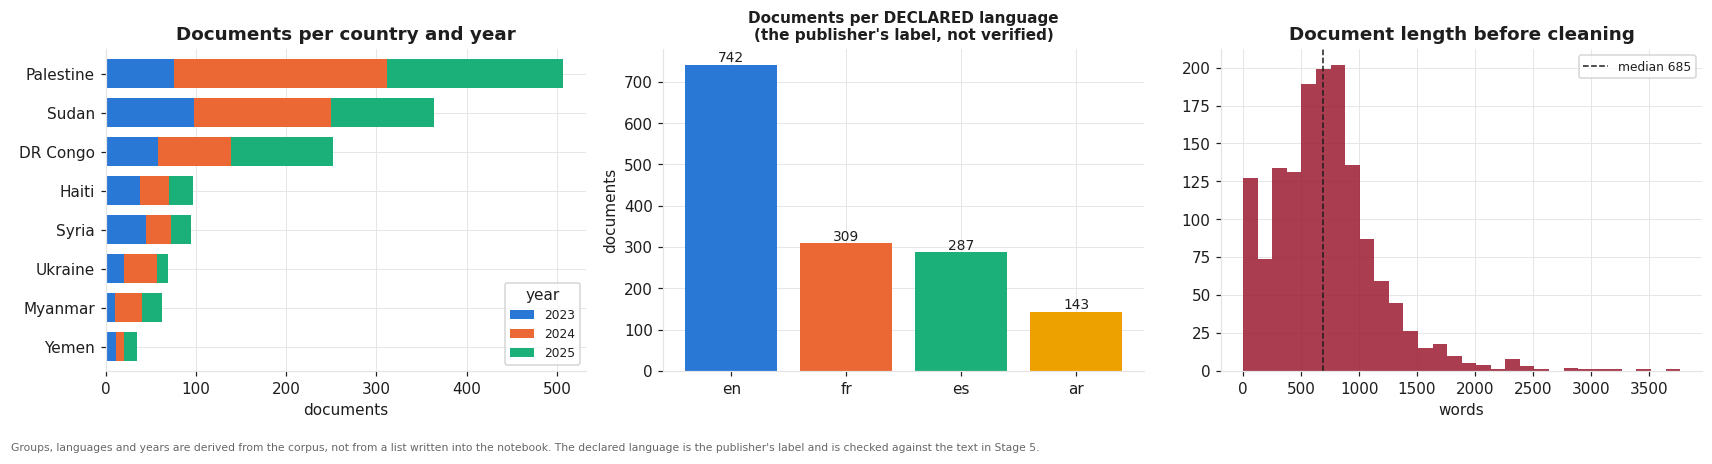


PRACTITIONER NOTE
  Describe a corpus rather than assuming it: require only the identifier and the text, turn every
  other column into a capability, and report what each missing one costs. Count every row that
  leaves, with the reason, in one ledger that runs from the file to the analysed set.


In [ ]:
# @title
# ==================================================================================================
# PHASE: DATA                                                           stage 1 of 5 in this phase
# STAGE 3  LOAD THE CORPUS
# WHAT THIS CELL DOES: reads the file, maps its columns, lists what the corpus can support
# ==================================================================================================
# WHAT THIS CELL DOES
#   Loads the raw corpus, maps its columns to the notebook's internal names, and derives which
#   downstream analyses this corpus supports. Every row that leaves the corpus from here on is
#   counted, with the reason, in one reconciliation ledger that runs to the analysed set.
#
# WHY
#   Only the identifier and the text are required; every other column becomes a capability, and
#   a stage that needs a missing one reports plainly that it was skipped rather than failing.

import os
import numpy as np, pandas as pd

# The ledger and ledger_step are defined in the library, so that notebook 2 can add a step to the
# same reconciliation without running this cell.

def load_corpus(path):
    if path.lower().endswith((".jsonl", ".json")):
        return pd.read_json(path, lines=path.lower().endswith(".jsonl"))
    return pd.read_csv(path)


df_raw = load_corpus(CFG.data_path)
N_RAW = report("corpus.rows_in_file", len(df_raw), "rows", "Stage 3")

# ---- rename the corpus's columns to the notebook's internal names -----------
# Nothing downstream ever refers to a column by the name it had in the file.
rename = {source: internal for internal, source in dict(CFG.column_map).items()
          if source and source in df_raw.columns}

# A column may already carry a name the map assigns to a different source column. Renaming over
# it would give two columns the same name, so it is moved aside rather than dropped.
_internal_names = set(dict(CFG.column_map))
_collisions = [column for column in df_raw.columns
               if column in _internal_names and rename.get(column) != column]
df = df_raw.rename(columns={c: f"{c}__from_file" for c in _collisions}).rename(columns=rename).copy()
if _collisions:
    print(f"  NOTE: {len(_collisions)} column(s) in the file share a name this notebook reserves.")
    for column in _collisions:
        print(f"    '{column}' kept as '{column}__from_file'; '{column}' now comes from "
              f"'{CFG.column(column)}'.")

_still_duplicated = [c for c in df.columns if list(df.columns).count(c) > 1]
assert not _still_duplicated, (
    f"Duplicate columns after mapping: {sorted(set(_still_duplicated))}. Fix COLUMN_MAP.")

missing_required = [name for name in ("doc_id", "text") if name not in df.columns]
if missing_required:
    raise KeyError(
        f"COLUMN_MAP points at a missing column: {missing_required}. Fix COLUMN_MAP in Stage 1."
    )

# ---- capabilities: what this corpus can and cannot support ------------------
def _usable(name):
    """A column counts as present only if it is mapped, in the file, and not entirely empty."""
    if name not in df.columns:
        return False
    return bool(df[name].notna().any())

CAPABILITIES = {
    "group_comparison":  _usable("group"),
    "group_labels":      _usable("group_label"),
    "multi_group_scope": _usable("group_all"),
    "time_trend":        _usable("year") or _usable("date"),
    "declared_language": _usable("lang_declared"),
    "document_type":     _usable("doc_type"),
    "external_labels":   _usable("external_label"),
    "titles":            _usable("title"),
}

CAPABILITY_CONSEQUENCE = {
    "group_comparison":  "every comparison between groups, and the group figures",
    "group_labels":      "readable names on figure axes; codes are used instead",
    "multi_group_scope": "the single-group and all-document sensitivity split",
    "time_trend":        "the change in each theme over time",
    "declared_language": "the declared-versus-detected language check",
    "document_type":     "reporting of which document types were dropped",
    "external_labels":   "external agreement against an independent label",
    "titles":            "titles beside quotations",
}

# ---- deduplicate on the identifier -----------------------------------------
duplicate_mask = df.duplicated(subset=["doc_id"], keep="first")
N_DUPLICATES = report("corpus.exact_duplicates", int(duplicate_mask.sum()), "documents", "Stage 3")
df = df.loc[~duplicate_mask].reset_index(drop=True)
ledger_step("exact duplicates", N_RAW, len(df),
            f"the same {CFG.column('doc_id')} appearing more than once")

# ---- flag blank text, HERE, where the sentence is printed -------------------
df["text"] = df["text"].fillna("").astype(str)
df["word_count_raw"] = df["text"].str.split().str.len()
df["blank_text"] = np.where(df["word_count_raw"] == 0, "YES", "")
N_BLANK = report("corpus.blank_text", int((df["blank_text"] == "YES").sum()),
                 "documents", "Stage 3")

# ---- derive the groups, languages and years from the data, never a list ----
GROUPS = (sorted(df["group"].dropna().astype(str).unique().tolist())
          if CAPABILITIES["group_comparison"] else [])
GROUP_LABELS = {}
if CAPABILITIES["group_comparison"] and CAPABILITIES["group_labels"]:
    GROUP_LABELS = (df.dropna(subset=["group"]).astype({"group": str})
                      .groupby("group")["group_label"]
                      .agg(lambda s: s.dropna().astype(str).mode().iloc[0]
                           if s.notna().any() else "")
                      .to_dict())

def group_label(code):
    """A readable name for a group, falling back to the code. No hard-coded list anywhere."""
    return GROUP_LABELS.get(str(code)) or str(code)

DECLARED_LANGUAGES = (sorted(df["lang_declared"].dropna().astype(str).unique().tolist())
                      if CAPABILITIES["declared_language"] else [])
# The year is derived once, here, and written into the frame, so the summary above and the
# figure below always agree.
YEARS = []
if CAPABILITIES["time_trend"]:
    if "year" in df.columns and df["year"].notna().any():
        df["year"] = pd.to_numeric(df["year"], errors="coerce")
    else:
        df["year"] = pd.to_datetime(df["date"], errors="coerce").dt.year
    YEARS = sorted(df["year"].dropna().astype(int).unique().tolist())
    if not YEARS:
        # A date column that parses to nothing is not a time trend, whatever the capability said.
        CAPABILITIES["time_trend"] = False
        print("  NOTE: no value in the date/year column parsed to a year; time trend unavailable.")

# ---- report -----------------------------------------------------------------
heading("STAGE 3  LOAD THE CORPUS")
print(f"  file                  : {CFG.data_path}")
print(f"  rows in the file      : {N_RAW:,}")
print(f"  exact duplicates      : {N_DUPLICATES}  (on {CFG.column('doc_id')})")
print(f"  documents             : {len(df):,}")
print(f"  blank {'text':<16}: {N_BLANK}  (flagged here; removed after cleaning, in Stage 4)")
if N_BLANK and CAPABILITIES["document_type"]:
    _types = df.loc[df["blank_text"] == "YES", "doc_type"].astype(str).value_counts()
    print(f"    their document types: "
          + ", ".join(f"{t} {n}" for t, n in _types.items()))
print()
print("  CAPABILITIES OF THIS CORPUS")
for name, available in CAPABILITIES.items():
    mark = "available" if available else "NOT AVAILABLE"
    print(f"    {name:<20} {mark}")
    if not available:
        print(f"      -> skipped: {CAPABILITY_CONSEQUENCE[name]}")
print()
if CAPABILITIES["group_comparison"]:
    print(f"  groups ({len(GROUPS)}), each one a {CFG.group_noun}:")
    for g in GROUPS:
        print(f"    {group_label(g)} [{g}]")
else:
    print(f"  no grouping column: this corpus is analysed as a single body of text.")
if DECLARED_LANGUAGES:
    print(f"  declared languages  : {', '.join(DECLARED_LANGUAGES)}")
    print("    NOT trusted. Stage 5 detects the language from the text and compares the two.")
if YEARS:
    print(f"  years               : {min(YEARS)} to {max(YEARS)}")
print(f"  words (raw)         : {int(df['word_count_raw'].sum()):,}")
rule()

report("corpus.documents_after_dedup", len(df), "documents", "Stage 3")
report("corpus.words_raw", int(df["word_count_raw"].sum()), "words", "Stage 3")
save_artifact("corpus_ids", set(df["doc_id"].astype(str)))

# ---- the figure -------------------------------------------------------------
_panels = 1 + int(CAPABILITIES["group_comparison"]) + int(bool(DECLARED_LANGUAGES))
fig, axes = plt.subplots(1, _panels, figsize=(5.2 * _panels, 4))
axes = np.atleast_1d(axes)
_i = 0

if CAPABILITIES["group_comparison"]:
    if YEARS:
        # groupby().size() counts rows regardless of column dtype. It reads df["year"], derived
        # once above.
        pivot = df.groupby(["group", "year"]).size().unstack(fill_value=0)
        pivot = pivot.loc[pivot.sum(axis=1).sort_values().index]
        pivot.index = [group_label(g) for g in pivot.index]
        pivot.plot(kind="barh", stacked=True, ax=axes[_i],
                   color=palette(pivot.shape[1]), width=0.75)
        axes[_i].legend(title="year", fontsize=8)
        axes[_i].set_title(f"Documents per {CFG.group_noun} and year")
    else:
        counts = df["group"].astype(str).value_counts().sort_values()
        axes[_i].barh([group_label(g) for g in counts.index], counts.values, color=ACCENT)
        axes[_i].set_title(f"Documents per {CFG.group_noun}")
    axes[_i].set_xlabel("documents"); axes[_i].set_ylabel("")
    _i += 1

if DECLARED_LANGUAGES:
    counts = df["lang_declared"].astype(str).value_counts()
    axes[_i].bar(counts.index, counts.values, color=palette(len(counts)))
    for position, value in enumerate(counts.values):
        axes[_i].text(position, value, str(value), ha="center", va="bottom", fontsize=9)
    axes[_i].set_title("Documents per DECLARED language\n(the publisher's label, not verified)",
                       fontsize=10)
    axes[_i].set_ylabel("documents")
    _i += 1

axes[_i].hist(df["word_count_raw"], bins=30, color=ACCENT, alpha=0.85)
axes[_i].axvline(df["word_count_raw"].median(), color=INK, ls="--", lw=1,
                 label=f"median {int(df['word_count_raw'].median())}")
axes[_i].set_title("Document length before cleaning"); axes[_i].set_xlabel("words")
axes[_i].legend(fontsize=8)

fig.tight_layout()
add_reference_footer(fig, "Groups, languages and years are derived from the corpus, not from a list "
                         "written into the notebook. The declared language is the publisher's "
                         "label and is checked against the text in Stage 5.")
save_figure(fig, "s03_corpus_overview"); plt.show()

practitioner_note("Load and declare", """
Describe a corpus rather than assuming it: require only the identifier and the text, turn every
other column into a capability, and report what each missing one costs. Count every row that
leaves, with the reason, in one ledger that runs from the file to the analysed set.
""")

## Stage 4: cleaning   [phase: data]

**What.** Removes what is not reporting: links, e-mail addresses, photo credits, footnote blocks,
Markdown marks and repeated boilerplate. The words themselves are kept. The raw text is never
modified; cleaning writes a new column.

**Output.** A cleaning ledger: for each rule, how many documents it changed and how many characters it
removed, including rules that found nothing. **Stage 4b** then flags near-copies of the same document.

  STAGE 4  CLEANING
  the raw text column is never modified. Cleaning writes 'text_clean'.

  C1      146 documents,       899 characters removed   [unicode NFKC, zero-width spaces removed, whitespace collapsed]
    --- C1 example ---
    BEFORE: ...l-issues/mental-health "Mental health"). The ​desert region​, located in​​ the southern West Bank in the [Occu
    AFTER : ...l-issues/mental-health "Mental health"). The desert region, located in the southern West Bank in the [Occupied
    --- C1 example ---
    BEFORE: ...no de los cuidadores que se encontaban allí. ​ ​​ ​ ​Este hospital **era uno de los pocos centros pediáticos q
    AFTER : ...no de los cuidadores que se encontaban allí. Este hospital **era uno de los pocos centros pediáticos que había
        zero-width spaces removed: 512 in 85 document(s)
  C2        0 documents,         0 characters removed   [publisher attachment header]
        found nothing to change: the pattern is not present in this corpus.
  C3        9 docum

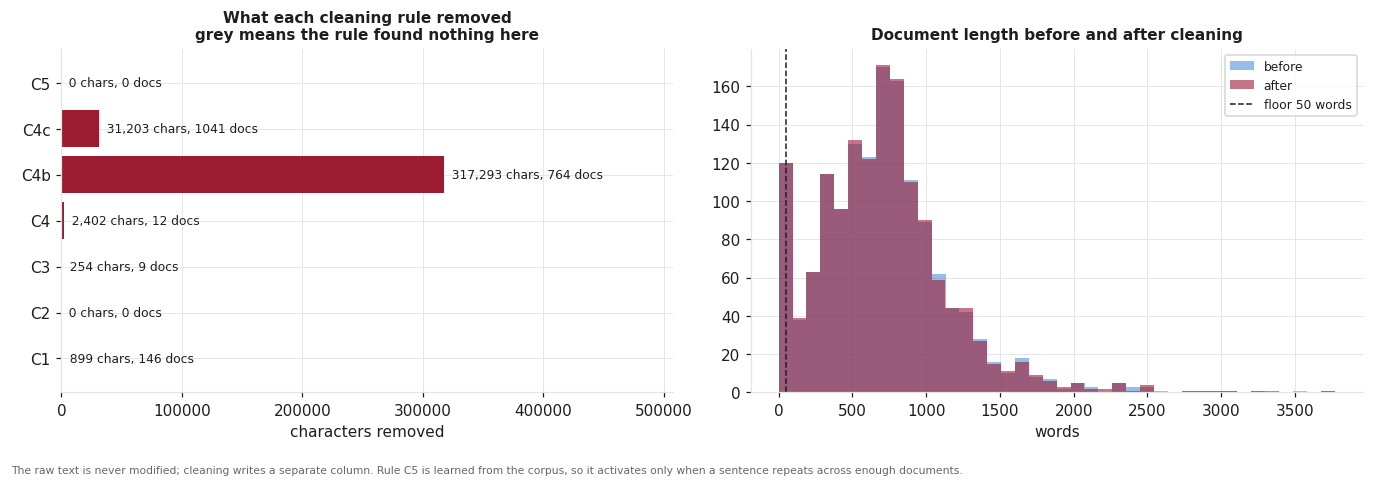


PRACTITIONER NOTE
  Publish a cleaning ledger with every text analysis: which rule ran, how many documents and
  characters it touched, and whether it found anything at all. State in words when a rule removed
  nothing, because a zero in a table looks the same whether the rule found nothing or never ran.


In [ ]:
# @title
# ==================================================================================================
# PHASE: DATA                                                           stage 2 of 5 in this phase
# STAGE 4  CLEANING
# WHAT THIS CELL DOES: removes links, markup and credits; keeps a ledger of every change
# ==================================================================================================
# WHAT THIS CELL DOES
#   Applies a sequence of text-cleaning rules (unicode, links, markup, learned boilerplate) to
#   the raw text and writes the result to a separate column, never modifying the raw text itself.
#
# WHY
#   Every rule reports how many documents and characters it changed, so a reader can judge how
#   much each rule mattered. A rule that changes nothing on this corpus is a result, not a
#   failure, and the ledger says so in words rather than leaving a bare zero that could mean either.

import re, unicodedata, collections
import numpy as np, pandas as pd

CLEANING_LEDGER = []

def cleaning_record(rule, description, documents_changed, characters_removed, outcome):
    CLEANING_LEDGER.append({
        "rule": rule, "description": description,
        "documents_changed": int(documents_changed),
        "characters_removed": int(characters_removed),
        "outcome": outcome,
    })

def apply_rule(series, function, rule, description, examples=2):
    before = series
    after = series.map(function)
    changed = (before != after)
    removed = int((before.str.len() - after.str.len()).clip(lower=0).sum())
    outcome = "no change on this corpus" if changed.sum() == 0 else "applied"
    cleaning_record(rule, description, changed.sum(), removed, outcome)
    print(f"  {rule:<5} {int(changed.sum()):>5} documents, {removed:>9,} characters removed"
          f"   [{description}]")
    if changed.sum() == 0:
        print(f"        found nothing to change: the pattern is not present in this corpus.")
    shown = 0
    for index in changed[changed].index:
        if shown >= examples:
            break
        if len(before.loc[index]) - len(after.loc[index]) > 20:
            show_text_diff(before.loc[index], after.loc[index], label=f"{rule} example")
            shown += 1
    return after


text = df["text"].fillna("").astype(str)
LENGTH_BEFORE = int(text.str.len().sum())

heading("STAGE 4  CLEANING")
print(f"  the raw text column is never modified. Cleaning writes 'text_clean'.")
print()

# ---- C1 unicode and whitespace ---------------------------------------------
ZERO_WIDTH = "​"
zero_width_before = int(text.str.count(ZERO_WIDTH).sum())
zero_width_documents = int((text.str.count(ZERO_WIDTH) > 0).sum())

def rule_unicode(s):
    # NFKC maps a non-breaking space to a plain space, so no separate rule for it is needed.
    # A zero-width space survives NFKC and is not matched by \s, so it is removed explicitly.
    s = unicodedata.normalize("NFKC", s).replace(ZERO_WIDTH, "")
    return re.sub(r"\s+", " ", s).strip()

text = apply_rule(text, rule_unicode, "C1",
                  "unicode NFKC, zero-width spaces removed, whitespace collapsed")
print(f"        zero-width spaces removed: {zero_width_before:,} "
      f"in {zero_width_documents} document(s)")
report("cleaning.zero_width_removed", zero_width_before, "characters", "Stage 4")

# ---- C2 attachment headers --------------------------------------------------
ATTACHMENT = re.compile(
    r"^\s*Attachments?\s+Download\s+Report\s*\([^)]*\)\s*(?:Download\s+Report\s*\([^)]*\)\s*)*",
    re.IGNORECASE)
text = apply_rule(text, lambda s: ATTACHMENT.sub("", s).strip(),
                  "C2", "publisher attachment header")

# ---- C3 photo credits -------------------------------------------------------
CREDIT = re.compile(r"(?:©|\(c\))\s*[^.©]{0,80}?"
                    r"(?:/\s*MSF|MSF\s*/|/\s*M[eé]decins[^.]{0,40})", re.IGNORECASE)
text = apply_rule(text, lambda s: re.sub(r"\s+", " ", CREDIT.sub(" ", s)).strip(),
                  "C3", "photo credit lines")

# ---- C4 trailing footnote and link blocks ----------------------------------
FOOTNOTES = re.compile(r"(?:\[\d+\]\s*https?://\S+\s*)+$")
URL_TAIL   = re.compile(r"(?:https?://\S+\s*){2,}$")
text = apply_rule(text, lambda s: URL_TAIL.sub("", FOOTNOTES.sub("", s)).strip(),
                  "C4", "trailing footnote and link blocks")

# ---- C4b links --------------------------------------------------------------
# A naive URL pattern swallows a following bracket or word when there is no space. Markdown
# links are therefore unwrapped first, keeping their visible text; the bare-URL pattern stops at
# brackets and quotation marks.
MARKDOWN_LINK = re.compile(
    r"\[([^\]]*)\]\(\s*<?(?:https?://|www\.)[^\s)\"']+>?(?:\s+\"[^\"]*\")?\s*\)")
BARE_URL = re.compile(r"(?:https?://|www\.)[^\s)\]\"'<>]+", re.IGNORECASE)
EMAIL    = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b")

def rule_links(s):
    s = MARKDOWN_LINK.sub(r"\1", s)
    s = BARE_URL.sub(" ", s)
    s = EMAIL.sub(" ", s)
    s = re.sub(r"\[\s*\]|\(\s*\)", " ", s)
    return re.sub(r"\s+", " ", s).strip()

text = apply_rule(text, rule_links, "C4b",
                  "markdown links unwrapped, bare URLs and addresses removed")

# ---- C4c markup left by the export ------------------------------------------
# Markup carries no content, and a marker more frequent in one language becomes a language signal
# fed to the embedding. Only the marks are removed; the orphan "[" left by C4 is removed too.
MARKUP_ESCAPE = re.compile(r"\\([\\`*_{}\[\]()#+\-.!|>~])")
MARKUP_EMPHASIS = re.compile(r"\*{2,}|_{2,}")
MARKUP_HEADING = re.compile(r"(?:(?<=\s)|^)#{1,6}(?=\s)")
MARKUP_PIPE = re.compile(r"\s*\|\s*")
ORPHAN_BRACKET = re.compile(r"(?:(?<=\s)|^)[\[\]](?=\s|$)")

def rule_markup(s):
    s = MARKUP_ESCAPE.sub(r"\1", s)
    s = MARKUP_EMPHASIS.sub("", s)
    s = MARKUP_HEADING.sub(" ", s)
    s = MARKUP_PIPE.sub(" ", s)
    s = ORPHAN_BRACKET.sub(" ", s)
    return re.sub(r"\s+", " ", s).strip()

text = apply_rule(text, rule_markup, "C4c", "markdown emphasis, headings, escapes and table bars")

# ---- C5 boilerplate learned from the corpus --------------------------------
def split_sentences(s):
    """Returns every sentence; filtering here would delete short factual sentences that belong
    in the rejoined text."""
    return [part.strip() for part in re.split(r"(?<=[.!?])\s+", s) if part.strip()]

def boilerplate_candidates(s):
    return [p for p in split_sentences(s) if len(p) > CFG.boilerplate_min_sentence_chars]

sentence_document_count = collections.Counter()
for document in text:
    for sentence in set(boilerplate_candidates(document)):
        sentence_document_count[re.sub(r"\d+", "#", sentence.lower())] += 1

THRESHOLD_DOCUMENTS = max(3, int(CFG.boilerplate_min_doc_fraction * len(text)))
MOST_REPEATED = max(sentence_document_count.values()) if sentence_document_count else 0
BOILERPLATE = {s for s, count in sentence_document_count.items()
               if count >= THRESHOLD_DOCUMENTS}

print(f"  C5    threshold: a sentence longer than {CFG.boilerplate_min_sentence_chars} characters "
      f"appearing in at least")
print(f"        {THRESHOLD_DOCUMENTS} of {len(text)} documents "
      f"({CFG.boilerplate_min_doc_fraction:.0%})")
print(f"        most repeated sentence appears in {MOST_REPEATED} document(s)")
print(f"        patterns learned: {len(BOILERPLATE)}")

def rule_boilerplate(s):
    if not BOILERPLATE:
        return s
    kept = [p for p in split_sentences(s)
            if len(p) <= CFG.boilerplate_min_sentence_chars
            or re.sub(r"\d+", "#", p.lower()) not in BOILERPLATE]
    return " ".join(kept) if kept else s          # never empty a document entirely

text = apply_rule(text, rule_boilerplate, "C5", "organisational boilerplate, learned")
if not BOILERPLATE:
    print(f"        C5 removed nothing: no sentence repeats across {THRESHOLD_DOCUMENTS}+ "
          f"documents. State this in the limitations.")
report("cleaning.boilerplate_patterns", len(BOILERPLATE), "patterns", "Stage 4")
report("cleaning.most_repeated_sentence", MOST_REPEATED, "documents", "Stage 4")

# ---- write the cleaned column, flag what is too short ----------------------
df["text_clean"] = text.values
df["word_count_clean"] = df["text_clean"].str.split().str.len()
df["too_short_after_cleaning"] = np.where(
    df["word_count_clean"] < CFG.min_words_after_cleaning, "YES", "")
N_TOO_SHORT = int((df["too_short_after_cleaning"] == "YES").sum())

LENGTH_AFTER = int(df["text_clean"].str.len().sum())
ledger = pd.DataFrame(CLEANING_LEDGER)
ledger["percent_of_all_characters"] = (
    ledger["characters_removed"] / max(1, LENGTH_BEFORE) * 100).round(2)

print()
print("  CLEANING LEDGER")
print(ledger.to_string(index=False))
print()
print(f"  characters before   : {LENGTH_BEFORE:,}")
print(f"  characters after    : {LENGTH_AFTER:,}")
print(f"  net reduction       : {100 * (1 - LENGTH_AFTER / max(1, LENGTH_BEFORE)):.1f}%")
print(f"  below {CFG.min_words_after_cleaning} words after cleaning : {N_TOO_SHORT} "
      f"(of which {int((df['blank_text'] == 'YES').sum())} were blank in the file)")
ledger.to_csv(os.path.join(FIGURE_DIR, "cleaning_ledger.csv"), index=False)
report("cleaning.characters_before", LENGTH_BEFORE, "characters", "Stage 4")
report("cleaning.characters_after", LENGTH_AFTER, "characters", "Stage 4")
report("cleaning.too_short_after", N_TOO_SHORT, "documents", "Stage 4")
rule()

# ---- figures ----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].barh(ledger["rule"], ledger["characters_removed"],
             color=[ACCENT if o == "applied" else "#C4C4C4" for o in ledger["outcome"]])
for position, row in enumerate(ledger.itertuples()):
    axes[0].text(row.characters_removed, position,
                 f"  {row.characters_removed:,} chars, {row.documents_changed} docs",
                 va="center", fontsize=8)
axes[0].set_xlabel("characters removed")
axes[0].set_xlim(0, max(1, ledger["characters_removed"].max()) * 1.6)
axes[0].set_title("What each cleaning rule removed\ngrey means the rule found nothing here",
                  fontsize=10)

axes[1].hist(df["word_count_raw"], bins=40, alpha=0.6, label="before", color="#5390D9")
axes[1].hist(df["word_count_clean"], bins=40, alpha=0.6, label="after", color=ACCENT)
axes[1].axvline(CFG.min_words_after_cleaning, color=INK, ls="--", lw=1,
                label=f"floor {CFG.min_words_after_cleaning} words")
axes[1].set_title("Document length before and after cleaning", fontsize=10)
axes[1].set_xlabel("words"); axes[1].legend(fontsize=8)
fig.tight_layout()
add_reference_footer(fig, "The raw text is never modified; cleaning writes a separate column. "
                         "Rule C5 is learned from the corpus, so it activates only when a "
                         "sentence repeats across enough documents.")
save_figure(fig, "s04_cleaning"); plt.show()

practitioner_note("Cleaning", """
Publish a cleaning ledger with every text analysis: which rule ran, how many documents and
characters it touched, and whether it found anything at all. State in words when a rule removed
nothing, because a zero in a table looks the same whether the rule found nothing or never ran.
""")

  STAGE 4b  NEAR-DUPLICATES
  documents compared    : 1,362
  method                : exact cosine matrix   (exact is used at or below 5,000 documents)
  threshold             : similarity at or above 0.9
  pairs found           : 44
  documents flagged     : 44  (3.2% of the analysed set)
    both in the same country : 43
    in two different ones    : 1
    only a cross-group pair can move a comparison between groups.
    0.965  [COD] Year in Review 2024
           [PSE] Year in review: How MSF responded to world crises in

  NOTHING IS DELETED. Whether a republished document counts once or twice is a decision
  for the analyst; the flag travels with the document into every later stage.
  ANALYSIS SET: 1,362 documents, 1,052,898 words.
  Language is NOT a filter. Every language in the corpus is analysed.
  figure saved: s04b_near_duplicates (PNG, SVG; local and Drive)


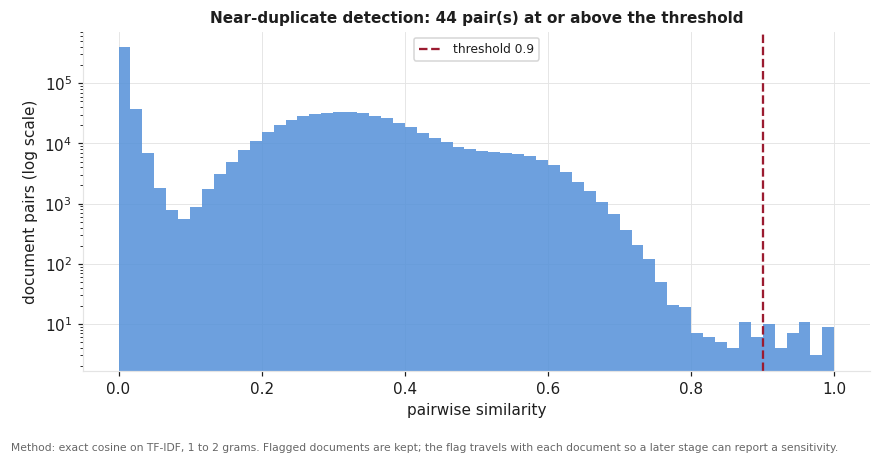


PRACTITIONER NOTE
  The same release is often republished under several headings. Flag such documents rather than
  deleting them, since deleting could remove real information. Report pairs inside one group
  separately from pairs that cross groups: only the second kind can move a comparison.


In [ ]:
# @title
# ==================================================================================================
# PHASE: DATA                                                           stage 3 of 5 in this phase
# STAGE 4b  NEAR-DUPLICATES
# WHAT THIS CELL DOES: finds near-copies of the same document
# ==================================================================================================
# WHAT THIS CELL DOES
#   Finds near-duplicate documents (the same release republished under a different heading) and
#   flags them; nothing is deleted. The flag travels with the document into every later stage.
#
# WHY
#   Whether a republished document should count once or twice is a decision for the analyst, not
#   this cell. Pairs within one group and pairs across groups are reported separately, because
#   only a cross-group pair can move a comparison between groups.
#
# HOW
#   Below a document-count threshold, pairwise cosine similarity on a TF-IDF matrix finds every
#   pair; above it, MinHash with locality-sensitive hashing approximates the same pairs without
#   building the full matrix.

import os
import numpy as np, pandas as pd

heading("STAGE 4b  NEAR-DUPLICATES")

analysed = df[df["too_short_after_cleaning"] != "YES"].reset_index(drop=True)
texts = analysed["text_clean"].fillna("").tolist()
N = len(texts)

USE_EXACT = N <= CFG.near_duplicate_exact_max_docs
print(f"  documents compared    : {N:,}")
print(f"  method                : {'exact cosine matrix' if USE_EXACT else 'MinHash with LSH'}"
      f"   (exact is used at or below {CFG.near_duplicate_exact_max_docs:,} documents)")
print(f"  threshold             : similarity at or above {CFG.near_duplicate_threshold}")

pairs = []
SIMILARITY_SAMPLE = None

if USE_EXACT:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity
    matrix = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=1).fit_transform(texts)
    similarity = cosine_similarity(matrix)
    np.fill_diagonal(similarity, 0.0)
    SIMILARITY_SAMPLE = similarity[np.triu_indices_from(similarity, k=1)]
    for i, j in np.argwhere(similarity >= CFG.near_duplicate_threshold):
        if i < j:
            pairs.append((int(i), int(j), float(similarity[i, j])))
    METHOD = "exact cosine on TF-IDF, 1 to 2 grams"
else:
    try:
        from datasketch import MinHash, MinHashLSH
        import re as _re
        def shingles(document, width=5):
            words = _re.findall(r"\w+", document.lower())
            return {" ".join(words[k:k + width]) for k in range(max(1, len(words) - width + 1))}
        signatures = []
        index = MinHashLSH(threshold=CFG.near_duplicate_threshold, num_perm=128)
        for position, document in enumerate(texts):
            signature = MinHash(num_perm=128)
            for shingle in shingles(document):
                signature.update(shingle.encode("utf8"))
            signatures.append(signature)
            index.insert(str(position), signature)
        seen = set()
        for position, signature in enumerate(signatures):
            for other in index.query(signature):
                a, b = sorted((position, int(other)))
                if a != b and (a, b) not in seen:
                    seen.add((a, b))
                    pairs.append((a, b, float(signatures[a].jaccard(signatures[b]))))
        METHOD = "MinHash with LSH, 5-word shingles, 128 permutations"
    except ImportError:
        print("  WARNING: datasketch is not installed; the approximate method is unavailable.")
        print(f"  The exact matrix would need roughly {N * N * 8 / 1e9:.1f} GB; not attempted.")
        print("  Detection is SKIPPED. Install datasketch and re-run, or state in the")
        print("  limitations that near-duplicates were not measured.")
        METHOD = "skipped: datasketch unavailable and the corpus is too large for the exact method"

# ---- flag, and carry ---------------------------------------------------------
analysed["near_duplicate_flag"] = ""
analysed["near_duplicate_of"] = ""
analysed["near_duplicate_similarity"] = np.nan
for i, j, score in pairs:
    analysed.at[j, "near_duplicate_flag"] = "YES"
    analysed.at[j, "near_duplicate_of"] = str(analysed.at[i, "doc_id"])
    analysed.at[j, "near_duplicate_similarity"] = round(score, 3)

N_FLAGGED = int((analysed["near_duplicate_flag"] == "YES").sum())

# ---- within a group, or across groups? --------------------------------------
CROSS_GROUP_PAIRS = []
if CAPABILITIES["group_comparison"]:
    for i, j, score in pairs:
        if str(analysed.at[i, "group"]) != str(analysed.at[j, "group"]):
            CROSS_GROUP_PAIRS.append((i, j, score))

print(f"  pairs found           : {len(pairs)}")
print(f"  documents flagged     : {N_FLAGGED}  "
      f"({100 * N_FLAGGED / max(1, N):.1f}% of the analysed set)")
if CAPABILITIES["group_comparison"]:
    print(f"    both in the same {CFG.group_noun} : {len(pairs) - len(CROSS_GROUP_PAIRS)}")
    print(f"    in two different ones    : {len(CROSS_GROUP_PAIRS)}")
    print("    only a cross-group pair can move a comparison between groups.")
    def _describe(position):
        """A short label for a document: its title when the corpus has one, else its identifier."""
        if "title" in analysed.columns and pd.notna(analysed.at[position, "title"]):
            return str(analysed.at[position, "title"])[:52]
        return str(analysed.at[position, "doc_id"])[:52]

    for i, j, score in CROSS_GROUP_PAIRS[:5]:
        print(f"    {score:.3f}  [{analysed.at[i, 'group']}] {_describe(i)}")
        print(f"           [{analysed.at[j, 'group']}] {_describe(j)}")

print()
print("  NOTHING IS DELETED. Whether a republished document counts once or twice is a decision")
print("  for the analyst; the flag travels with the document into every later stage.")
rule()

report("near_duplicates.pairs", len(pairs), "pairs", "Stage 4b")
report("near_duplicates.documents_flagged", N_FLAGGED, "documents", "Stage 4b")
report("near_duplicates.cross_group_pairs", len(CROSS_GROUP_PAIRS), "pairs", "Stage 4b")
cleaning_record("C6", f"near-duplicates flagged ({METHOD})", N_FLAGGED, 0,
                "flagged, none deleted")

# ---- the analysis set --------------------------------------------------------
ledger_step("too short after cleaning", len(df), len(analysed),
            f"fewer than {CFG.min_words_after_cleaning} words once cleaned "
            f"(includes every blank field)")
df_analysis = analysed
report("corpus.analysed_documents", len(df_analysis), "documents", "Stage 4b")
report("corpus.analysed_words", int(df_analysis["word_count_clean"].sum()), "words", "Stage 4b")

print(f"  ANALYSIS SET: {len(df_analysis):,} documents, "
      f"{int(df_analysis['word_count_clean'].sum()):,} words.")
print(f"  Language is NOT a filter. Every language in the corpus is analysed.")
rule()

# ---- figure -----------------------------------------------------------------
if SIMILARITY_SAMPLE is not None and len(SIMILARITY_SAMPLE):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(SIMILARITY_SAMPLE, bins=60, color="#5390D9", alpha=0.85)
    ax.axvline(CFG.near_duplicate_threshold, color=ACCENT, ls="--", lw=1.5,
               label=f"threshold {CFG.near_duplicate_threshold}")
    ax.set_yscale("log")
    ax.set_xlabel("pairwise similarity"); ax.set_ylabel("document pairs (log scale)")
    ax.set_title(f"Near-duplicate detection: {len(pairs)} pair(s) at or above the threshold",
                 fontsize=10)
    ax.legend(fontsize=8)
    fig.tight_layout()
    add_reference_footer(fig, f"Method: {METHOD}. Flagged documents are kept; the flag travels "
                             f"with each document so a later stage can report a sensitivity.")
    save_figure(fig, "s04b_near_duplicates"); plt.show()

practitioner_note("Near-duplicates", """
The same release is often republished under several headings. Flag such documents rather than
deleting them, since deleting could remove real information. Report pairs inside one group
separately from pairs that cross groups: only the second kind can move a comparison.
""")

## Stage 5: language   [phase: data]

**What.** Detects the language of each document from its own text. The publisher's label is not
trusted: 143 documents labelled Arabic are in English.

**Method.** Lingua, a detector built for short and mixed text. The label is decided on the whole
document and carried to its passages.

  STAGE 5  LANGUAGE
  detector in use       : lingua, all languages, preloaded models
  decided at            : document level, then carried to every passage
  documents             : 1,362

  DETECTED languages:
    en          829  (60.9%)
    es          285  (20.9%)
    fr          247  (18.1%)
    de            1  (0.1%)

  DECLARED against DETECTED, on the analysed set. Both counts are over the same
  1,362 documents, so they are directly comparable.
detected  de   en   es   fr
declared                   
ar         0  143    0    0
en         0  685    0    0
es         1    1  285    0
fr         0    0    0  247

  the two labels agree on 1,217 of 1,362 documents (89.4%)
    MOST documents declared 'ar' are detected as 'en' (143 of 143).
      These are bilingual records: the publisher lists the report under
      both languages while serving the English body, so the declared label
      means 'a version exists', not 'this text is in it'.

  the primary detector and the heuris

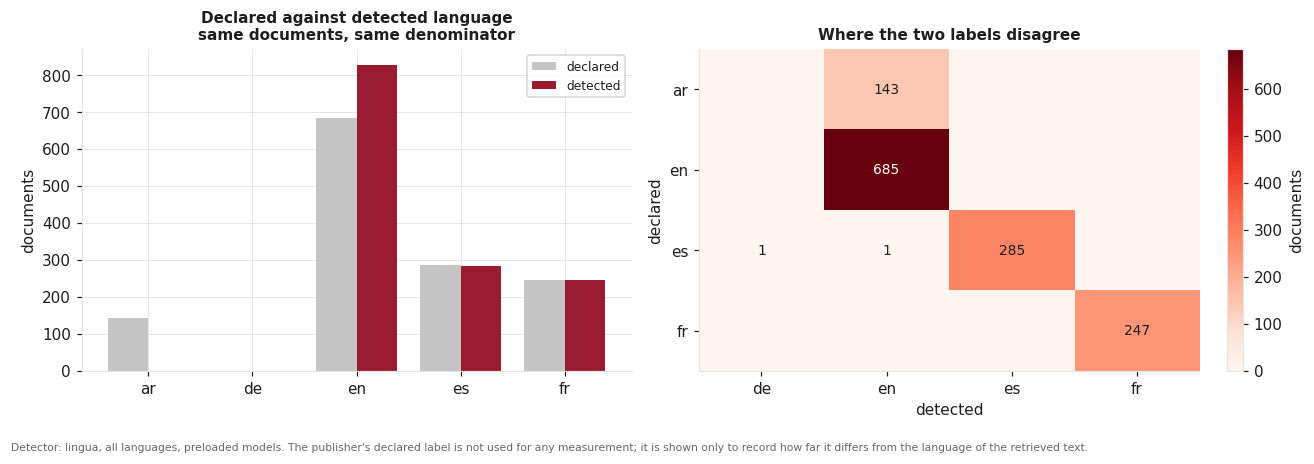


PRACTITIONER NOTE
  Detect the language from the text; never trust the label that came with the file. Decide the
  label once, on the whole document, and carry it everywhere. Make every cross-language check
  announce itself as not applicable when the corpus holds only one language.


In [ ]:
# @title
# ==================================================================================================
# PHASE: DATA                                                           stage 4 of 5 in this phase
# STAGE 5  LANGUAGE
# WHAT THIS CELL DOES: detects each document's language from its text
# ==================================================================================================
# WHAT THIS CELL DOES
#   Detects the language of each document from its cleaned text, before any stage that depends on
#   language runs. A word-frequency heuristic is kept alongside the primary detector for
#   comparison, and both results are reported.
#
# WHY
#   A publisher's declared language label can name a language the retrieved text is not written
#   in: this corpus contains documents labelled Arabic whose retrieved body is entirely English.
#   The label is decided once, on the whole document, and carried to every later stage.
#
# HOW
#   Language is detected with Lingua, a detector built for short and mixed-language text that
#   needs no training step.
#
# REFERENCES
#   Stahl, P. lingua-py. https://pypi.org/project/lingua-language-detector/

import re
import numpy as np, pandas as pd

# ---- word-frequency heuristic, kept for comparison ---------------------------
FRENCH_MARKERS  = re.compile(r"\b(les|des|une|dans|nous|pour|avec|sont|cette|leurs)\b", re.I)
SPANISH_MARKERS = re.compile(r"\b(los|las|una|para|con|que|del|como|más|también)\b", re.I)
ARABIC_RANGE    = re.compile(r"[؀-ۿ]")

def detect_language_heuristic(text):
    """A word-frequency heuristic, retained only for comparison with the primary detector."""
    text = str(text)
    word_characters = max(1, len(re.findall(r"\w", text)))
    if len(ARABIC_RANGE.findall(text)) / word_characters > 0.15:
        return "ar"
    french, spanish = len(FRENCH_MARKERS.findall(text)), len(SPANISH_MARKERS.findall(text))
    if max(french, spanish) < 8:
        return "en"
    return "fr" if french > spanish else "es"

# ---- the detector in use -----------------------------------------------------
DETECTOR_NAME = "heuristic (ten function words per language, absolute threshold)"
_lingua = None
try:
    from lingua import LanguageDetectorBuilder
    _lingua = (LanguageDetectorBuilder.from_all_languages()
               .with_preloaded_language_models().build())
    DETECTOR_NAME = "lingua, all languages, preloaded models"
except Exception as exc:
    print(f"  lingua is unavailable ({type(exc).__name__}); using the word-frequency heuristic.")
    print("  Record this in the limitations: only English, French, Spanish and Arabic script can")
    print("  be recognised, and short text is biased towards English.")

def detect_language(text):
    if _lingua is None:
        return detect_language_heuristic(text)
    result = _lingua.detect_language_of(str(text)[:4000])
    return result.iso_code_639_1.name.lower() if result is not None else "unknown"

# ---- detect on the whole document, not on a fragment ------------------------
# A document carries more evidence than any one passage, and the label is a property of the
# document, so it is decided once, here, and carried down to every passage.
df_analysis["detected_language"] = df_analysis["text_clean"].map(detect_language)
df_analysis["heuristic_language"] = df_analysis["text_clean"].map(detect_language_heuristic)

DETECTED_COUNTS = df_analysis["detected_language"].value_counts()
N_LANGUAGES = report("language.distinct_detected", int(DETECTED_COUNTS.size),
                     "languages", "Stage 5")
MULTILINGUAL = N_LANGUAGES > 1

heading("STAGE 5  LANGUAGE")
print(f"  detector in use       : {DETECTOR_NAME}")
print(f"  decided at            : document level, then carried to every passage")
print(f"  documents             : {len(df_analysis):,}")
print()
print("  DETECTED languages:")
for language, count in DETECTED_COUNTS.items():
    print(f"    {language:<8} {count:>6}  ({100 * count / len(df_analysis):.1f}%)")
report("language.multilingual_corpus", int(MULTILINGUAL), "true or false", "Stage 5")

# ---- the declared label, and how far it is wrong ----------------------------
if CAPABILITIES["declared_language"]:
    declared = df_analysis["lang_declared"].astype(str)
    crosstab = pd.crosstab(declared, df_analysis["detected_language"])
    crosstab.index.name = "declared"; crosstab.columns.name = "detected"
    print()
    print("  DECLARED against DETECTED, on the analysed set. Both counts are over the same")
    print(f"  {len(df_analysis):,} documents, so they are directly comparable.")
    print(crosstab.to_string())
    agree = int(sum(crosstab.loc[label, label] for label in crosstab.index
                    if label in crosstab.columns))
    print(f"\n  the two labels agree on {agree:,} of {len(df_analysis):,} documents "
          f"({100 * agree / len(df_analysis):.1f}%)")
    report("language.declared_detected_agreement", agree, "documents", "Stage 5")

    for declared_label in crosstab.index:
        row = crosstab.loc[declared_label]
        elsewhere = int(row.sum() - (row.get(declared_label, 0)))
        if elsewhere and elsewhere >= 0.5 * row.sum():
            moved_to = row.drop(labels=[declared_label], errors="ignore").idxmax()
            print(f"    MOST documents declared '{declared_label}' are detected as "
                  f"'{moved_to}' ({elsewhere} of {int(row.sum())}).")
            if declared_label == "ar":
                print("      These are bilingual records: the publisher lists the report under")
                print("      both languages while serving the English body, so the declared label")
                print("      means 'a version exists', not 'this text is in it'.")

# ---- how far the two detectors disagree -------------------------------------
if _lingua is not None:
    disagree = df_analysis[df_analysis["detected_language"] != df_analysis["heuristic_language"]]
    print()
    print(f"  the primary detector and the heuristic disagree on {len(disagree):,} "
          f"of {len(df_analysis):,} documents ({100 * len(disagree) / len(df_analysis):.1f}%)")
    if len(disagree):
        movement = (disagree.groupby(["heuristic_language", "detected_language"])
                            .size().sort_values(ascending=False).head(8))
        print("    the largest differences, heuristic -> detected:")
        for (was, now), count in movement.items():
            print(f"      {was} -> {now}   {count}")
    report("language.detector_disagreements", len(disagree), "documents", "Stage 5")

# ---- the gate that depends on this -----------------------------------------
print()
if MULTILINGUAL:
    print(f"  This corpus holds {N_LANGUAGES} languages, so the cross-language checks APPLY:")
    print("    a theme must not simply reproduce the language a document was written in.")
else:
    print("  This corpus holds ONE language, so every cross-language check is NOT APPLICABLE and")
    print("  will report itself as such rather than running anyway.")
rule()

# ---- figure -----------------------------------------------------------------
if _lingua is not None and CAPABILITIES["declared_language"]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    counts = pd.DataFrame({
        "declared": df_analysis["lang_declared"].astype(str).value_counts(),
        "detected": DETECTED_COUNTS,
    }).fillna(0)
    counts.plot(kind="bar", ax=axes[0], color=["#C4C4C4", ACCENT], width=0.78)
    axes[0].set_title("Declared against detected language\nsame documents, same denominator",
                      fontsize=10)
    axes[0].set_ylabel("documents"); axes[0].set_xlabel("")
    axes[0].tick_params(axis="x", rotation=0); axes[0].legend(fontsize=8)

    matrix = pd.crosstab(df_analysis["lang_declared"].astype(str),
                         df_analysis["detected_language"])
    image = axes[1].imshow(matrix.values, cmap="Reds", aspect="auto")
    axes[1].set_xticks(range(matrix.shape[1])); axes[1].set_xticklabels(matrix.columns)
    axes[1].set_yticks(range(matrix.shape[0])); axes[1].set_yticklabels(matrix.index)
    axes[1].set_xlabel("detected"); axes[1].set_ylabel("declared")
    axes[1].set_title("Where the two labels disagree", fontsize=10)
    axes[1].grid(False)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix.values[row, column]
            if value:
                axes[1].text(column, row, str(value), ha="center", va="center", fontsize=9,
                             color="white" if value > matrix.values.max() * 0.55 else INK)
    fig.colorbar(image, ax=axes[1], fraction=0.04, label="documents")
    fig.tight_layout()
    add_reference_footer(fig, f"Detector: {DETECTOR_NAME}. The publisher's declared label is not "
                             f"used for any measurement; it is shown only to record how far it "
                             f"differs from the language of the retrieved text.")
    save_figure(fig, "s05_language"); plt.show()

practitioner_note("Language", """
Detect the language from the text; never trust the label that came with the file. Decide the
label once, on the whole document, and carry it everywhere. Make every cross-language check
announce itself as not applicable when the corpus holds only one language.
""")

## Stage 5a: one version per story   [phase: data]

**What.** Finds translations: the same release published in English, French and Spanish. A *story*
is a release together with its translations and near-copies. The analysis keeps **one version per
story** (English when it exists), so one release is counted once, not once per language.

**Why.** On this corpus most French and Spanish documents are translations of an English document.
Counting every version would treat one release as two or three independent documents, and it would
let the clustering group passages by language instead of by topic.

**Method.** Two documents are versions of one story when they belong to the same country, appear
within a few days of each other (the candidate window of Munteanu and Marcu 2005), are in different
languages, and share numbers and names, which a translation keeps unchanged (Pouliquen, Steinberger
and Ignat 2003). The threshold is measured on pairs that cannot be translations: documents from
different countries.

Other versions are kept in the tables and used twice later: to test whether the lexicon finds the
same things in each language (Stage 7), and whether the embedding places a translation next to its
original (Stage 9).

  STAGE 5a  ONE VERSION PER STORY
  documents               : 1,362
  threshold (null 99%) : 0.205
  translation pairs       : 425
  stories                 : 893
  main versions (analysed): 893
  other versions (kept)   : 469
  other versions by language : es 223, fr 211, en 35
  documents per country, all versions -> one per story:
    COD      198 ->   127
    HTI       90 ->    54
    MMR       59 ->    46
    PSE      502 ->   315
    SDN      337 ->   214
    SYR       83 ->    67
    UKR       64 ->    47
    YEM       29 ->    23
    example 0.90: 'Mientras la hambruna masiva se extiende por l'
                 = 'Gaza. Alors que la famine de masse se propage'
    example 0.81: 'Gaza: Israel amenaza con prohibir las organiz'
                 = 'Gaza joint statement: Israel threatens to ban'
    example 0.76: 'MSF partially resumes medical activities in P'
                 = 'Haïti : Médecins Sans Frontières reprend part'
  figure saved: s05a_stories (PNG, SVG; local and Drive)


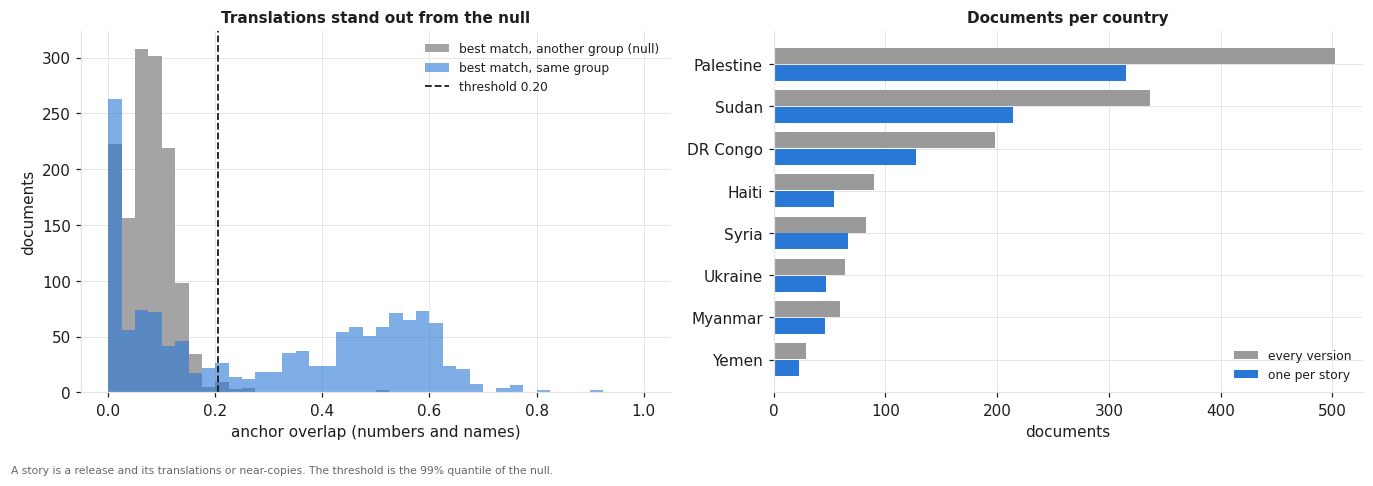

In [ ]:
# @title
# ==================================================================================================
# PHASE: DATA                                                           stage 5 of 5 in this phase
# STAGE 5a  ONE VERSION PER STORY
# WHAT THIS CELL DOES: groups translations and near-copies into stories and keeps one version of
#                      each
# ==================================================================================================
# WHAT THIS CELL DOES
#   Groups documents that are versions of the same story: a release and its translations, and
#   near-copies found in Stage 4b. Each story keeps ONE main version; the others are kept but are
#   left out of the analysis set, so a release is counted once, not once per language.
#
# WHY
#   On this corpus 80% of the French and Spanish documents are translations of an English document
#   in the same corpus. Counting every version treats one release as two or three independent
#   documents (pseudo-replication), and it lets the clustering find languages instead of topics.
#
# HOW
#   Two documents are versions of one story when they share a group, are published within
#   STORY_WINDOW_DAYS of each other (the candidate window of Munteanu and Marcu 2005), are in
#   different languages, and share language-independent anchors: numbers and names (Pouliquen,
#   Steinberger and Ignat 2003 identify translations with language-independent features).
#   The threshold is MEASURED, not chosen: the same score is computed against documents from a
#   DIFFERENT group, which cannot be translations, and the STORY_NULL_QUANTILE of that null is the
#   cut. At 0.99 about 1% of false matches can pass by construction.
#   Main version: STORY_PREFERRED_LANGUAGE first, then the earliest, then the longest.
#
# REFERENCES
#   Munteanu, D.S. and Marcu, D. (2005) Improving machine translation performance by exploiting
#     non-parallel corpora. Computational Linguistics 31(4):477-504.
#   Pouliquen, B., Steinberger, R. and Ignat, C. (2003) Automatic identification of document
#     translations in large multilingual document collections. RANLP 2003.

import re, unicodedata
import numpy as np, pandas as pd

heading("STAGE 5a  ONE VERSION PER STORY")

_docs = df_analysis.reset_index(drop=True)
_lang = _docs["detected_language"].astype(str)
_has_group = CAPABILITIES["group_comparison"] and "group" in _docs.columns
_dates = (pd.to_datetime(_docs["date"], errors="coerce") if "date" in _docs.columns
          else pd.Series(pd.NaT, index=_docs.index))


def _fold(text):
    text = unicodedata.normalize("NFKD", str(text).lower())
    return "".join(c for c in text if not unicodedata.combining(c))


_CAPITALISED_FUNCTION_WORDS = {"the", "a", "an", "in", "on", "of", "and", "for", "with", "this",
                               "that", "la", "le", "les", "el", "los", "las", "de", "del", "des",
                               "du", "un", "une", "y", "et", "en", "al", "au"}


def anchors(text):
    """Numbers and names: the tokens a translation keeps unchanged."""
    text = str(text)
    numbers = {re.sub(r"[,.\s]", "", n) for n in re.findall(r"\b\d[\d,.\s]{0,6}\d\b|\b\d{2,}\b", text)}
    names = {_fold(w) for w in re.findall(r"\b[^\W\d_][\w'-]{2,}\b", text) if w[0].isupper()}
    return {n for n in numbers if len(n) >= 2}, names - _CAPITALISED_FUNCTION_WORDS


_ANCHORS = [anchors(t) for t in _docs["text_clean"]]


def pair_score(i, j):
    (n1, c1), (n2, c2) = _ANCHORS[i], _ANCHORS[j]
    return (0.5 * len(n1 & n2) / max(1, len(n1 | n2))
            + 0.5 * len(c1 & c2) / max(1, len(c1 | c2)))


def best_match(i, same_group):
    """The best-scoring document in another language, in the window, in the same (or another)
    group."""
    candidates = _docs.index[_lang != _lang[i]]
    if _has_group:
        in_group = _docs["group"] == _docs.at[i, "group"]
        candidates = candidates[in_group[candidates].values == same_group]
    elif not same_group:
        return 0.0, None
    if _dates.notna().any() and pd.notna(_dates[i]):
        near = (_dates[candidates] - _dates[i]).abs() <= pd.Timedelta(days=int(CFG.story_window_days))
        candidates = candidates[near.fillna(False).values]
    best, where = 0.0, None
    for j in candidates:
        s = pair_score(i, j)
        if s > best:
            best, where = s, j
    return best, where


# ---- the threshold, from a null of pairs that cannot be translations --------------
MULTILINGUAL_STORIES = _lang.nunique() > 1 and _has_group
TRANSLATION_PAIRS = []
STORY_THRESHOLD = float("nan")
if MULTILINGUAL_STORIES:
    _null = [best_match(i, same_group=False)[0] for i in _docs.index]
    STORY_THRESHOLD = float(np.quantile(_null, float(CFG.story_null_quantile)))
    _same = []
    for i in _docs.index:
        score, j = best_match(i, same_group=True)
        _same.append(score)
        if j is not None and score > STORY_THRESHOLD:
            TRANSLATION_PAIRS.append((int(i), int(j), round(float(score), 3)))

# ---- stories: near-copies first, then translations, one version per language ------
# A translation set holds at most one document per language. Joining in order of score and refusing a
# join that would put two documents of the same language together stops two different English
# releases from being chained into one story through a translation that resembles both.
_parent = list(range(len(_docs)))
_languages = [{_lang[k]} for k in range(len(_docs))]


def _root(i):
    while _parent[i] != i:
        _parent[i] = _parent[_parent[i]]
        i = _parent[i]
    return i


def _join(i, j, same_language_allowed=False):
    a, b = _root(i), _root(j)
    if a == b or (not same_language_allowed and _languages[a] & _languages[b]):
        return False
    _parent[a] = b
    _languages[b] |= _languages[a]
    return True


_position = {doc: k for k, doc in enumerate(_docs["doc_id"].astype(str))}
for k, original in enumerate(_docs.get("near_duplicate_of", pd.Series("", index=_docs.index))):
    if str(original) in _position:
        _join(k, _position[str(original)], same_language_allowed=True)
TRANSLATION_PAIRS = [p for p in sorted(TRANSLATION_PAIRS, key=lambda p: -p[2]) if _join(p[0], p[1])]

_docs["story_id"] = [f"S{_root(k):05d}" for k in range(len(_docs))]
_order = pd.DataFrame({
    "story": _docs["story_id"],
    "preferred": (_lang != str(CFG.story_preferred_language)).astype(int),
    "date": _dates.fillna(pd.Timestamp.max),
    "length": -_docs["word_count_clean"].fillna(0)})
_main_rows = _order.sort_values(["story", "preferred", "date", "length"]).groupby("story").head(1).index
_docs["is_main_version"] = False
_docs.loc[_main_rows, "is_main_version"] = True
_docs["story_size"] = _docs.groupby("story_id")["doc_id"].transform("size")
df_analysis = _docs

N_STORIES = report("stories.stories", int(_docs["story_id"].nunique()), "stories", "Stage 5a")
report("stories.translation_pairs", len(TRANSLATION_PAIRS), "pairs", "Stage 5a")
report("stories.other_versions", int((~_docs["is_main_version"]).sum()), "documents", "Stage 5a")
if MULTILINGUAL_STORIES:
    report("stories.threshold", round(STORY_THRESHOLD, 4), "anchor score", "Stage 5a")

# ---- report ---------------------------------------------------------------------
print(f"  documents               : {len(_docs):,}")
if MULTILINGUAL_STORIES:
    print(f"  threshold (null {float(CFG.story_null_quantile):.0%}) : {STORY_THRESHOLD:.3f}")
    print(f"  translation pairs       : {len(TRANSLATION_PAIRS):,}")
else:
    print("  translation matching    : not applicable (one language, or no group column)")
print(f"  stories                 : {N_STORIES:,}")
print(f"  main versions (analysed): {int(_docs['is_main_version'].sum()):,}")
print(f"  other versions (kept)   : {int((~_docs['is_main_version']).sum()):,}")
if MULTILINGUAL_STORIES:
    _other = _docs.loc[~_docs["is_main_version"]]
    print("  other versions by language : "
          + ", ".join(f"{k} {v}" for k, v in _other["detected_language"].value_counts().items()))
    if _has_group:
        _by = _docs.groupby("group")["is_main_version"].agg(["size", "sum"])
        print(f"  documents per {CFG.group_noun}, all versions -> one per story:")
        for g, row in _by.iterrows():
            print(f"    {str(g):<6} {int(row['size']):>5} -> {int(row['sum']):>5}")
    for i, j, score in sorted(TRANSLATION_PAIRS, key=lambda p: -p[2])[:3]:
        print(f"    example {score:.2f}: {str(_docs.at[i, 'title'])[:45]!r}")
        print(f"                 = {str(_docs.at[j, 'title'])[:45]!r}")
rule()

# ---- figure: how the threshold separates translations, and what it does to the counts ----
if MULTILINGUAL_STORIES:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    bins = np.linspace(0, 1, 41)
    axes[0].hist(_null, bins=bins, color=OTHER, alpha=0.9, label="best match, another group (null)")
    axes[0].hist(_same, bins=bins, color=PALETTE[0], alpha=0.6, label="best match, same group")
    axes[0].axvline(STORY_THRESHOLD, color=INK, ls="--", lw=1.2,
                    label=f"threshold {STORY_THRESHOLD:.2f}")
    axes[0].set_xlabel("anchor overlap (numbers and names)")
    axes[0].set_ylabel("documents")
    axes[0].set_title("Translations stand out from the null", fontsize=10)
    axes[0].legend(fontsize=8, frameon=False)
    _by = _docs.groupby("group")["is_main_version"].agg(["size", "sum"]).sort_values("size")
    _y = np.arange(len(_by))
    axes[1].barh(_y + 0.2, _by["size"], height=0.38, color=OTHER, label="every version")
    axes[1].barh(_y - 0.2, _by["sum"], height=0.38, color=PALETTE[0], label="one per story")
    axes[1].set_yticks(_y)
    axes[1].set_yticklabels([group_label(g) for g in _by.index])
    axes[1].set_xlabel("documents")
    axes[1].set_title(f"Documents per {CFG.group_noun}", fontsize=10)
    axes[1].legend(fontsize=8, frameon=False)
    fig.tight_layout()
    add_reference_footer(fig, "A story is a release and its translations or near-copies. The "
                              f"threshold is the {float(CFG.story_null_quantile):.0%} quantile of the null.")
    save_figure(fig, "s05a_stories"); plt.show()

## Stage 5b: split into passages   [phase: passages]

**What.** Splits each document into passages of about 160 words (at most 250), the unit that is
embedded and clustered. Then marks the **analysis set**: the passages that go on to embedding,
dimension reduction and clustering.

**The analysis set** keeps a passage when:
- its document is the main version of its story (Stage 5a);
- it is written in its document's language;
- it is prose, not a list of names.

Other passages are kept in the table but left out of the analysis, and each exclusion is counted.

**Stage 5c** then replaces place names in a copy of the text, so topics cannot form around
countries. Quotations always use the original text.

  STAGE 5b  SPLIT INTO PASSAGES
  documents in          : 1,362
  passages out          : 6,089
  analysis set          : 3,912 passages (main version, prose, in its document's language)
    left out            : other versions 2,153, lists of names 37, other language 18
  passages per document : mean 4.5, median 4

  target length         : 160 words
  hard maximum          : 250 words   (enforced on words, so it holds in any script)
  floor                 : 20 words
  short tail merged if  : under 80 words and the merge stays under the maximum

  passage length        : median 172, range 20 to 250
  passages over the cap : 0

  RECONCILIATION OF WORDS
    words in the cleaned documents : 1,052,898
    words kept in passages         : 1,052,822
    words discarded below the floor: 76 in 7 fragment(s)
    unaccounted                    : 0 (0.000% of the input)
      A small residue is expected: a fragment merged into the previous passage is counted
      once, not twice.

  HOW EACH 

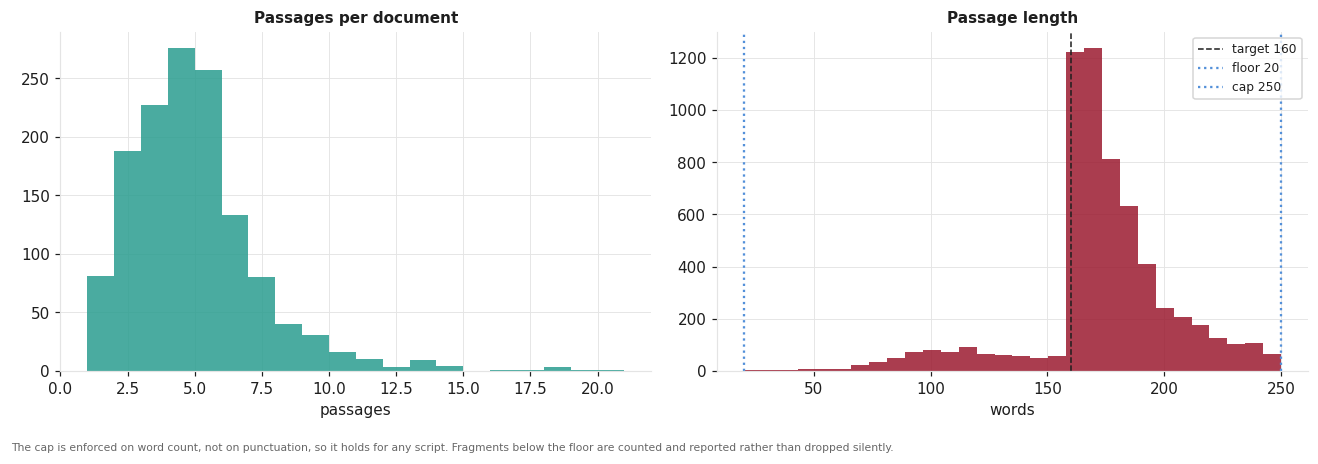


PRACTITIONER NOTE
  Split a long document into paragraph-sized passages before feeding it to a topic model: a single
  vector for the whole document represents none of its subjects. Count what the split throws away,
  in words, and report it, since a chunker that discards fragments silently is easy to miss.


In [ ]:
# @title
# ==================================================================================================
# PHASE: PASSAGES                                                       stage 1 of 2 in this phase
# STAGE 5b  SPLIT INTO PASSAGES
# WHAT THIS CELL DOES: splits documents into passages of about 160 words and marks the analysis set
# ==================================================================================================
# WHAT THIS CELL DOES
#   Splits each document's cleaned text into paragraph-sized passages, enforcing a target length,
#   a floor and a hard maximum, all in words. Fragments below the floor are counted rather than
#   silently dropped, and the word count is reconciled between the input and the output.
#
# WHY
#   A single vector for a whole document represents none of its subjects, so passages of a
#   controlled length carry the topic model instead. The floor and maximum are enforced on word
#   count rather than on sentence punctuation, so they hold for any script.
#
# HOW
#   Paragraphs are split on a sentence boundary followed by a capital letter. When that yields no
#   more than one paragraph, sentence terminators for other scripts are tried next, then a
#   length-based fallback for a script with no recognised terminator at all.

import re
import numpy as np, pandas as pd

SENTENCE_END_ASCII = re.compile(r"(?<=[.!?])\s+")
# ASCII terminators need a following space, so "1.5" and "U.S." are never split; the wide
# terminators of scripts without spaces do not.
SENTENCE_END_WIDE  = re.compile(r"(?<=[。۔؟।！？])\s*|(?<=[.!?])\s+")
PARAGRAPH_SPLIT    = re.compile(r"(?<=[.!?])\s+(?=[A-ZÀ-Ü])")

DISCARDED = {"passages": 0, "words": 0}
SPLIT_METHOD_USED = collections_counter = {}


def split_sentences_any_script(text):
    """Sentences, for any script. The ASCII rule is tried first because it is the most precise;
    a wider terminator set catches Chinese, Arabic, Thai and Devanagari; length-based splitting is
    the last resort for a script with no sentence terminator at all."""
    parts = [p for p in SENTENCE_END_ASCII.split(text) if p.strip()]
    if len(parts) > 1:
        return parts, "ascii terminators"
    parts = [p for p in SENTENCE_END_WIDE.split(text) if p.strip()]
    if len(parts) > 1:
        return parts, "wide terminators"
    words = text.split()
    step = CFG.passage_target_words
    return ([" ".join(words[k:k + step]) for k in range(0, len(words), step)] or [text],
            "length only, no sentence terminator found")


def split_into_passages(body, target, minimum, maximum, merge_tail_under):
    paragraphs = [p.strip() for p in PARAGRAPH_SPLIT.split(body) if p.strip()]
    if len(paragraphs) <= 1:
        paragraphs, method = split_sentences_any_script(body)
    else:
        method = "latin capital after a full stop"

    passages, buffer = [], []

    def buffer_words():
        return sum(len(p.split()) for p in buffer)

    for paragraph in paragraphs:
        if len(paragraph.split()) > maximum:
            if buffer:
                passages.append(" ".join(buffer)); buffer = []
            sentences, _ = split_sentences_any_script(paragraph)
            current = []
            for sentence in sentences:
                current.append(sentence)
                if sum(len(s.split()) for s in current) >= target:
                    passages.append(" ".join(current)); current = []
            if current:
                buffer = current
            continue
        buffer.append(paragraph)
        if buffer_words() >= target:
            passages.append(" ".join(buffer)); buffer = []

    if buffer:
        tail = " ".join(buffer)
        if (passages and buffer_words() < merge_tail_under
                and len(passages[-1].split()) + buffer_words() <= maximum):
            passages[-1] = passages[-1] + " " + tail
        else:
            passages.append(tail)

    # The cap is enforced on words, so it holds whatever the script.
    capped = []
    for passage in passages:
        words = passage.split()
        if len(words) <= maximum:
            capped.append(passage); continue
        for start in range(0, len(words), target):
            capped.append(" ".join(words[start:start + target]))

    kept, dropped = [], []
    for passage in capped:
        (kept if len(passage.split()) >= minimum else dropped).append(passage)
    DISCARDED["passages"] += len(dropped)
    DISCARDED["words"] += sum(len(p.split()) for p in dropped)
    return kept, method


rows, methods = [], []
for _, document in df_analysis.iterrows():
    produced, method = split_into_passages(
        str(document["text_clean"]), CFG.passage_target_words, CFG.passage_min_words,
        CFG.passage_max_words, CFG.passage_merge_tail_under)
    methods.append(method)
    for order, passage in enumerate(produced):
        row = {
            "passage_id": f"{document['doc_id']}#{order:03d}",
            "doc_id": document["doc_id"],
            "passage_order": order,
            "text_raw": passage,                       # the original wording
            "word_count": len(passage.split()),
            "doc_language": document["detected_language"],
            "near_duplicate_flag": document["near_duplicate_flag"],
            "story_id": document.get("story_id", document["doc_id"]),
            "is_main_version": bool(document.get("is_main_version", True)),
        }
        for internal in ("title", "group", "group_label", "group_all", "year", "date",
                         "doc_type", "lang_declared", "external_label"):
            if internal in df_analysis.columns:
                row[internal] = document[internal]
        rows.append(row)

passages = pd.DataFrame(rows)
df_analysis["split_method"] = methods

# ---- which passages are analysed --------------------------------------------------
# A passage enters the analysis set when its document is the main version of its story, it is
# written in its document's language, and it is prose rather than a list of names.
_word = re.compile(r"[^\W\d_][\w'-]*")


def capital_share(text):
    words = _word.findall(str(text))
    return sum(w[0].isupper() for w in words) / len(words) if words else 0.0


passages["passage_language"] = passages["text_raw"].map(detect_language)
passages["capital_share"] = passages["text_raw"].map(capital_share).round(3)
passages["list_like"] = passages["capital_share"] >= float(CFG.list_capital_share)
passages["other_language"] = passages["passage_language"] != passages["doc_language"]
passages["in_analysis"] = (passages["is_main_version"] & ~passages["list_like"]
                           & ~passages["other_language"])
report("passages.list_like", int(passages["list_like"].sum()), "passages", "Stage 5b")
report("passages.other_language", int(passages["other_language"].sum()), "passages", "Stage 5b")
report("passages.in_analysis", int(passages["in_analysis"].sum()), "passages", "Stage 5b")

WORDS_IN = int(df_analysis["word_count_clean"].sum())
WORDS_KEPT = int(passages["word_count"].sum())

heading("STAGE 5b  SPLIT INTO PASSAGES")
print(f"  documents in          : {len(df_analysis):,}")
print(f"  passages out          : {len(passages):,}")
print(f"  analysis set          : {int(passages['in_analysis'].sum()):,} passages "
      f"(main version, prose, in its document's language)")
print(f"    left out            : other versions {int((~passages['is_main_version']).sum()):,}, "
      f"lists of names {int(passages['list_like'].sum()):,}, other language "
      f"{int(passages['other_language'].sum()):,}")
print(f"  passages per document : mean {len(passages) / max(1, len(df_analysis)):.1f}, "
      f"median {int(passages.groupby('doc_id').size().median())}")
print()
print(f"  target length         : {CFG.passage_target_words} words")
print(f"  hard maximum          : {CFG.passage_max_words} words   "
      f"(enforced on words, so it holds in any script)")
print(f"  floor                 : {CFG.passage_min_words} words")
print(f"  short tail merged if  : under {CFG.passage_merge_tail_under} words and the merge stays "
      f"under the maximum")
print()
print(f"  passage length        : median {int(passages['word_count'].median())}, "
      f"range {int(passages['word_count'].min())} to {int(passages['word_count'].max())}")
_over = int((passages["word_count"] > CFG.passage_max_words).sum())
print(f"  passages over the cap : {_over}")
assert _over == 0, (f"{_over} passage(s) exceed the declared maximum of {CFG.passage_max_words} "
                    f"words. The cap is not being enforced.")

print()
print("  RECONCILIATION OF WORDS")
print(f"    words in the cleaned documents : {WORDS_IN:,}")
print(f"    words kept in passages         : {WORDS_KEPT:,}")
print(f"    words discarded below the floor: {DISCARDED['words']:,} "
      f"in {DISCARDED['passages']:,} fragment(s)")
_difference = WORDS_IN - WORDS_KEPT - DISCARDED["words"]
print(f"    unaccounted                    : {_difference:,} "
      f"({100 * abs(_difference) / max(1, WORDS_IN):.3f}% of the input)")
print("      A small residue is expected: a fragment merged into the previous passage is counted")
print("      once, not twice.")

print()
print("  HOW EACH DOCUMENT WAS SPLIT")
for method, count in df_analysis["split_method"].value_counts().items():
    print(f"    {count:>6}  {method}")
_fallback = int((df_analysis["split_method"] != "latin capital after a full stop").sum())
if _fallback:
    print(f"    {_fallback} document(s) needed a fallback (no ASCII sentence endings).")
rule()

report("passages.count", len(passages), "passages", "Stage 5b")
report("passages.words_kept", WORDS_KEPT, "words", "Stage 5b")
report("passages.discarded", DISCARDED["passages"], "fragments", "Stage 5b")
report("passages.words_discarded", DISCARDED["words"], "words", "Stage 5b")
ledger_step("passage fragments below the floor", WORDS_IN, WORDS_KEPT,
            f"fragments shorter than {CFG.passage_min_words} words, counted in words not documents", unit="word")


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
per_document = passages.groupby("doc_id").size()
axes[0].hist(per_document, bins=range(1, int(per_document.max()) + 2), color="#2A9D8F", alpha=0.85)
axes[0].set_title("Passages per document", fontsize=10); axes[0].set_xlabel("passages")
axes[1].hist(passages["word_count"], bins=30, color=ACCENT, alpha=0.85)
axes[1].axvline(CFG.passage_target_words, color=INK, ls="--", lw=1,
                label=f"target {CFG.passage_target_words}")
axes[1].axvline(CFG.passage_min_words, color="#5390D9", ls=":", lw=1.5,
                label=f"floor {CFG.passage_min_words}")
axes[1].axvline(CFG.passage_max_words, color="#5390D9", ls=":", lw=1.5,
                label=f"cap {CFG.passage_max_words}")
axes[1].set_title("Passage length", fontsize=10); axes[1].set_xlabel("words")
axes[1].legend(fontsize=8)
fig.tight_layout()
add_reference_footer(fig, "The cap is enforced on word count, not on punctuation, so it holds for "
                         "any script. Fragments below the floor are counted and reported rather "
                         "than dropped silently.")
save_figure(fig, "s05b_passages"); plt.show()

practitioner_note("Passages", """
Split a long document into paragraph-sized passages before feeding it to a topic model: a single
vector for the whole document represents none of its subjects. Count what the split throws away,
in words, and report it, since a chunker that discards fragments silently is easy to miss.
""")

  STAGE 5c  MASK PLACE NAMES
  method                : multilingual entity model xx_ent_wiki_sm, plus the curated list
  placeholder           : 'location'
  every detected language in this corpus uses the Latin alphabet, which the curated
  list covers.
  accent tolerance      : 1,914 additional place mention(s) matched that a literal
                          comparison with the same word list would have missed

  passages              : 6,089
  passages changed      : 5,824 (95.6%)
  tokens masked         : 33,146 (3.15% of all words)

  WHICH COLUMN EACH LATER STAGE READS
    text      masked    embedding, keyword extraction
    text_raw  original  lexical matching, every quotation shown to a reader, naming
  A reader never sees a placeholder, because quotations come from text_raw.

  WHAT STILL IDENTIFIES EACH GROUP after masking, most distinctive first (weighted
  log-odds, Monroe et al. 2008). Words marked * are capitalised and may be names the
  masking missed; the rest are wha

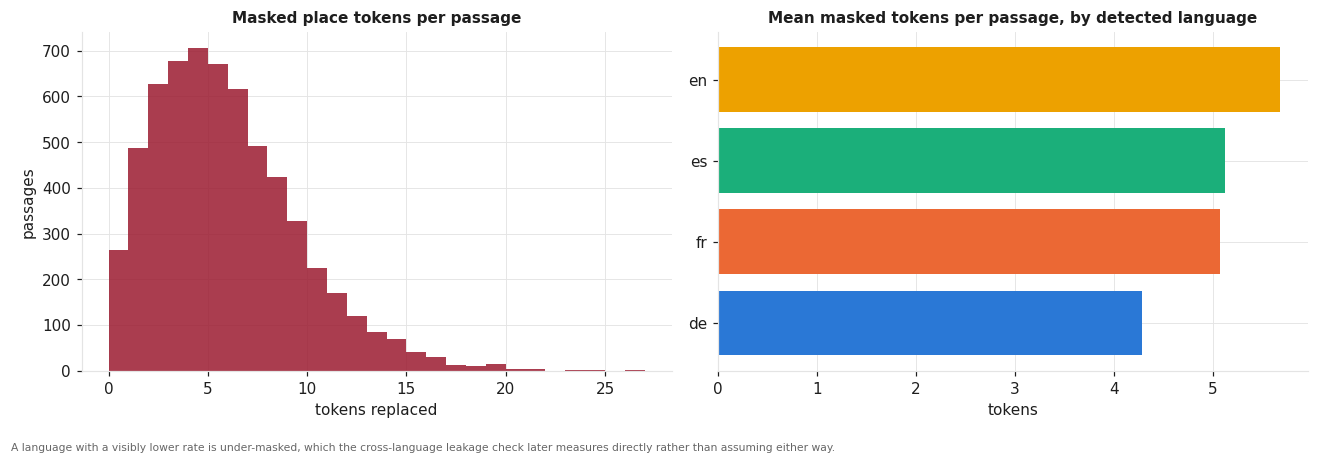


PRACTITIONER NOTE
  Mask place names before embedding, or a theme forms around where a report is about rather than what
  it says. Keep the original text in a separate column, and decide which column each later stage
  reads, since reading the wrong one is invisible in the output.


In [ ]:
# @title
# ==================================================================================================
# PHASE: PASSAGES                                                       stage 2 of 2 in this phase
# STAGE 5c  MASK PLACE NAMES
# WHAT THIS CELL DOES: replaces place names, so topics cannot form around countries
# ==================================================================================================
# WHAT THIS CELL DOES
#   Masks place names in each passage before embedding, and records which column later stages
#   should read: the masked "text" column, or the original "text_raw" column.
#
# WHY
#   A theme should form around what a report describes, not the place it is about. Left unmasked,
#   a country comparison partly measures the clustering's memory of the country label.
#
# HOW
#   A curated, accent-tolerant list of place names and demonyms, in the languages present, applied
#   together with a multilingual entity model when it is available. A name is matched whole, with a
#   space or hyphen between its words, not word by word. A facility's name is masked while the kind
#   of facility (hospital, clinic) is kept, since that is the subject of the passage, not the place.
#
# WHICH COLUMN EACH LATER STAGE READS, stated once here because getting it wrong is invisible:
#   text       masked.   Read by the embedding and by the keyword extraction.
#   text_raw   original. Read by the lexical matching, by every quotation shown to a reader, and
#              by the naming model.

import re
import numpy as np, pandas as pd

PLACEHOLDER = CFG.place_placeholder

# A curated list, used alone when the entity model is unavailable and alongside it otherwise. It
# holds demonyms and spellings a general-purpose entity model misses, in the languages present.
#
# ONE NAME PER LINE, NOT ONE WORD: each entry is matched whole, with a space or hyphen between its
# words, never split and masked word by word, which would mask common function words in any
# language ("el", "au", "tel") wherever they occur. The NEVER_ALONE guard below checks for this.
#
# Neighbouring countries (Chad, Bangladesh, Turkiye) are deliberately not on this list: masking
# them is a scope decision, left visible in the residual check further down, not a correction here.
CURATED_PLACE_NAMES = [line.strip() for line in """
gaza, gazan, gazans, gazaoui, gazaouis, gazati, gazaties, gaza strip, gaza city, bande de gaza
franja de gaza, ville de gaza, ciudad de gaza, rafah, khan younis, khan yunis, deir al-balah
deir el-balah, deir al balah, jabalia, beit lahia, beit hanoun, nuseirat, maghazi, bureij, shujaiya
tel aviv, jerusalem, hebron, nablus, jenin, ramallah, bethlehem, tulkarem, qalqilya, masafer yatta
yatta, west bank, cisjordanie, cisjordania, palestine, palestinian, palestinians, palestina
palestino, palestinos, palestinien, palestiniens, palestinienne, palestiniennes, israel, israeli
israelis, israelien, israeliens, israelienne, israeliennes, israelies, israeli
khartoum, jartum, omdurman, darfur, darfour, el geneina, geneina, nyala, el fasher, al fasher
zalingei, kutum, tawila, zamzam, kadugli, damazin, ed damazin, wad madani, gedaref, kassala
port sudan, sudan, sudanese, soudan, soudanais, soudanaise, sudanes, sudanesa, sudaneses
kinshasa, goma, bukavu, beni, butembo, bunia, uvira, kalemie, lubumbashi, kananga, mbuji-mayi
masisi, rutshuru, ituri, kivu, north kivu, south kivu, nord-kivu, sud-kivu, tanganyika, congo
dr congo, drc, rdc, rd congo, democratic republic of the congo, democratic republic of congo
republique democratique du congo, republica democratica del congo, republica democratica de congo
congolese, congolais, congolaise, congoleno, congolena, congolenos
sanaa, sana'a, aden, taiz, hodeidah, hudaydah, hajjah, saada, marib, ibb, mocha, yemen, yemeni
yemenis, yemenite, yemenites
damascus, aleppo, alep, alepo, idlib, homs, hama, deir ez-zor, deir ezzor, deir ez zor, raqqa
hasakah, afrin, azaz, syria, syrian, syrians, syrie, syrien, syriens, syrienne, siria, sirio
sirios, siria
kyiv, kiev, kharkiv, donetsk, luhansk, mariupol, kherson, zaporizhzhia, odesa, dnipro, lviv
mykolaiv, ukraine, ukrainian, ukrainians, ukrainien, ukrainiens, ucrania, ucraniano, ucranianos
yangon, rakhine, rakhine state, kachin state, sittwe, maungdaw, buthidaung, cox's bazar, kachin, shan state, chin state
mandalay, naypyidaw, myanmar, burmese, burma, birmanie, birman, birmania, rohingya, rohingyas
port-au-prince, puerto principe, cite soleil, carrefour, croix-des-bouquets, gonaives
cap-haitien, artibonite, tabarre, turgeau, delmas, martissant, petion-ville, haiti, haitian
haitians, haitien, haitiens, haitienne, haitiano, haitianos
""".replace("\n", ",").split(",") if line.strip()]
# Another corpus adds its own places in Stage 1 (EXTRA_PLACE_NAMES), one whole name per entry.
CURATED_PLACE_NAMES += [str(name).strip().lower() for name in CFG.extra_place_names
                        if str(name).strip()]

# Names that CONTAIN a place above but are a different place, so they are left as written: masking
# "South Sudan" as "South location" would name Sudan in a passage about a different country.
PROTECTED_PLACE_NAMES = ["south sudan", "south sudanese", "soudan du sud", "sud-soudan",
                         "sud-soudanais", "sudan del sur", "sursudanes", "sursudanesa"]

# A compass word joined to a place is part of its name ("North Kivu", "northwest Syria", "Darfour
# du Nord"). Left unmasked, it would still identify the place after the name itself is masked.
COMPASS_BEFORE = r"(?:(?:north|south|east|west)(?:[\s\-]?(?:east|west))?(?:ern)?|central|nord|sud)"
# After a name, a French or Spanish direction is taken only with its particle ("du Nord", "del
# Sur"), because "est", "sur" and "este" alone are also the words "is", "on" and "this".
COMPASS_AFTER = (r"(?:(?:du|del)\s+(?:nord|sud|norte|sur)|norte|occidental|oriental|central"
                 r"|septentrional|meridional)")

# Words that must never be a place name on their own, in any language of this corpus. This is a
# guard: if an edit to the list above ever adds one as a single entry, the assert below stops it.
NEVER_ALONE = {"el", "la", "le", "les", "los", "las", "au", "aux", "de", "del", "du", "des", "al",
               "tel", "port", "prince", "city", "san", "santa", "cap", "cite", "cox", "deir", "wad",
               "beit", "khan", "state", "north", "south", "east", "west", "bank", "strip", "croix"}
_single = {name for name in CURATED_PLACE_NAMES if " " not in name and "-" not in name}
assert not (_single & NEVER_ALONE), (
    f"Single-word entries would mask a function word everywhere: {sorted(_single & NEVER_ALONE)}. "
    f"Write the whole name instead, for example 'el fasher'.")

# The single words other stages use. Notebook 2 removes these from cluster names and summaries, so
# it is left with the distinctive words of each place name rather than a generic one.
_GENERIC_IN_NAMES = NEVER_ALONE | {"republic", "democratic", "republique", "democratique",
                                   "republica", "democratica", "gaza", "ville", "ciudad", "bande",
                                   "franja", "nord", "sud", "ez", "zor", "ed", "en", "dr", "rd",
                                   "principe", "puerto", "soleil", "bouquets", "chin", "aviv"}
# Each word of a name that identifies it on its own, plus every hyphenated name written whole,
# since notebook 2 reads "port-au-prince" as one token.
# Generic words ("principe" is also French for "principle", "soleil" for "sun") are left out, so
# they are never removed from a cluster name.
CURATED_PLACE_WORDS = ({word for name in CURATED_PLACE_NAMES
                        for word in re.split(r"[\s\-']+", name)
                        if len(word) >= 3 and word not in _GENERIC_IN_NAMES}
                       | {name for name in CURATED_PLACE_NAMES if "-" in name and " " not in name}
                       | {"gaza"})


# ---- accent-tolerant matching ----------------------------------------------
# The curated list is written without accents; each letter is expanded into a class holding its
# accented forms, so one written form covers all spellings the corpus's languages use.
#
# This is matching, not normalisation: the text itself is never altered except where a place name
# is replaced by the placeholder.
ACCENT_CLASSES = {
    "a": "aàáâãäåā",
    "e": "eèéêëē",
    "i": "iìíîïī",
    "o": "oòóôõöøō",
    "u": "uùúûüū",
    "n": "nñń",
    "c": "cçć",
    "y": "yýÿ",
    "s": "sšś",
    "z": "zžź",
    "g": "gğ",
}


def accent_tolerant(word):
    """One curated word, as a pattern that also matches its accented spellings."""
    out = []
    for character in str(word):
        lowered = character.lower()
        if lowered in ACCENT_CLASSES:
            out.append(f"[{ACCENT_CLASSES[lowered]}]")
        else:
            out.append(re.escape(character))
    return "".join(out)


def name_pattern(name):
    """One name, accent-tolerant, with a space or a hyphen accepted between its words and either
    apostrophe inside a word."""
    words = [w for w in re.split(r"[\s\-]+", str(name)) if w]
    return r"[\s\-\u2010]+".join(accent_tolerant(w).replace("'", "['\u2019]") for w in words)


def _fold(text):
    import unicodedata
    text = unicodedata.normalize("NFKD", str(text).lower())
    return re.sub(r"[\s\-\u2010'\u2019]+", " ",
                  "".join(c for c in text if not unicodedata.combining(c))).strip()


PROTECTED_FOLDED = {_fold(name) for name in PROTECTED_PLACE_NAMES}


def place_pattern():
    """Protected names first, so "South Sudan" is found before "Sudan" at the same position; then
    every place name, longest first, with an optional compass word joined to it."""
    keep = "|".join(name_pattern(n) for n in sorted(PROTECTED_PLACE_NAMES, key=len, reverse=True))
    ordered = sorted(set(CURATED_PLACE_NAMES), key=lambda n: (-len(n), n))
    places = "|".join(name_pattern(n) for n in ordered)
    return re.compile(rf"\b(?:(?P<keep>{keep})|(?P<place>(?:{COMPASS_BEFORE}[\s\-]+)?(?:{places})"
                      rf"(?:[\s\-]+{COMPASS_AFTER})?))\b", re.IGNORECASE)


def _replace(match):
    return match.group(0) if match.group("keep") else PLACEHOLDER


PLACE_PATTERN = place_pattern()

# A check that can fail: the accented spellings this corpus actually contains must now match.
_probe = {"israelíes": "israelies", "israéliens": "israeliens",
          "libanés": "libanes", "sudanés": "sudanes"}
_missed = [form for form, base in _probe.items()
           if base in CURATED_PLACE_NAMES and not PLACE_PATTERN.fullmatch(form)]
assert not _missed, (
    f"Accented spellings not matched despite their base form being in the curated list: {_missed}. "
    f"Add the accent class or fix the pattern before continuing.")


_CASES = {
    "El hospital de El Fasher recibe heridos.": "El hospital de location recibe heridos.",
    "Il est arrive au centre de Port-au-Prince.": "Il est arrive au centre de location.",
    "Teams in North Kivu and the Democratic Republic of Congo.": "Teams in location and the location.",
    "Refugees crossed into South Sudan from Sudan.": "Refugees crossed into South Sudan from location.",
    "Un tel afflux dans la bande de Gaza.": "Un tel afflux dans la location.",
    "They reached Cox's Bazar and the port.": "They reached location and the port.",
    "La situation a Gaza est grave et les attaques sur Gaza continuent.":
        "La situation a location est grave et les attaques sur location continuent.",
    "En Darfur del Norte y en Siria este ano.": "En location y en location este ano.",
    "Fighting in northwest Syria and West Darfur.": "Fighting in location and location.",
}
_wrong = {text: PLACE_PATTERN.sub(_replace, text) for text in _CASES
          if PLACE_PATTERN.sub(_replace, text) != _CASES[text]}
assert not _wrong, f"The place pattern does not mask as intended: {_wrong}. Fix the pattern."


# The entity model tags a named facility ("Nasser Hospital") as a place. Only the name is masked;
# the kind of facility (hospital, clinic) is kept, since that is the subject, not the place.
FACILITY_NOUNS = {"hospital", "hopital", "hospitals", "hopitaux", "hospitales", "clinic", "clinics",
                  "clinique", "cliniques", "clinica", "clinicas", "camp", "camps", "campo", "campos",
                  "centre", "center", "centro", "health", "sante", "salud", "medical", "complex"}


def _mask_entity(entity):
    words = entity.split()
    kept = [w for w in words if _fold(w) in FACILITY_NOUNS]
    if not kept or len(kept) == len(words):
        return PLACEHOLDER if not kept else entity
    return " ".join([PLACEHOLDER] + kept)


def build_masker():
    """Return a masking function and a label naming the method actually in use."""
    try:
        import spacy
        model = spacy.load("xx_ent_wiki_sm")

        def mask(text):
            document = model(str(text)[:100000])
            spans = [(entity.start_char, entity.end_char) for entity in document.ents
                     if entity.label_ in ("LOC", "GPE")]
            output = str(text)
            for start, end in sorted(spans, reverse=True):
                entity = output[start:end]
                # an entity the model tags as a place but this list protects is left as written
                if _fold(entity) in PROTECTED_FOLDED:
                    continue
                output = output[:start] + _mask_entity(entity) + output[end:]
            return PLACE_PATTERN.sub(_replace, output)

        return mask, "multilingual entity model xx_ent_wiki_sm, plus the curated list"
    except Exception as exc:
        def mask(text):
            return PLACE_PATTERN.sub(_replace, str(text))

        return mask, f"curated list only, the entity model is unavailable ({type(exc).__name__})"


mask_places, MASK_METHOD = build_masker()

heading("STAGE 5c  MASK PLACE NAMES")

print(f"  method                : {MASK_METHOD}")
print(f"  placeholder           : '{PLACEHOLDER}'")

# The curated list is written in the Latin alphabet, so this test uses the DETECTED language label
# (established in Stage 5) rather than the publisher's declared one, which need not match the text.
LATIN_SCRIPT_LANGUAGES = {"en", "fr", "es", "de", "it", "pt", "nl", "pl", "ro", "sv", "da", "no",
                          "fi", "cs", "hu", "tr", "id", "ms", "vi", "hr", "sk", "sl", "et", "lv",
                          "lt", "sq", "af", "ca", "eu", "gl", "cy", "is", "sw", "tl"}
non_latin = {language: int(count) for language, count
             in passages["doc_language"].value_counts().items()
             if language not in LATIN_SCRIPT_LANGUAGES and language != "unknown"}

if non_latin and MASK_METHOD.startswith("curated list only"):
    print()
    print("  WARNING: place names are NOT masked in these languages (no entity model, Latin-only")
    print("  list):")
    for language, count in non_latin.items():
        print(f"    {language}: {count:,} passage(s)")
    print("  Report this; the cross-language leakage check shows the consequence.")
elif non_latin:
    print(f"  non-Latin-script passages : "
          + ", ".join(f"{language} {count:,}" for language, count in non_latin.items())
          + "  (covered by the entity model, not by the curated list)")
else:
    print("  every detected language in this corpus uses the Latin alphabet, which the curated")
    print("  list covers.")

# ---- mask, keeping the original -------------------------------------------
if "text" not in passages.columns:
    passages["text"] = passages["text_raw"].map(mask_places)

words_before = int(passages["text_raw"].str.split().str.len().sum())
placeholders_added = int(passages["text"].str.count(rf"\b{PLACEHOLDER}\b").sum()
                         - passages["text_raw"].str.count(rf"\b{PLACEHOLDER}\b").sum())
changed = int((passages["text"] != passages["text_raw"]).sum())

# Counted directly rather than assumed: how many additional place mentions the accent-tolerant
# pattern matches that a literal comparison with the same word list would miss.
_literal = re.compile(r"\b(?:" + "|".join(
    r"[\s\-]+".join(map(re.escape, re.split(r"[\s\-]+", n)))
    for n in sorted(set(CURATED_PLACE_NAMES), key=len, reverse=True)) + r")\b", re.IGNORECASE)
_sample = passages["text_raw"].astype(str)
_extra = int(sum(len(PLACE_PATTERN.findall(t)) - len(_literal.findall(t)) for t in _sample))
print(f"  accent tolerance      : {_extra:,} additional place mention(s) matched that a literal")
print(f"                          comparison with the same word list would have missed")

print()
print(f"  passages              : {len(passages):,}")
print(f"  passages changed      : {changed:,} ({100 * changed / max(1, len(passages)):.1f}%)")
print(f"  tokens masked         : {placeholders_added:,} "
      f"({100 * placeholders_added / max(1, words_before):.2f}% of all words)")
print()
print("  WHICH COLUMN EACH LATER STAGE READS")
print("    text      masked    embedding, keyword extraction")
print("    text_raw  original  lexical matching, every quotation shown to a reader, naming")
print("  A reader never sees a placeholder, because quotations come from text_raw.")
rule()

# ---- what still identifies a group after masking --------------------------------------------
# The same weighted log-odds with an informative Dirichlet prior used in notebook 2 (Monroe,
# Colaresi and Quinn 2008) is applied here to the masked text, each group against the rest.
#
# A place name the list and the model both missed appears near the top of its group; so does a
# neighbouring country, which is a scope decision rather than an error.
_group_col = group_column(passages)
if _group_col:
    _tok = re.compile(r"[^\W\d_][\w'-]{2,}")
    _counts = {g: {} for g in passages[_group_col].dropna().unique()}
    for _t, _g in zip(passages["text"].astype(str), passages[_group_col]):
        if _g in _counts:
            for _w in _tok.findall(_t.lower()):
                _counts[_g][_w] = _counts[_g].get(_w, 0) + 1
    _total = {}
    for _c in _counts.values():
        for _w, _n in _c.items():
            _total[_w] = _total.get(_w, 0) + _n
    _n_all = sum(_total.values())
    _alpha = {w: 0.01 * n for w, n in _total.items()}
    _alpha_sum = sum(_alpha.values())
    # A word is marked when it is capitalised in at least 80% of its occurrences away from the
    # start of a sentence, the same test notebook 2 uses to find proper nouns.
    _upper, _lower = {}, {}
    for _t in passages["text_raw"].astype(str):
        for _m in re.finditer(r"(?<![.!?:]\s)(?<!^)\b([^\W\d_][\w'-]{2,})", _t):
            _w = _m.group(1)
            _book = _upper if _w[0].isupper() else _lower
            _book[_w.lower()] = _book.get(_w.lower(), 0) + 1
    _capitalised = {w for w, n in _upper.items() if n >= 5 and n / (n + _lower.get(w, 0)) >= 0.8}
    MASKING_RESIDUAL = {}
    print()
    print("  WHAT STILL IDENTIFIES EACH GROUP after masking, most distinctive first (weighted")
    print("  log-odds, Monroe et al. 2008). Words marked * are capitalised and may be names the")
    print("  masking missed; the rest are what each group is reported about.")
    for _g in sorted(_counts, key=str):
        _c = _counts[_g]
        _n_g = sum(_c.values())
        _scores = []
        for _w, _y in _c.items():
            if _total[_w] < 15:
                continue
            _yr, _a = _total[_w] - _y, _alpha[_w]
            _d = (np.log((_y + _a) / (_n_g + _alpha_sum - _y - _a))
                  - np.log((_yr + _a) / (_n_all - _n_g + _alpha_sum - _yr - _a)))
            _scores.append((_d / np.sqrt(1 / (_y + _a) + 1 / (_yr + _a)), _w))
        _top = [w for _, w in sorted(_scores, reverse=True)[:12]]
        MASKING_RESIDUAL[str(_g)] = _top
        print(f"    {str(_g):<5} "
             + ", ".join(w + ("*" if w in _capitalised else "") for w in _top))

report("masking.passages_changed", changed, "passages", "Stage 5c")
report("masking.tokens_masked", placeholders_added, "tokens", "Stage 5c")

for index in passages[passages["text"] != passages["text_raw"]].index[:2]:
    show_text_diff(passages.at[index, "text_raw"], passages.at[index, "text"],
                   label="place masking")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
per_passage = passages["text"].str.count(rf"\b{PLACEHOLDER}\b")
axes[0].hist(per_passage, bins=range(0, int(per_passage.max()) + 2), color=ACCENT, alpha=0.85)
axes[0].set_title("Masked place tokens per passage", fontsize=10)
axes[0].set_xlabel("tokens replaced"); axes[0].set_ylabel("passages")

by_language = (passages.assign(_masked=per_passage)
                       .groupby("doc_language")["_masked"].mean().sort_values())
axes[1].barh([str(i) for i in by_language.index], by_language.values,
             color=palette(len(by_language)))
axes[1].set_title("Mean masked tokens per passage, by detected language", fontsize=10)
axes[1].set_xlabel("tokens")
fig.tight_layout()
add_reference_footer(fig, "A language with a visibly lower rate is under-masked, which the "
                         "cross-language leakage check later measures directly rather than "
                         "assuming either way.")
save_figure(fig, "s05c_place_masking"); plt.show()

practitioner_note("Masking place names", """
Mask place names before embedding, or a theme forms around where a report is about rather than what
it says. Keep the original text in a separate column, and decide which column each later stage
reads, since reading the wrong one is invisible in the output.
""")

## Stage 6: the health lexicon   [phase: lexicon]

**What.** Marks which passages mention each of 12 health categories (for example trauma and
surgery, malnutrition, mental health) and six barriers to care. The lexicon holds English, French,
Spanish and Arabic patterns and is matched on the original text.

**Method.** A deductive codebook of specific phrases, not single broad words. Both the straight and
the typographic apostrophe are accepted.

**Output.** One true/false column per category, with counts at two units: passages and documents.
The lexicon in use is also written as `s06_lexicon.json`: an appendix for the thesis, and the format
for another subject (`CODEBOOK_FILE` in Stage 1).

**How this is NLP.** This is dictionary-based content analysis, a rule-based form of text
classification: fixed patterns (regular expressions) written from the research question, then
matched. No language model decides a match, so the same text always gives the same result.

  STAGE 6  THE HEALTH LEXICON
  lexicon               : built-in
  categories            : 12
  patterns              : 497
  pattern languages     : ar, en, es, fr
  barrier subtypes      : 6
  subject folds         : 116
  matched on            : 'text_raw', the ORIGINAL text, not the masked column
  lexicon written       : run_outputs/figures/s06_lexicon.json

  the bare French token 'viol' is absent from every pattern: True

  HOW MUCH OF THE CORPUS IS IN SCOPE
    passages in scope   : 4,046 of 6,089 (66.4%)
    documents in scope  : 1,265 of 1,362 (92.9%)
    A document counts as in scope when ANY of its passages matches, so the document figure
    is always the higher of the two; every later count states which unit it uses.

  BY CATEGORY. 'documents' counts a document once however many times it matches.
            category  passages  passage_pct  documents  document_pct  patterns
 Access & disruption       782         12.8        519          38.1        69
      Trauma/surger

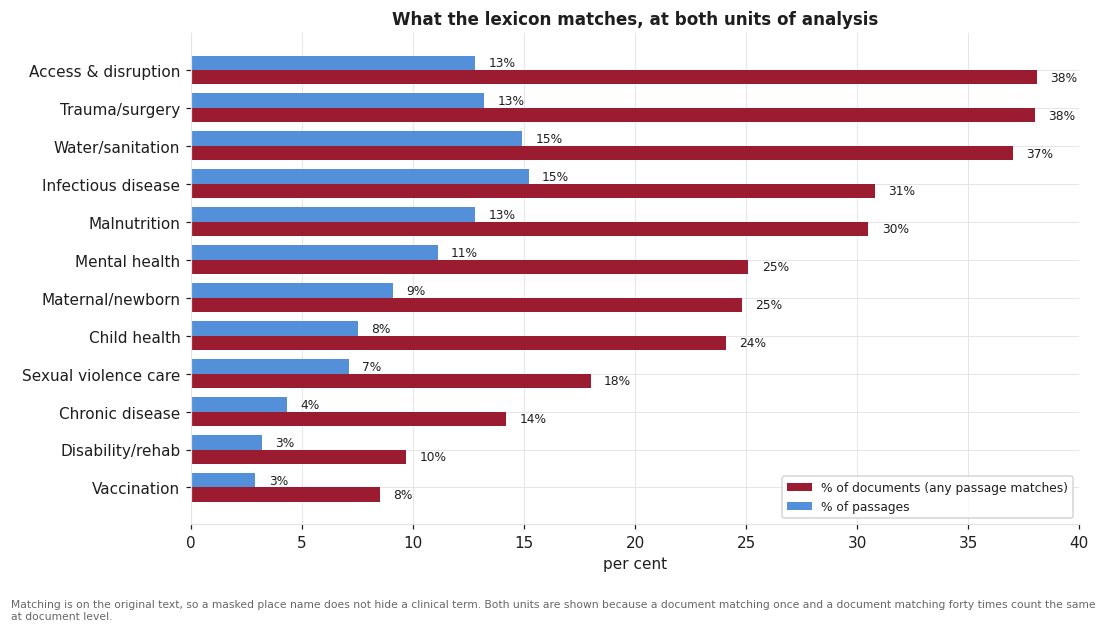


PRACTITIONER NOTE
  Keep the vocabulary as data, separate from the code that applies it: one altered character stops a
  term matching and no output will tell you. Match on the original text, not a cleaned or masked
  column, and report every count at both units, passages and documents.


In [ ]:
# @title
# ==================================================================================================
# PHASE: LEXICON                                                        stage 1 of 5 in this phase
# STAGE 6  THE HEALTH LEXICON
# WHAT THIS CELL DOES: marks which passages mention each of 12 health categories
# ==================================================================================================
# WHAT THIS CELL DOES
#   Applies a lexicon of regular-expression patterns, organised into scope categories and several
#   languages, to the original passage text, and reports how much of the corpus is in scope. The
#   built-in lexicon has twelve health categories; CODEBOOK_FILE (Stage 1) replaces it.
#
# WHY
#   The lexicon defines the subject of interest for the whole notebook. A passage is "in scope"
#   when it matches at least one category; the categories are data, not code, so pointing the
#   notebook at a different lexicon analyses a different subject.
#
# HOW
#   Matching runs on the original text (text_raw), never the masked column, because a place name is
#   masked to keep it out of the embedding while a subject term must still be found. Matched
#   strings are folded to one canonical English label per subject, so equivalent terms across
#   languages are counted once. The patterns themselves are kept exactly as written, since a single
#   altered character would silently stop a term from matching.

import os, re
import numpy as np, pandas as pd


# ---- Twelve required categories. Specific phrases only; no broad single-word roots. ----
CODEBOOK = {
"Trauma and surgery": {
 "en": [r"\bwar[- ]wounded\b", r"\bwar wounds?\b", r"\bblast injur\w*", r"\bgunshot wounds?\b",
        r"\bshrapnel\b", r"\bsurgical (?:care|team|ward|activit\w+|interventions?|procedures?)\b",
        r"\borthopaedic\b", r"\borthopedic\b", r"\bamputations?\b",
        r"\btrauma (?:care|surgery|patients?|unit|centre|center)\b", r"\boperating theatre\b",
        r"\bemergency surgery\b", r"\bburn(?:s)? (?:unit|patients?|victims?|care)\b",
        r"\bsevere burns?\b", r"\bwound (?:care|dressing|management)\b"],
 "fr": [r"\bblessés de guerre\b", r"\bblessures de guerre\b", r"\bblessé(?:e)?s? par balles?\b", r"\bblessures par balles?\b",
        r"\béclats d'obus\b", r"\bchirurgie (?:de guerre|d'urgence|orthopédique)\b",
        r"\bactivités chirurgicales\b", r"\bbloc opératoire\b", r"\bamputations?\b",
        r"\bsoins des plaies\b", r"\bgrands brûlés\b", r"\bbrûlures (?:graves|sévères)\b",
        r"\btraumatologi\w*", r"\b(?:soins|équipes?|activités|interventions?|actes) chirurgica\w*",
        r"\borthopédi(?:e|que|ques)\b", r"\b(?:patients?|victimes?) (?:de |des )?brûl\w+"],
 "es": [r"\bheridos de guerra\b", r"\bheridas de guerra\b", r"\bherid[oa]s de bala\b",
        r"\bmetralla\b", r"\btraumatolog\w*", r"\bortopédic[oa]s?\b",
        r"\bcirugía (?:de guerra|de urgencia|ortopédica)\b", r"\bactividad(?:es)? quirúrgica\w*",
        r"\bquirófano\b", r"\bamputaci\w+", r"\bquemaduras (?:graves|severas)\b",
        r"\bcuidado de heridas\b",
        r"\b(?:atención|equipos?|intervenciones|procedimientos) quirúrgic\w*",
        r"\b(?:unidad de|pacientes|víctimas de) quemad\w+"],
 "ar": [r"جرحى الحرب", r"إصابات الحرب", r"العمليات الجراحية", r"الجراحة الطارئة", r"بتر الأطراف"]},

"Infectious disease and outbreaks": {
 "en": [r"\bcholera\b", r"\bacute watery diarrho\w+", r"\bmeasles\b", r"\bmalaria\b",
        r"\btuberculosis\b", r"\bdiphtheria\b", r"\bwhooping cough\b", r"\bhepatitis [ABCE]\b",
        r"\bmpox\b", r"\bmonkeypox\b", r"\bebola\b", r"\bmarburg\b", r"\bdengue\b",
        r"\bkala[- ]azar\b", r"\bvisceral leishmaniasis\b", r"\bdisease outbreaks?\b",
        r"\bepidemics?\b", r"\bcase fatality rate\b", r"\bsuspected cases of\b"],
 "fr": [r"\bcholéra\b", r"\bdiarrhée aqueuse aiguë\b", r"\brougeole\b", r"\bpaludisme\b",
        r"\btuberculose\b", r"\bdiphtérie\b", r"\bcoqueluche\b", r"\bhépatite [ABCE]\b",
        r"\bvariole simienne\b", r"\bmpox\b", r"\bébola\b", r"\bdengue\b", r"\bépidémies?\b",
        r"\bflambée épidémique\b", r"\bcas suspects de\b"],
 "es": [r"\bcólera\b", r"\bdiarrea acuosa aguda\b", r"\bsarampión\b", r"\bmalaria\b",
        r"\bpaludismo\b", r"\btuberculosis\b", r"\bdifteria\b", r"\btos ferina\b",
        r"\bhepatitis [ABCE]\b", r"\bviruela símica\b", r"\bébola\b", r"\bdengue\b",
        r"\bbrote(?:s)? de\b", r"\bepidemias?\b"],
 "ar": [r"الكوليرا", r"الحصبة", r"الملاريا", r"السل\b", r"الدفتيريا", r"جدري القرود",
        r"تفشي المرض", r"وباء"]},

"Malnutrition": {
 "en": [r"\bmalnutrition\b", r"\bsevere acute malnutrition\b", r"\bglobal acute malnutrition\b",
        r"\bmoderate acute malnutrition\b", r"\btherapeutic feeding\b",
        r"\bnutritional (?:crisis|programme|program|centre|center)\b",
        r"\bready[- ]to[- ]use therapeutic food\b", r"\bRUTF\b", r"\bMUAC\b",
        r"\bmid[- ]upper arm circumference\b", r"\bwasting\b", r"\bstunting\b", r"\bfamine\b",
        r"\bfood insecurity\b", r"\bIPC phase\b"],
 "fr": [r"\bmalnutrition\b", r"\bmalnutrition aiguë sévère\b", r"\bmalnutrition aiguë globale\b",
        r"\balimentation thérapeutique\b", r"\bcentre nutritionnel\b", r"\bpérimètre brachial\b",
        r"\bfamine\b", r"\binsécurité alimentaire\b"],
 "es": [r"\bdesnutrición\b", r"\bdesnutrición aguda (?:grave|severa|global)\b", r"\bmalnutrición\b",
        r"\balimento terapéutico\b", r"\bcentro nutricional\b", r"\bhambruna\b",
        r"\binseguridad alimentaria\b"],
 "ar": [r"سوء التغذية", r"سوء التغذية الحاد", r"المجاعة", r"انعدام الأمن الغذائي"]},

"Mental health and psychosocial support": {
 "en": [r"\bmental health\b", r"\bpsychosocial (?:support|care|activit\w+|counsel\w+)\b",
        r"\bpsychological (?:support|care|first aid|consultations?)\b", r"\bpsychiatric care\b",
        r"\bcounselling sessions?\b", r"\bcounseling sessions?\b", r"\bMHPSS\b",
        r"\bpost[- ]traumatic stress\b", r"\bPTSD\b", r"\bpsychologists?\b", r"\bmental distress\b"],
 "fr": [r"\bsanté mentale\b", r"\bsoutien psychosocial\b", r"\bsoutien psychologique\b",
        r"\bprise en charge psychologique\b", r"\bconsultations? psychologiques?\b",
        r"\bpsychologues?\b", r"\bstress post[- ]traumatique\b", r"\bdétresse psychologique\b",
        r"\bsoins psychiatriques\b", r"\b(?:prise en charge|activités?) psychosociales?\b"],
 "es": [r"\bsalud mental\b", r"\bapoyo psicosocial\b", r"\bapoyo psicológico\b",
        r"\batención psicológica\b", r"\bconsultas? psicológicas?\b", r"\bpsicólogos?\b",
        r"\bestrés post[- ]traumático\b", r"\batención psiquiátrica\b",
        r"\bactividades psicosociales\b", r"\bangustia psicológica\b",
        r"\bprimeros auxilios psicológicos\b"],
 "ar": [r"الصحة النفسية", r"الدعم النفسي", r"الدعم النفسي والاجتماعي", r"الرعاية النفسية"]},

"Maternal and newborn health": {
 "en": [r"\bmaternal (?:health|care|mortality|deaths?)\b", r"\bantenatal care\b",
        r"\bprenatal care\b", r"\bpostnatal care\b",
        r"\bobstetric (?:care|emergenc\w+|violence|fistula)\b", r"\bcaesarean sections?\b",
        r"\bcesarean sections?\b", r"\bsafe deliver\w+\b", r"\bassisted deliveries\b",
        r"\bmaternity (?:ward|unit|hospital|services?|care)\b", r"\bmidwi(?:fe|ves|fery)\b",
        r"\bnewborn care\b", r"\bneonatal (?:care|unit|intensive)\b", r"\bpregnant women\b",
        r"\bfamily planning\b"],
 "fr": [r"\bsanté maternelle\b", r"\bmortalité maternelle\b", r"\bsoins prénatals?\b",
        r"\bconsultations? prénatales?\b", r"\bsoins postnatals?\b", r"\bcésariennes?\b",
        r"\baccouchements?\b", r"\bmaternité\b", r"\bsages[- ]femmes\b", r"\bsoins néonatals?\b",
        r"\bfemmes enceintes\b", r"\bplanification familiale\b"],
 "es": [r"\bsalud materna\b", r"\bmortalidad materna\b", r"\batención prenatal\b",
        r"\bcontrol prenatal\b", r"\batención postnatal\b", r"\bcesáreas?\b", r"\bpartos?\b",
        r"\bmaternidad\b", r"\bmatronas?\b", r"\bparteras?\b", r"\batención neonatal\b",
        r"\bmujeres embarazadas\b", r"\bplanificación familiar\b"],
 "ar": [r"صحة الأم", r"الرعاية السابقة للولادة", r"الولادة القيصرية", r"قسم الولادة",
        r"النساء الحوامل"]},

"Child health": {
 "en": [r"\bchild health\b", r"\bpaediatric\w*", r"\bpediatric\w*", r"\bchildren under (?:five|5)\b",
        r"\bunder[- ]fives?\b", r"\bchild mortality\b", r"\binfant mortality\b",
        r"\bchildren's (?:ward|hospital|clinic)\b", r"\bsick children\b",
        r"\bnewborns? and children\b", r"\bchild (?:patients?|deaths?)\b"],
 "fr": [r"\bsanté infantile\b", r"\bpédiatri\w+", r"\benfants de moins de cinq ans\b",
        r"\benfants de moins de 5 ans\b", r"\bmortalité infantile\b", r"\bservice pédiatrique\b",
        r"\benfants malades\b"],
 "es": [r"\bsalud infantil\b", r"\bpediátric\w+", r"\bpediatría\b",
        r"\bniños menores de cinco años\b", r"\bniños menores de 5 años\b",
        r"\bmortalidad infantil\b", r"\bniños enfermos\b"],
 "ar": [r"صحة الطفل", r"طب الأطفال", r"وفيات الأطفال", r"الأطفال دون سن الخامسة"]},

# The bare French root "viol" is deliberately absent. Specific phrases only.
"Sexual and gender-based violence care": {
 "en": [r"\bsexual violence\b", r"\bsexual assaults?\b", r"\bsexual abuse\b",
        r"\bgender[- ]based violence\b", r"\bsurvivors? of sexual\b", r"\brape survivors?\b",
        r"\bpost[- ]rape care\b", r"\bintimate partner violence\b", r"\bSGBV\b", r"\bGBV\b",
        r"\bsexual and reproductive (?:health|violence)\b", r"\bsexual exploitation\b"],
 "fr": [r"\bviolences? sexuelles?\b", r"\bagressions? sexuelles?\b", r"\babus sexuels?\b",
        r"\bviolences? basées? sur le genre\b", r"\bviolences? sexistes\b",
        r"\bsurvivantes? de violences? sexuelles?\b", r"\bvictimes? de violences? sexuelles?\b",
        r"\bsanté sexuelle et reproductive\b", r"\bexploitation sexuelle\b"],
 "es": [r"\bviolencia sexual\b", r"\bagresiones? sexuales?\b", r"\babuso sexual\b",
        r"\bviolencia de género\b", r"\bsobrevivientes de violencia sexual\b",
        r"\bvíctimas de violencia sexual\b", r"\bsalud sexual y reproductiva\b",
        r"\bexplotación sexual\b"],
 "ar": [r"العنف الجنسي", r"الاعتداء الجنسي", r"العنف القائم على النوع الاجتماعي",
        r"الناجيات من العنف"]},

"Vaccination and immunisation": {
 "en": [r"\bvaccination campaigns?\b",
        r"\bvaccination (?:activit\w+|drive|round|coverage|sites?)\b",
        r"\bimmunis\w+ (?:campaign|coverage|programme|program|activit\w+)\b",
        r"\bimmuniz\w+ (?:campaign|coverage|programme|program|activit\w+)\b",
        r"\bvaccinated (?:against|children)\b", r"\bdoses of vaccine\b",
        r"\broutine vaccination\b", r"\bcold chain\b", r"\bEPI\b"],
 "fr": [r"\bcampagnes? de vaccination\b", r"\bactivités de vaccination\b",
        r"\bcouverture vaccinale\b", r"\bvaccination de routine\b", r"\bdoses de vaccin\b",
        r"\bchaîne du froid\b"],
 "es": [r"\bcampañas? de vacunación\b", r"\bactividades de vacunación\b",
        r"\bcobertura de vacunación\b", r"\bvacunación de rutina\b", r"\bdosis de vacuna\b",
        r"\bcadena de frío\b"],
 "ar": [r"حملة التطعيم", r"حملات التطعيم", r"التحصين", r"جرعات اللقاح"]},

"Water, sanitation and hygiene": {
 "en": [r"\bsafe drinking water\b", r"\bclean water\b", r"\bdrinking water\b", r"\bwater supply\b",
        r"\bwater points?\b", r"\bwater trucking\b", r"\bwater treatment\b", r"\bsanitation\b",
        r"\blatrines?\b", r"\bsewage\b", r"\bhygiene (?:kits?|promotion|conditions?)\b",
        r"\bWASH (?:activit\w+|programme|program|team)\b", r"\bchlorinat\w+",
        r"\baccess to (?:clean |safe )?water\b", r"\bwater distributions?\b"],
 "fr": [r"\beau potable\b", r"\bapprovisionnement en eau\b", r"\bpoints? d'eau\b",
        r"\btraitement de l'eau\b", r"\bassainissement\b", r"\blatrines?\b", r"\beaux usées\b",
        r"\bkits? d'hygiène\b", r"\bpromotion de l'hygiène\b", r"\bchloration\b",
        r"\beau propre\b", r"\baccès à l'eau\b", r"\bdistributions? d'eau\b",
        r"\bcamions?[- ]citernes?\b", r"\bconditions d'hygiène\b"],
 "es": [r"\bagua potable\b", r"\bsuministro de agua\b", r"\bpuntos? de agua\b",
        r"\btratamiento de agua\b", r"\bsaneamiento\b", r"\bletrinas?\b", r"\baguas residuales\b",
        r"\bkits? de higiene\b", r"\bpromoción de la higiene\b", r"\bcloración\b",
        r"\bagua limpia\b", r"\bacceso al agua\b", r"\bdistribuci(?:ón|ones) de agua\b",
        r"\bcamiones? cisterna\b", r"\bcondiciones de higiene\b"],
 "ar": [r"مياه الشرب", r"المياه النظيفة", r"الصرف الصحي", r"إمدادات المياه", r"النظافة"]},

"Chronic and non-communicable disease": {
 "en": [r"\bnon[- ]communicable diseases?\b", r"\bNCDs?\b",
        r"\bchronic (?:disease|illness|condition|patients?|care)\b", r"\bdiabet(?:es|ic)\b",
        r"\bhypertension\b", r"\bhigh blood pressure\b", r"\bcardiovascular disease\b",
        r"\bkidney (?:failure|disease)\b", r"\bdialysis\b",
        r"\bcancer (?:care|patients?|treatment)\b", r"\basthma\b", r"\bepilepsy\b",
        r"\binsulin\b", r"\bchronic medication\b"],
 "fr": [r"\bmaladies non transmissibles\b", r"\bmaladies chroniques\b", r"\bdiabète\b",
        r"\bhypertension\b", r"\bmaladies cardiovasculaires\b", r"\binsuffisance rénale\b",
        r"\bdialyse\b", r"\btraitement du cancer\b", r"\basthme\b", r"\bépilepsie\b",
        r"\binsuline\b"],
 "es": [r"\benfermedades no transmisibles\b", r"\benfermedades crónicas\b", r"\bdiabetes\b",
        r"\bhipertensión\b", r"\benfermedades cardiovasculares\b", r"\binsuficiencia renal\b",
        r"\bdiálisis\b", r"\btratamiento del cáncer\b", r"\basma\b", r"\bepilepsia\b",
        r"\binsulina\b"],
 "ar": [r"الأمراض المزمنة", r"الأمراض غير المعدية", r"السكري", r"ارتفاع ضغط الدم",
        r"غسيل الكلى"]},

"Disability and rehabilitation": {
 "en": [r"\bphysiotherap\w+",
        r"\brehabilitation (?:care|services?|centre|center|programme|program|activit\w+|sessions?)\b",
        r"\bpost[- ]operative rehabilitation\b", r"\bprosthe(?:sis|ses|tic\w*)\b", r"\borthotic\w*",
        r"\bmobility aids?\b", r"\bwheelchairs?\b", r"\bpeople with disabilit\w+",
        r"\bpersons with disabilit\w+", r"\bpermanent disabilit\w+", r"\bassistive devices?\b"],
 "fr": [r"\bkinésithérap\w+", r"\bphysiothérap\w+", r"\bréadaptation\b", r"\brééducation\b",
        r"\bprothèses?\b", r"\bfauteuils? roulants?\b",
        r"\bpersonnes? (?:en situation de )?handicap\w*", r"\bhandicap permanent\b"],
 "es": [r"\bfisioterap\w+", r"\brehabilitación\b", r"\bprótesis\b", r"\bsillas? de ruedas\b",
        r"\bpersonas con discapacidad\b", r"\bdiscapacidad permanente\b"],
 "ar": [r"العلاج الطبيعي", r"إعادة التأهيل", r"الأطراف الصناعية", r"ذوي الإعاقة"]},

"Health-system access and disruption": {
 "en": [r"\bhospital was (?:damaged|destroyed|hit|shelled|bombed)\b", r"\bdamage to the hospital\b",
        r"\bforced to (?:close|suspend|evacuate)\b",
        r"\bsuspended (?:its |our )?(?:activities|operations|services)\b",
        r"\bhospital (?:closed|closure|out of service|non[- ]functional)\b",
        r"\bhealth (?:facilities|centres|centers) (?:closed|destroyed|damaged)\b",
        r"\battacks? on (?:health|healthcare|health care|hospitals?|medical)\b",
        r"\bhospital (?:was )?(?:struck|shelled|stormed|raided)\b",
        r"\bambulances? (?:hit|struck|targeted|attacked)\b",
        r"\bhealth workers? (?:killed|detained|arrested|wounded)\b",
        r"\bshortage of (?:medicines?|drugs?|medical supplies|fuel|oxygen|blood)\b",
        r"\brunning out of (?:medicines?|supplies|fuel|oxygen)\b", r"\bstock[- ]?outs?\b",
        r"\bmedical supplies (?:are )?(?:blocked|denied|not allowed|running low)\b",
        r"\black of (?:medicines?|medical supplies|equipment|fuel|oxygen)\b",
        r"\bshortage of (?:staff|health workers|doctors|nurses|surgeons)\b",
        r"\black of (?:staff|health workers|qualified staff|specialists)\b",
        r"\btoo few (?:doctors|nurses|staff)\b", r"\breferral (?:system|pathway|barriers?)\b",
        r"\bunable to refer\b", r"\bcannot (?:reach|access) (?:the )?hospital\b",
        r"\bno ambulances? available\b", r"\bambulances? (?:blocked|denied|delayed)\b",
        r"\bmedical evacuations? (?:blocked|denied|delayed)\b", r"\bhumanitarian access\b",
        r"\baccess (?:was |is )?(?:denied|restricted|blocked)\b",
        r"\bdenied (?:entry|permission|access)\b", r"\bpermits? (?:were |was )?denied\b",
        r"\bcheckpoints?\b", r"\bunder siege\b", r"\bblockade\b",
        r"\bconvoys? (?:blocked|denied|turned back)\b"],
 "fr": [r"\bhôpital (?:bombardé|détruit|endommagé|touché|frappé)\b",
        r"\battaques? contre (?:des )?(?:hôpitaux|structures? de santé|le personnel)\b",
        r"\b(?:contraint|obligé)(?:e|s|es)? de (?:fermer|suspendre|évacuer|quitter)\b", r"\bsuspension des activités\b",
        r"\bhors service\b",
        r"\bpénurie de (?:médicaments|personnel|carburant|matériel médical|oxygène)\b",
        r"\brupture de stock\b", r"\bmanque de (?:médicaments|personnel|matériel)\b",
        r"\bpersonnel (?:de santé )?(?:tué|détenu|arrêté|blessé)\b", r"\baccès humanitaire\b",
        r"\baccès (?:refusé|restreint|bloqué|entravé)\b", r"\bpoints? de contrôle\b",
        r"\bblocus\b", r"\bévacuations? médicales? (?:refusées?|bloquées?|retardées?)\b"],
 "es": [r"\bhospital (?:bombardeado|destruido|dañado|atacado)\b",
        r"\bataques? contra (?:hospitales|centros de salud|personal)\b",
        r"\bobligad[oa]s? a (?:cerrar|suspender|evacuar|abandonar)\b", r"\bsuspensión de (?:las )?actividades\b",
        r"\bfuera de servicio\b",
        r"\bescasez de (?:medicamentos|personal|combustible|suministros médicos|oxígeno)\b",
        r"\bdesabastecimiento\b", r"\bfalta de (?:medicamentos|personal|equipos)\b",
        r"\bpersonal (?:sanitario |de salud )?(?:asesinado|detenido|herido)\b",
        r"\bacceso humanitario\b", r"\bacceso (?:denegado|restringido|bloqueado)\b",
        r"\bpuntos? de control\b", r"\basedio\b", r"\bbloqueo\b",
        r"\bevacuaciones? médicas? (?:denegadas?|bloqueadas?)\b"],
 "ar": [r"استهداف المستشفى", r"الهجمات على المرافق الصحية", r"نقص الأدوية",
        r"نقص الإمدادات الطبية", r"الوصول الإنساني", r"إغلاق المستشفى", r"الحصار",
        r"نقاط التفتيش"]},
}

# Sub-concepts inside health-system access and disruption, reported separately.
BARRIER_SUBTYPES = {
 "Hospital damage or closure": [
   r"\bhospital was (?:damaged|destroyed|hit|shelled|bombed)\b", r"\bdamage to the hospital\b",
   r"\bforced to (?:close|suspend|evacuate)\b",
   r"\bsuspended (?:its |our )?(?:activities|operations|services)\b",
   r"\bhospital (?:closed|closure|out of service|non[- ]functional)\b",
   r"\bhealth (?:facilities|centres|centers) (?:closed|destroyed|damaged)\b",
   r"\bhôpital (?:bombardé|détruit|endommagé|touché|frappé)\b",
   r"\b(?:contraint|obligé)(?:e|s|es)? de (?:fermer|suspendre|évacuer|quitter)\b", r"\bsuspension des activités\b",
   r"\bhors service\b", r"\bhospital (?:bombardeado|destruido|dañado|atacado)\b",
   r"\bobligad[oa]s? a (?:cerrar|suspender|evacuar|abandonar)\b", r"\bsuspensión de (?:las )?actividades\b",
   r"\bfuera de servicio\b", r"استهداف المستشفى", r"إغلاق المستشفى"],
 "Attacks on health care": [
   r"\battacks? on (?:health|healthcare|health care|hospitals?|medical)\b",
   r"\bhospital (?:was )?(?:struck|shelled|stormed|raided)\b",
   r"\bambulances? (?:hit|struck|targeted|attacked)\b",
   r"\bhealth workers? (?:killed|detained|arrested|wounded)\b",
   r"\battaques? contre (?:des )?(?:hôpitaux|structures? de santé|le personnel)\b",
   r"\bpersonnel (?:de santé )?(?:tué|détenu|arrêté|blessé)\b",
   r"\bataques? contra (?:hospitales|centros de salud|personal)\b",
   r"\bpersonal (?:sanitario |de salud )?(?:asesinado|detenido|herido)\b",
   r"الهجمات على المرافق الصحية"],
 "Medicine or supply shortage": [
   r"\bshortage of (?:medicines?|drugs?|medical supplies|fuel|oxygen|blood)\b",
   r"\brunning out of (?:medicines?|supplies|fuel|oxygen)\b", r"\bstock[- ]?outs?\b",
   r"\bmedical supplies (?:are )?(?:blocked|denied|not allowed|running low)\b",
   r"\black of (?:medicines?|medical supplies|equipment|fuel|oxygen)\b",
   r"\bpénurie de (?:médicaments|carburant|matériel médical|oxygène)\b", r"\brupture de stock\b",
   r"\bmanque de (?:médicaments|matériel)\b",
   r"\bescasez de (?:medicamentos|combustible|suministros médicos|oxígeno)\b",
   r"\bdesabastecimiento\b", r"\bfalta de (?:medicamentos|equipos)\b",
   r"نقص الأدوية", r"نقص الإمدادات الطبية"],
 "Health-worker shortage": [
   r"\bshortage of (?:staff|health workers|doctors|nurses|surgeons)\b",
   r"\black of (?:staff|health workers|qualified staff|specialists)\b",
   r"\btoo few (?:doctors|nurses|staff)\b", r"\bpénurie de personnel\b",
   r"\bmanque de personnel\b", r"\bescasez de personal\b", r"\bfalta de personal\b"],
 "Referral or transport barrier": [
   r"\breferral (?:system|pathway|barriers?)\b", r"\bunable to refer\b",
   r"\bcannot (?:reach|access) (?:the )?hospital\b", r"\bno ambulances? available\b",
   r"\bambulances? (?:blocked|denied|delayed)\b",
   r"\bmedical evacuations? (?:blocked|denied|delayed)\b",
   r"\bévacuations? médicales? (?:refusées?|bloquées?|retardées?)\b",
   r"\bevacuaciones? médicas? (?:denegadas?|bloqueadas?)\b"],
 "Humanitarian access restriction": [
   r"\bhumanitarian access\b", r"\baccess (?:was |is )?(?:denied|restricted|blocked)\b",
   r"\bdenied (?:entry|permission|access)\b", r"\bpermits? (?:were |was )?denied\b",
   r"\bcheckpoints?\b", r"\bunder siege\b", r"\bblockade\b",
   r"\bconvoys? (?:blocked|denied|turned back)\b", r"\baccès humanitaire\b",
   r"\baccès (?:refusé|restreint|bloqué|entravé)\b", r"\bpoints? de contrôle\b", r"\bblocus\b",
   r"\bacceso humanitario\b", r"\bacceso (?:denegado|restringido|bloqueado)\b",
   r"\bpuntos? de control\b", r"\basedio\b", r"\bbloqueo\b",
   r"الوصول الإنساني", r"الحصار", r"نقاط التفتيش"],
}

SHORT_LABELS = {
 "Trauma and surgery": "Trauma/surgery",
 "Infectious disease and outbreaks": "Infectious disease",
 "Malnutrition": "Malnutrition",
 "Mental health and psychosocial support": "Mental health",
 "Maternal and newborn health": "Maternal/newborn",
 "Child health": "Child health",
 "Sexual and gender-based violence care": "Sexual violence care",
 "Vaccination and immunisation": "Vaccination",
 "Water, sanitation and hygiene": "Water/sanitation",
 "Chronic and non-communicable disease": "Chronic disease",
 "Disability and rehabilitation": "Disability/rehab",
 "Health-system access and disruption": "Access & disruption",
}

# ---- The specific subject named inside a category --------------------------------------
# Matched strings appear in several languages and inflections. They are folded to one canonical
# English label, so equivalent spellings across languages count as one subject.
CANONICAL = {
 r"chol[ée]?ra|cólera|acute watery|diarrh": "cholera / acute watery diarrhoea",
 r"measles|rougeole|sarampión": "measles",
 r"malaria|paludisme": "malaria",
 r"tubercul": "tuberculosis",
 r"mpox|monkeypox|variole simienne|viruela": "mpox",
 r"ebola|marburg": "Ebola / Marburg",
 r"dengue|leishman|chikungunya|kala": "dengue and other vector-borne",
 r"hepatit|hépatit": "hepatitis",
 r"diphther|dipht[ée]r|difteria|whooping|coquelu|tos ferina": "diphtheria / pertussis",
 r"pneumonia|pneumonie|neumonía|respiratory infection|infection respiratoire|covid": "respiratory infection",
 r"epidemic|épidémi|epidemia|outbreak|flambée|brote": "outbreak (unspecified)",
 r"case fatality|suspected cases": "outbreak surveillance wording",
 r"malnutrition|desnutrición|malnutrición": "malnutrition",
 r"famine|hambruna": "famine",
 r"food insecurity|insécurité alimentaire|inseguridad alimentaria": "food insecurity",
 r"therapeutic feed|alimentation thérapeutique|alimento terapéutico|RUTF|nutritional": "therapeutic feeding",
 r"wasting|stunting|MUAC|périmètre brachial|mid-upper": "nutrition measurement",
 r"caesarean|cesarean|césarien|cesárea": "caesarean section",
 r"antenatal|prenatal|prénatal": "antenatal care",
 r"postnatal": "postnatal care",
 r"midwi|sages|matrona|partera": "midwifery",
 r"maternity|maternité|maternidad": "maternity services",
 r"neonatal|néonat|newborn": "newborn care",
 r"pregnant|enceinte|embarazada": "pregnant women",
 r"deliver|accouchement|parto": "deliveries",
 r"maternal": "maternal health (general)",
 r"family planning|planification familiale|planificación familiar": "family planning",
 r"sexual violence|violencia sexual|violences? sexuelle": "sexual violence",
 r"sexual assault|agression|abus sexuel|abuso sexual": "sexual assault or abuse",
 r"gender[- ]based|basées? sur le genre|violencia de género|sexiste": "gender-based violence",
 r"survivor|survivante|sobrevivient|víctima|victime": "survivors of sexual violence",
 r"\bSGBV\b|\bGBV\b": "SGBV (abbreviation)",
 r"sexual and reproductive|santé sexuelle|salud sexual": "sexual and reproductive health",
 r"sexual exploitation|exploitation sexuelle|explotación sexual": "sexual exploitation",
 r"rape": "care after rape",
 r"vaccinat|vacunac|immunis|immuniz|vaccin|tratamiento|dose": "vaccination activity",
 r"cold chain|chaîne du froid|cadena de frío": "cold chain",
 r"drinking water|eau potable|agua potable|clean water": "drinking water",
 r"water supply|water point|water trucking|approvisionnement|suministro|punto": "water supply",
 r"sanitation|assainissement|saneamiento|latrine|sewage|eaux usées|residuales": "sanitation and latrines",
 r"hygien|higiene": "hygiene",
 r"chlorinat|chloration|cloración|water treatment|traitement de l'eau|tratamiento de agua": "water treatment",
 r"diabet": "diabetes",
 r"hypertens|blood pressure": "hypertension",
 r"dialys|diális|kidney|rénale": "kidney disease and dialysis",
 r"cancer": "cancer",
 r"asthma|asthme|asma": "asthma",
 r"epilep|épilep": "epilepsy",
 r"insulin": "insulin",
 r"non[- ]communicable|non transmissibles|no transmisibles|\bNCD": "non-communicable disease (general)",
 r"chronic|chronique|crónic": "chronic condition (general)",
 r"physiother|kinésith|fisioterap|physioth": "physiotherapy",
 r"rehabilit|réadaptation|rééducation|rehabilitación": "rehabilitation services",
 r"prosthe|prothèse|prótesis|orthotic": "prosthetics and orthotics",
 r"wheelchair|fauteuil|silla de ruedas|mobility aid|assistive": "mobility aids",
 r"disabilit|handicap|discapacidad": "people with disabilities",
 r"mental health|santé mentale|salud mental": "mental health (general)",
 r"psychosocial": "psychosocial support",
 r"psycholog|psicólog|psicológ": "psychological care",
 r"psychiatric": "psychiatric care",
 r"counsel": "counselling",
 r"PTSD|post[- ]trauma|stress post": "post-traumatic stress",
 r"distress|détresse": "psychological distress",
 r"war[- ]wound|blessés de guerre|heridos de guerra|blessures de guerre|heridas de guerra": "war wounds",
 r"gunshot|balle|bala": "gunshot wounds",
 r"blast|shrapnel|éclats|obus": "blast and shrapnel injuries",
 r"surgical|surgery|chirurg|cirugía|quirúrg|quirófano|opératoire": "surgical activity",
 r"orthopa|orthope|orthopéd|ortopéd": "orthopaedic care",
 r"amputat": "amputation",
 r"burn|brûlure|quemadura": "burns",
 r"wound|plaie|herida": "wound care",
 r"paediatric|pediatric|pédiatr|pediátr|pediatría": "paediatric services",
 r"under.{0,6}(five|5)|moins de cinq|moins de 5|menores de cinco|menores de 5": "children under five",
 r"child (mortality|deaths?)|mortalité infantile|mortalidad infantil": "child mortality",
 r"infant mortality": "infant mortality",
 r"child health|santé infantile|salud infantil": "child health (general)",
 r"sick children|enfants malades|niños enfermos|children's": "sick children",
 r"attacks? on|attaques? contre|ataques? contra": "attacks on health care",
 r"struck|shelled|stormed|raided|bombard|bombarde|destru|damaged|endommag|dañad": "facility damage",
 r"forced to (close|suspend|evacuate)|contraint|oblig[ée]|obligad|suspend|suspension|suspensión": "closure or suspension",
 r"shortage of (staff|health workers|doctors|nurses|surgeons)|pénurie de personnel|manque de personnel|escasez de personal|falta de personal|too few": "health-worker shortage",
 r"shortage|pénurie|escasez|stock|rupture|desabastecimiento|running out|lack of": "medicine or supply shortage",
 r"referral|référence|unable to refer|cannot (reach|access)": "referral barrier",
 r"ambulance|evacuation|évacuation|evacuación": "ambulance and evacuation",
 r"humanitarian access|accès humanitaire|acceso humanitario": "humanitarian access",
 r"denied|refusé|denegado|restricted|restreint|restringido|blocked|bloqué|bloqueado|permit": "access denied or restricted",
 r"checkpoint|point de contrôle|punto de control": "checkpoints",
 r"siege|assiég|asediad|blockade|blocus|bloqueo|convoy": "siege or blockade",
 r"health workers? (killed|detained|arrested|wounded)|personnel.{0,12}(tué|détenu|arrêté|blessé)|personal.{0,12}(asesinado|detenido|herido)": "harm to health workers",
 r"out of service|hors service|fuera de servicio|non[- ]functional": "facility out of service",
}

# Additional folds, covering spellings the patterns above do not reach.
CANONICAL.update({
    r"siege|assi[ée]g|asedi|blockade|blocus|bloqueo|convoy": "siege or blockade",
    r"shortage|p[ée]nurie|escasez|stock|rupture|desabastecimiento|running out|lack of|falta de|manque de": "medicine or supply shortage",
    r"water point|point d'eau|points? d'eau|punto de agua|water supply|approvisionnement|suministro": "water supply",
    r"therapeutic feed|alimentation th[ée]rapeutique|alimento terap[ée]utico|RUTF|nutritional|centre nutritionnel|centro nutricional": "therapeutic feeding",
    r"IPC phase|ipc phase|wasting|stunting|MUAC|p[ée]rim[èe]tre brachial|mid-upper": "nutrition measurement",
    r"hospital was (bombed|hit|struck|shelled|destroyed|damaged)": "facility damage",
    r"hypertens|blood pressure|hipertens": "hypertension",
    r"diabet|diabète": "diabetes",
    r"amputat|amputaci|amputación": "amputation",
    r"malaria|paludisme|paludismo": "malaria",
    r"chol[ée]?ra|cólera|acute watery|diarrh|diarrea acuosa": "cholera / acute watery diarrhoea",
    r"sanitation|assainissement|saneamiento|latrine|letrina|sewage|eaux usées|residuales": "sanitation and latrines",
    r"checkpoint|point de contr|punto de control|points? de contr": "checkpoints",
    r"obstetric|obstétri|obstétrica": "obstetric care",
    r"maternal|maternelle|materna": "maternal health (general)",
    r"psychosocial|psicosocial": "psychosocial support",
    r"burn|brûlure|quemadura|brûlés": "burns",
    r"suspected cases|cas suspects|casos sospechosos": "outbreak surveillance wording",
    r"cardiovascular|cardiovasculaire|cardiovascular": "cardiovascular disease",
    r"wheelchair|fauteuil|silla de ruedas|sillas de ruedas|mobility aid|assistive": "mobility aids",
    r"hygien|higiene|kits? d'hygi": "hygiene",
    r"agress|agresion|agresiones": "sexual assault or abuse",
    r"operating theatre|bloc opératoire|quirófano": "operating theatre",
    r"trauma (care|patients?|unit|centre|center)": "trauma care",
    r"surgical|surgery|chirurg|cirugía|quirúrg|opératoire": "surgical activity",
    r"hospital (was )?(hit|struck|shelled|closed|destroyed|damaged|bombard)|health facilities (destroyed|damaged|closed)": "facility damage",
})


# ---- a lexicon from a file, for another subject (CODEBOOK_FILE in Stage 1) ----
# The file replaces the built-in lexicon above. Every pattern is compiled here, so a mistake stops
# the notebook at this cell with the category, language and pattern named.
LEXICON_SOURCE = "built-in"
if CFG.codebook_file:
    import json
    with open(CFG.codebook_file, encoding="utf-8") as _fh:
        _book = json.load(_fh)
    CODEBOOK = {str(category): {str(language): [str(p) for p in patterns]
                                for language, patterns in languages.items()}
                for category, languages in _book["categories"].items()}
    SHORT_LABELS = {category: str(_book.get("short_labels", {}).get(category, category))
                    for category in CODEBOOK}
    CANONICAL = {str(k): str(v) for k, v in _book.get("canonical", {}).items()}
    BARRIER_SUBTYPES = {str(k): [str(p) for p in v]
                        for k, v in _book.get("sub_concepts", {}).items()}
    for _category, _languages in CODEBOOK.items():
        for _language, _patterns in _languages.items():
            for _pattern in _patterns:
                try:
                    re.compile(_pattern)
                except re.error as exc:
                    raise ValueError(f"CODEBOOK_FILE, {_category} ({_language}): {_pattern!r} is "
                                     f"not a valid regular expression ({exc}).")
    LEXICON_SOURCE = os.path.basename(CFG.codebook_file)

# ---- compile once ------------------------------------------------------------
CATEGORIES = list(CODEBOOK)
def lexicon_pattern(pattern):
    """Compile one lexicon pattern so it matches either the straight or the typographic apostrophe,
    since French text in this corpus uses both."""
    out, depth = [], 0
    for character in pattern:
        depth += {"[": 1, "]": -1}.get(character, 0) if depth or character == "[" else 0
        out.append("['\u2019]" if character == "'" and depth == 0 else character)
    return re.compile("".join(out), re.I)


COMPILED = {category: {language: [lexicon_pattern(pattern) for pattern in patterns]
                       for language, patterns in languages.items()}
            for category, languages in CODEBOOK.items()}
COMPILED_BARRIERS = {barrier: [lexicon_pattern(pattern) for pattern in patterns]
                     for barrier, patterns in BARRIER_SUBTYPES.items()}
CANONICAL_COMPILED = [(lexicon_pattern(pattern), label) for pattern, label in CANONICAL.items()]
# A check that can fail: a pattern written with a straight apostrophe matches a typographic one.
assert lexicon_pattern("d'urgence").search("chirurgie d\u2019urgence"), (
    "The typographic apostrophe is not accepted; check lexicon_pattern.")

CAT_COLS = [f"cat::{category}" for category in CATEGORIES]
BAR_COLS = [f"bar::{barrier}" for barrier in BARRIER_SUBTYPES]


def category_matches(text, category):
    """True when any pattern in any language matches."""
    return any(pattern.search(text)
               for patterns in COMPILED[category].values() for pattern in patterns)


def category_match_detail(text, category):
    """Every (language, pattern, matched string) for one category. Used by the validation sample,
    so a reader can see exactly which words caused a match."""
    found = []
    for language, patterns in COMPILED[category].items():
        for pattern in patterns:
            found_match = pattern.search(text)
            if found_match:
                found.append((language, pattern.pattern, found_match.group(0)))
    return found


def canonical_subject(matched_string):
    """Fold a matched term to one canonical English label, so equivalent spellings across
    languages are counted as one subject."""
    for pattern, label in CANONICAL_COMPILED:
        if pattern.search(matched_string):
            return label
    return None


# ---- tag every passage on the ORIGINAL text ---------------------------------
MATCH_COLUMN = "text_raw"
for category in CATEGORIES:
    passages[f"cat::{category}"] = passages[MATCH_COLUMN].map(
        lambda text, c=category: category_matches(str(text), c))
for barrier in BARRIER_SUBTYPES:
    passages[f"bar::{barrier}"] = passages[MATCH_COLUMN].map(
        lambda text, ps=COMPILED_BARRIERS[barrier]: any(p.search(str(text)) for p in ps))

passages["scope_hits"] = passages[CAT_COLS].sum(axis=1)
passages["in_scope"] = passages["scope_hits"] > 0

CORPUS_SIGNATURE = fingerprint(passages[MATCH_COLUMN].astype(str).tolist())

# ---- report ------------------------------------------------------------------
N_PATTERNS = sum(len(patterns) for languages in CODEBOOK.values()
                 for patterns in languages.values())
PATTERN_LANGUAGES = sorted({language for languages in CODEBOOK.values()
                            for language in languages})

heading("STAGE 6  THE HEALTH LEXICON")
print(f"  lexicon               : {LEXICON_SOURCE}")
print(f"  categories            : {len(CATEGORIES)}")
print(f"  patterns              : {N_PATTERNS:,}")
print(f"  pattern languages     : {', '.join(PATTERN_LANGUAGES)}")
print(f"  barrier subtypes      : {len(BARRIER_SUBTYPES)}")
print(f"  subject folds         : {len(CANONICAL)}")
print(f"  matched on            : '{MATCH_COLUMN}', the ORIGINAL text, not the masked column")
# The lexicon in use, in the CODEBOOK_FILE format: an appendix for the thesis, and a template for
# another subject.
import json
LEXICON_EXPORT = os.path.join(FIGURE_DIR, "s06_lexicon.json")
with open(LEXICON_EXPORT, "w", encoding="utf-8") as _fh:
    json.dump({"categories": CODEBOOK, "short_labels": SHORT_LABELS, "canonical": CANONICAL,
               "sub_concepts": BARRIER_SUBTYPES}, _fh, ensure_ascii=False, indent=1)
print(f"  lexicon written       : {LEXICON_EXPORT}")
print()

# A specific known hazard, not a general hope: the bare French token for rape also means violin and
# violation, so it must never appear as a pattern on its own.
_bare_viol_absent = not any(
    pattern.strip("\\b") == "viol"
    for languages in CODEBOOK.values() for patterns in languages.values() for pattern in patterns)
print(f"  the bare French token 'viol' is absent from every pattern: {_bare_viol_absent}")
assert _bare_viol_absent, ("A pattern is the bare token 'viol', which also matches violin and "
                           "violation. Remove it or make it more specific.")

# ---- how much of the corpus is in scope, at BOTH units ----------------------
passage_share = float(passages["in_scope"].mean())
document_flags = passages.groupby("doc_id")["in_scope"].max()
document_share = float(document_flags.mean())

print()
print("  HOW MUCH OF THE CORPUS IS IN SCOPE")
print(f"    passages in scope   : {int(passages['in_scope'].sum()):,} of {len(passages):,} "
      f"({passage_share:.1%})")
print(f"    documents in scope  : {int(document_flags.sum()):,} of {len(document_flags):,} "
      f"({document_share:.1%})")
print("    A document counts as in scope when ANY of its passages matches, so the document figure")
print("    is always the higher of the two; every later count states which unit it uses.")
report("scope.passages_in_scope", int(passages["in_scope"].sum()), "passages", "Stage 6")
report("scope.documents_in_scope", int(document_flags.sum()), "documents", "Stage 6")
report("scope.passage_share", round(passage_share, 4), "proportion", "Stage 6")
report("scope.document_share", round(document_share, 4), "proportion", "Stage 6")

# ---- per category, at both units --------------------------------------------
rows = []
for category in CATEGORIES:
    column = f"cat::{category}"
    by_document = passages.groupby("doc_id")[column].max()
    rows.append({
        "category": SHORT_LABELS.get(category, category),
        "passages": int(passages[column].sum()),
        "passage_pct": round(100 * passages[column].mean(), 1),
        "documents": int(by_document.sum()),
        "document_pct": round(100 * by_document.mean(), 1),
        "patterns": sum(len(p) for p in CODEBOOK[category].values()),
    })
CATEGORY_TABLE = pd.DataFrame(rows).sort_values("documents", ascending=False)
print()
print("  BY CATEGORY. 'documents' counts a document once however many times it matches.")
print(CATEGORY_TABLE.to_string(index=False))
CATEGORY_TABLE.to_csv(os.path.join(FIGURE_DIR, "s06_category_counts.csv"), index=False)

_never = CATEGORY_TABLE[CATEGORY_TABLE["documents"] == 0]["category"].tolist()
if _never:
    print()
    print(f"  NO MATCH AT ALL: {', '.join(_never)}")
    print("  This is a limitation of the lexicon, not evidence the subject is absent from the")
    print("  corpus.")
rule()

# ---- figure ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5.4))
order = CATEGORY_TABLE.sort_values("document_pct")
positions = np.arange(len(order))
ax.barh(positions - 0.19, order["document_pct"], height=0.38, color=ACCENT,
        label="% of documents (any passage matches)")
ax.barh(positions + 0.19, order["passage_pct"], height=0.38, color="#5390D9",
        label="% of passages")
ax.set_yticks(positions); ax.set_yticklabels(order["category"])
ax.set_xlabel("per cent")
ax.set_title("What the lexicon matches, at both units of analysis", fontsize=11)
ax.legend(fontsize=8, loc="lower right")
for position, (document_pct, passage_pct) in enumerate(zip(order["document_pct"],
                                                           order["passage_pct"])):
    ax.text(document_pct + 0.6, position - 0.19, f"{document_pct:.0f}%", va="center", fontsize=8)
    ax.text(passage_pct + 0.6, position + 0.19, f"{passage_pct:.0f}%", va="center", fontsize=8)
fig.tight_layout()
add_reference_footer(fig, "Matching is on the original text, so a masked place name does not hide a "
                         "clinical term. Both units are shown because a document matching once and "
                         "a document matching forty times count the same at document level.")
save_figure(fig, "s06_scope_lexicon"); plt.show()

practitioner_note("The lexicon", """
Keep the vocabulary as data, separate from the code that applies it: one altered character stops a
term matching and no output will tell you. Match on the original text, not a cleaned or masked
column, and report every count at both units, passages and documents.
""")

## Stage 7: precision of the lexicon   [phase: lexicon]

**Precision.** A stratified sample of matches is written to a file for a person to judge. Precision per
category, with a Wilson (1927) interval, is computed from that file. Until it exists, the instruction
model gives a provisional second opinion, labelled as such. The model sees the whole passage and the
category, not the matched word, and it also judges passages the lexicon did NOT match (negative
controls). If it says YES to more than 20% of those, it cannot tell matches from non-matches, and its
precision for that category is not used as evidence (Pangakis, Wolken and Fasching 2023).

**The same story in two languages.** For each translated story, of the categories found in the
English version, the share also found in the translation. A low share means the lexicon is weaker in
that language, so counts for that language are under-estimated. This is the validation step of a
multilingual dictionary (Lind et al. 2019).

**Not measured: recall.** A word the lexicon lacks leaves nothing to sample, so every count is a lower
bound. **Stage 7b** lists candidate words from the passages the lexicon did not match. **Stage 8**
builds the country by category table: the per cent of stories per country that mention each
category.

  STAGE 7  PRECISION OF THE LEXICON
  sample size per category : 20
  precision floor          : 80% (below this, flagged, not dropped)
  sampling                 : stratified by category, seed 42

  sample written           : 240 rows
    run_outputs/figures/s07_validation_sample_for_manual_review.csv
    Fill 'is_correct' with 1 or 0 per row, save it as
    's07_validation_sample_REVIEWED.csv' in the same folder (here or on Drive), re-run.
  loading Qwen/Qwen3-4B-Instruct-2507 (16-bit), shared across all stages ...


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (4 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

  model ready. It stays loaded until the release call at the end.

  MACHINE SECOND OPINION, labelled as such. Not a substitute for the human review.
  The model sees the whole passage and the category, not the matched term, and also
  judges 240 passages the lexicon did NOT match (negative controls).
  [lexicon_judge] not cached for key 92becdeda6dc; computing ...
  [lexicon_judge] computed and saved | key 92becdeda6dc | 0.0 MB | copied to durable storage
  unjudged answers (neither YES nor NO): 0 of 480, left out

  CAN THE JUDGE TELL MATCHES FROM NON-MATCHES? (share answered YES)
            category  yes_on_matches  yes_on_controls  informative
      Trauma/surgery            1.00             0.70        False
  Infectious disease            1.00             0.20        False
        Malnutrition            1.00             0.15         True
       Mental health            0.95             0.20        False
    Maternal/newborn            1.00             0.25        False
        

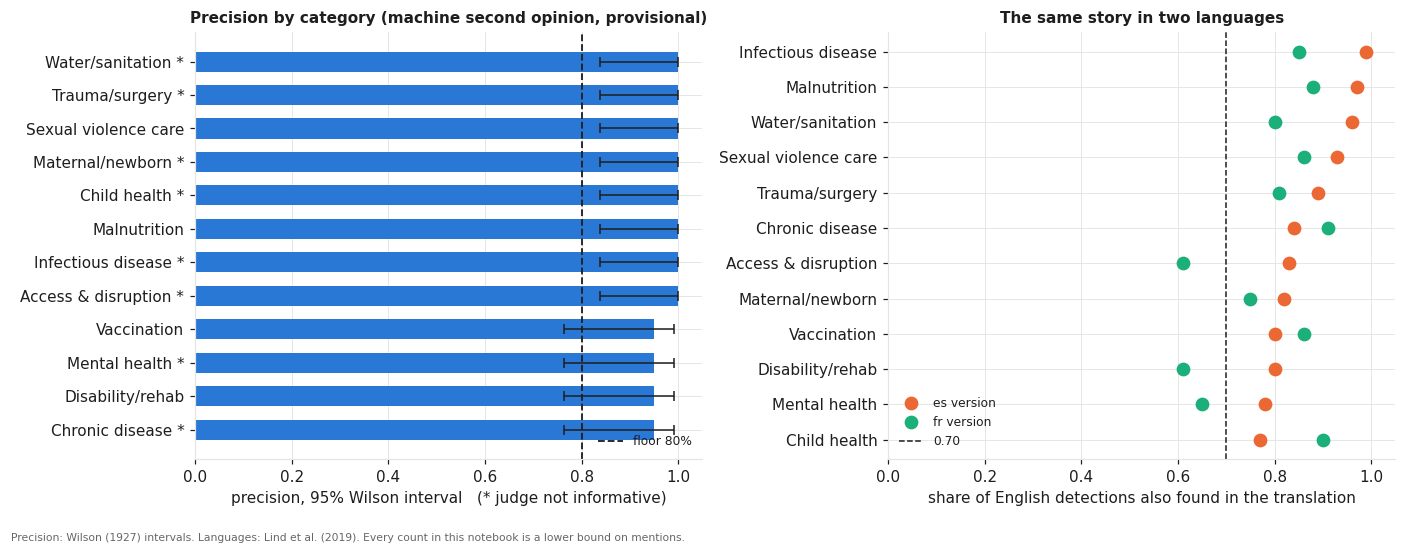


PRACTITIONER NOTE
  Sample matches by hand and report precision per category with a confidence interval; a pattern that
  fires is not a pattern that is right. Keep weak categories rather than dropping them, and state that
  precision is not recall: an unlisted term leaves no trace, so every count is a floor, not a ceiling.


In [ ]:
# @title
# ==================================================================================================
# PHASE: LEXICON                                                        stage 2 of 5 in this phase
# STAGE 7  PRECISION OF THE LEXICON
# WHAT THIS CELL DOES: checks the lexicon: a sample to judge, and the same story in two languages
# ==================================================================================================
# WHAT THIS CELL DOES
#   Draws a stratified sample of lexicon matches for human review, computes precision per category
#   once that review exists, and checks whether the lexicon finds the same categories in translated
#   versions of the same document.
#
# WHY
#   A pattern that matches text is not a pattern that is correct. Precision measures how many
#   flagged passages are genuine; it cannot measure recall, since an unlisted term leaves no trace
#   to sample. Every count this notebook reports is therefore a lower bound on mentions.
#
# HOW
#   Samples CFG.validation_sample_per_category passages per category, seeded for reproducibility,
#   and writes them for manual coding. Precision uses the human review when available, else a
#   provisional machine judgement, with Wilson (1927) intervals. The machine judge sees the whole
#   passage but not the matched term, and is tested on negative controls (passages the lexicon did
#   not match); it counts only where it rejects most controls (Pangakis et al. 2023).
#   Cross-language consistency follows the multilingual-dictionary validation of Lind et al. (2019).
#
# REFERENCES
#   Wilson, E.B. (1927) Probable inference, the law of succession, and statistical inference.
#     Journal of the American Statistical Association 22(158):209-212.
#   Lind, F., Eberl, J.-M., Heidenreich, T. and Boomgaarden, H.G. (2019) When the journey is as
#     important as the goal: a roadmap to multilingual dictionary construction. International
#     Journal of Communication 13:4000-4020.
#   Pangakis, N., Wolken, S. and Fasching, N. (2023) Automated annotation with generative AI
#     requires validation. arXiv:2306.00176.

import os, re
import numpy as np, pandas as pd

heading("STAGE 7  PRECISION OF THE LEXICON")
print(f"  sample size per category : {CFG.validation_sample_per_category}")
print(f"  precision floor          : {CFG.precision_floor:.0%} (below this, flagged, not dropped)")
print(f"  sampling                 : stratified by category, seed {CFG.seed}")
print()

set_all_seeds()
validation_rows = []
CATEGORIES_WITHOUT_MATCHES = []

for category in CATEGORIES:
    matched = passages[passages[f"cat::{category}"]]
    if len(matched) == 0:
        CATEGORIES_WITHOUT_MATCHES.append(category)
        continue
    take = matched.sample(min(CFG.validation_sample_per_category, len(matched)),
                          random_state=CFG.seed)
    for _, row in take.iterrows():
        evidence = category_match_detail(str(row[MATCH_COLUMN]), category)
        terms = "; ".join(sorted({matched_string for _, _, matched_string in evidence}))
        first = evidence[0][2] if evidence else ""
        position = str(row[MATCH_COLUMN]).lower().find(first.lower()) if first else 0
        excerpt = " ".join(str(row[MATCH_COLUMN])[max(0, position - 160):position + 220].split())
        validation_rows.append({
            "category": category,
            "short_label": SHORT_LABELS.get(category, category),
            "passage_id": row["passage_id"],
            "doc_id": row["doc_id"],
            "group": row.get("group", ""),
            "doc_language": row["doc_language"],
            "matched_terms": terms[:180],
            "pattern_language": evidence[0][0] if evidence else "",
            "passage_excerpt": excerpt,
            "is_correct": "",        # deliberately blank: a person fills this in
            "reviewer_note": "",
        })

VALIDATION_SAMPLE = pd.DataFrame(validation_rows)
VALIDATION_PATH = os.path.join(FIGURE_DIR, "s07_validation_sample_for_manual_review.csv")
VALIDATION_SAMPLE.to_csv(VALIDATION_PATH, index=False)
keep_on_drive(VALIDATION_PATH)   # the review takes longer than a runtime lives

print(f"  sample written           : {len(VALIDATION_SAMPLE)} rows")
print(f"    {VALIDATION_PATH}")
print(f"    Fill 'is_correct' with 1 or 0 per row, save it as")
print(f"    's07_validation_sample_REVIEWED.csv' in the same folder (here or on Drive), re-run.")
report("validation.sample_rows", len(VALIDATION_SAMPLE), "rows", "Stage 7")

if CATEGORIES_WITHOUT_MATCHES:
    print()
    print(f"  NOT MEASURABLE: {len(CATEGORIES_WITHOUT_MATCHES)} category(ies) have no match, so")
    print(f"  precision cannot be estimated for them:")
    for category in CATEGORIES_WITHOUT_MATCHES:
        print(f"    {SHORT_LABELS.get(category, category)}")

# ---- second opinion from the instruction model, with negative controls ----
# The model reads the WHOLE passage and the category name, not the matched term, so it cannot
# simply agree with the lexicon. It judges, with the same prompt, an equal number of passages the
# lexicon did NOT match (controls). A judge that says YES to the controls as often as to the matches
# cannot tell them apart, and its precision is not evidence. It is kept only as a pointer for the
# human review when it says YES to at most (1 - PRECISION_FLOOR) of the controls. Controls it says
# YES to may be misses of the lexicon: they are written out for the recall review (Stage 7b).
# Method: Pangakis, Wolken and Fasching (2023): an LLM annotator is validated against a check
# it can fail.
_article = "an" if str(CFG.document_type)[:1].lower() in "aeiou" else "a"
JUDGE_SYSTEM = (
    f"You read one passage from {_article} {CFG.document_type} and decide whether it reports on a "
    "given subject. Answer with one word, YES or NO, and nothing else. Answer YES when the passage "
    "reports on the subject anywhere, even in one sentence. Answer NO when it does not, including "
    "when a word only looks related or has another meaning.")


def _judge_prompt(category, text):
    body = " ".join(str(text).split())
    if len(body) > 2400:
        body = body[:2400].rsplit(" ", 1)[0] + " ..."
    return (f"SUBJECT: {category}\n\nPASSAGE:\n{body}\n\n"
            f"Does this passage report on the subject? Answer YES or NO.")


def _verdict(answer):
    words = re.sub(r"[^A-Z]", " ", str(answer).upper()).split()
    first = words[0] if words else ""
    return 1 if first == "YES" else 0 if first == "NO" else None


CONTROL_ROWS = []
for k, category in enumerate(CATEGORIES):
    pool = passages[~passages[f"cat::{category}"]]
    for _, row in pool.sample(min(CFG.validation_sample_per_category, len(pool)),
                              random_state=CFG.seed + k + 1).iterrows():
        CONTROL_ROWS.append({"category": category,
                             "short_label": SHORT_LABELS.get(category, category),
                             "passage_id": row["passage_id"], "doc_id": row["doc_id"],
                             "doc_language": row["doc_language"],
                             "passage_text": " ".join(str(row[MATCH_COLUMN]).split())})
JUDGE_CONTROLS = pd.DataFrame(CONTROL_ROWS)
_match_text = passages.set_index("passage_id")[MATCH_COLUMN].astype(str)
JUDGE_CHECK = None

if CFG.llm_enable and LLM.available and len(VALIDATION_SAMPLE):
    print()
    print("  MACHINE SECOND OPINION, labelled as such. Not a substitute for the human review.")
    print(f"  The model sees the whole passage and the category, not the matched term, and also")
    print(f"  judges {len(JUDGE_CONTROLS)} passages the lexicon did NOT match (negative controls).")

    def _run_judge():
        prompts = ([_judge_prompt(r.category, _match_text.get(r.passage_id, r.passage_excerpt))
                    for r in VALIDATION_SAMPLE.itertuples()]
                   + [_judge_prompt(r.category, r.passage_text)
                      for r in JUDGE_CONTROLS.itertuples()])
        replies = LLM.generate_batch(JUDGE_SYSTEM, prompts, max_new_tokens=4,
                                     batch_size=int(CFG.summary_batch))
        return [_verdict(reply) for reply in replies]

    _verdicts = cached("lexicon_judge", _run_judge,
                       inputs=[CORPUS_SIGNATURE, CFG.llm_model, JUDGE_SYSTEM,
                               _judge_prompt("x", "y"),
                               VALIDATION_SAMPLE[["category", "passage_id"]].values.tolist(),
                               JUDGE_CONTROLS[["category", "passage_id"]].values.tolist()],
                       note="YES/NO per sampled match and per negative control", scope="inputs")
    VALIDATION_SAMPLE["model_judgement"] = _verdicts[:len(VALIDATION_SAMPLE)]
    JUDGE_CONTROLS["model_judgement"] = _verdicts[len(VALIDATION_SAMPLE):]
    UNJUDGED = int(pd.isna(pd.Series(_verdicts, dtype="float")).sum())
    print(f"  unjudged answers (neither YES nor NO): {UNJUDGED} of {len(_verdicts)}, left out")
    report("validation.machine_unjudged", UNJUDGED, "rows", "Stage 7")

    _rows = []
    for category in CATEGORIES:
        on_matches = pd.to_numeric(VALIDATION_SAMPLE.loc[VALIDATION_SAMPLE["category"] == category,
                                                         "model_judgement"], errors="coerce")
        on_controls = pd.to_numeric(JUDGE_CONTROLS.loc[JUDGE_CONTROLS["category"] == category,
                                                       "model_judgement"], errors="coerce")
        if on_matches.notna().sum() and on_controls.notna().sum():
            yes_controls = float(on_controls.mean())
            _rows.append({"category": SHORT_LABELS.get(category, category),
                          "yes_on_matches": round(float(on_matches.mean()), 3),
                          "yes_on_controls": round(yes_controls, 3),
                          "informative": yes_controls <= 1 - float(CFG.precision_floor)})
    JUDGE_CHECK = pd.DataFrame(_rows)
    if len(JUDGE_CHECK):
        print()
        print("  CAN THE JUDGE TELL MATCHES FROM NON-MATCHES? (share answered YES)")
        print(JUDGE_CHECK.to_string(index=False))
        _blind = JUDGE_CHECK.loc[~JUDGE_CHECK["informative"], "category"].tolist()
        if _blind:
            print(f"  NOT INFORMATIVE for {len(_blind)} category(ies): the judge said YES to more "
                  f"than {1 - CFG.precision_floor:.0%} of passages the lexicon did not match, so "
                  f"its precision there is no evidence: {', '.join(_blind)}")
        report("validation.judge_informative_categories", int(JUDGE_CHECK["informative"].sum()),
               "categories", "Stage 7")
        JUDGE_CHECK.to_csv(os.path.join(FIGURE_DIR, "s07_judge_check.csv"), index=False)
    _possible_misses = JUDGE_CONTROLS[JUDGE_CONTROLS["model_judgement"] == 1]
    _path = os.path.join(FIGURE_DIR, "s07_judge_controls.csv")
    JUDGE_CONTROLS.to_csv(_path, index=False)
    print(f"  controls the judge called YES (possible lexicon misses, for the recall review): "
          f"{len(_possible_misses)}  -> {os.path.basename(_path)}")
    VALIDATION_SAMPLE.to_csv(VALIDATION_PATH, index=False)
    keep_on_drive(VALIDATION_PATH)
else:
    print()
    print("  Instruction model not available: no machine second opinion produced.")

# ---- precision, from the human review when it exists ----
# The reviewed file is looked for in this session and on Drive.
REVIEWED_PATH = os.path.join(FIGURE_DIR, "s07_validation_sample_REVIEWED.csv")
if not os.path.exists(REVIEWED_PATH) and globals().get("DURABLE_OUTPUT_DIR"):
    _on_drive = os.path.join(DURABLE_OUTPUT_DIR, os.path.relpath(REVIEWED_PATH, CFG.output_dir))
    REVIEWED_PATH = _on_drive if os.path.exists(_on_drive) else REVIEWED_PATH
PRECISION_TABLE = None
WEAK_CATEGORIES = set()
PRECISION_SOURCE = "not yet measured"

def _precision_from(frame, column, label):
    scored = frame[pd.to_numeric(frame[column], errors="coerce").notna()].copy()
    if not len(scored):
        return None
    scored["_correct"] = pd.to_numeric(scored[column], errors="coerce")
    rows = []
    for category, block in scored.groupby("category"):
        correct, total = int(block["_correct"].sum()), len(block)
        low, high = wilson_interval(correct, total)
        rows.append({"category": SHORT_LABELS.get(category, category),
                     "judged": total, "correct": correct,
                     "precision": round(correct / total, 3),
                     "ci_low": round(low / 100, 3), "ci_high": round(high / 100, 3),
                     "source": label})
    return pd.DataFrame(rows).sort_values("precision")

if os.path.exists(REVIEWED_PATH):
    reviewed = pd.read_csv(REVIEWED_PATH)
    PRECISION_TABLE = _precision_from(reviewed, "is_correct", "human review")
    PRECISION_SOURCE = "human review"
elif "model_judgement" in VALIDATION_SAMPLE.columns:
    PRECISION_TABLE = _precision_from(VALIDATION_SAMPLE, "model_judgement",
                                      "machine second opinion, PROVISIONAL")
    PRECISION_SOURCE = "machine second opinion, provisional"
    if PRECISION_TABLE is not None and JUDGE_CHECK is not None and len(JUDGE_CHECK):
        PRECISION_TABLE = PRECISION_TABLE.merge(
            JUDGE_CHECK[["category", "yes_on_controls", "informative"]], on="category", how="left")

print()
if PRECISION_TABLE is None or not len(PRECISION_TABLE):
    print("  PRECISION NOT YET MEASURED: no reviewed file and no machine judgement exist.")
else:
    print(f"  PRECISION, from: {PRECISION_SOURCE}")
    print(PRECISION_TABLE.to_string(index=False))
    PRECISION_TABLE.to_csv(os.path.join(FIGURE_DIR, "s07_precision_table.csv"), index=False)
    weak = PRECISION_TABLE[PRECISION_TABLE["precision"] < CFG.precision_floor]
    if "informative" in PRECISION_TABLE.columns:
        # A judge that cannot tell matches from non-matches says nothing about a category, good or
        # bad: such a category is "not assessed", not weak.
        _not_assessed = sorted(PRECISION_TABLE.loc[~PRECISION_TABLE["informative"].fillna(False)
                                                   .astype(bool), "category"])
        weak = weak[weak["informative"].fillna(False).astype(bool)]
        if _not_assessed:
            print()
            print(f"  NOT ASSESSED (the judge could not tell matches from non-matches): "
                  f"{', '.join(_not_assessed)}")
    WEAK_CATEGORIES = set(weak["category"])
    print()
    if len(weak):
        print(f"  BELOW FLOOR {CFG.precision_floor:.0%}: "
              f"{', '.join(sorted(WEAK_CATEGORIES))}")
        print("  Kept in every table, marked as weak, rather than dropped.")
    else:
        print(f"  every measurable category reaches the floor of {CFG.precision_floor:.0%}")
    if PRECISION_SOURCE.startswith("machine"):
        print()
        print("  PROVISIONAL: machine judgement, not a substitute for the human review. A row with")
        print("  informative = False is no evidence at all (see the control check above).")
    report("validation.categories_below_floor", len(weak), "categories", "Stage 7")

print()
# ---- cross-language consistency: same story, two languages ----
# Compares category detections between the English version of a story and its translations,
# following Lind et al. (2019). A low share means under-detection, not a rarer subject.
LANGUAGE_CONSISTENCY = None
_doc_cats = passages.groupby("doc_id")[CAT_COLS].max()
_doc_info = passages.groupby("doc_id")[["story_id", "doc_language", "is_main_version"]].first()
_main_en = _doc_info[_doc_info["is_main_version"]
                     & (_doc_info["doc_language"] == str(CFG.story_preferred_language))]
_others = _doc_info[~_doc_info["is_main_version"]
                    & (_doc_info["doc_language"] != str(CFG.story_preferred_language))]
_pairs = _others.reset_index().merge(_main_en.reset_index()[["doc_id", "story_id"]],
                                     on="story_id", suffixes=("", "_main"))
if len(_pairs) >= 20:
    rows = []
    for language, block in _pairs.groupby("doc_language"):
        for category, column in zip(CATEGORIES, CAT_COLS):
            main = _doc_cats.loc[block["doc_id_main"], column].values.astype(bool)
            other = _doc_cats.loc[block["doc_id"], column].values.astype(bool)
            if main.sum() >= 5:
                rows.append({"category": SHORT_LABELS.get(category, category),
                             "language": language, "english_found": int(main.sum()),
                             "also_found": int((main & other).sum()),
                             "share": round(float((main & other).sum() / main.sum()), 2)})
    LANGUAGE_CONSISTENCY = pd.DataFrame(rows)
    if len(LANGUAGE_CONSISTENCY):
        _table = LANGUAGE_CONSISTENCY.pivot(index="category", columns="language", values="share")
        print()
        print(f"  CROSS-LANGUAGE CONSISTENCY ({len(_pairs)} translation pairs, Lind et al. 2019)")
        print(_table.to_string(float_format=lambda v: f"{v:.2f}"))
        _low = LANGUAGE_CONSISTENCY.loc[LANGUAGE_CONSISTENCY["share"] < 0.70]
        if len(_low):
            print("  below 0.70: " + ", ".join(f"{r.category} ({r.language} {r.share:.2f})"
                                                for r in _low.itertuples()))
        report("validation.language_consistency_min", float(LANGUAGE_CONSISTENCY["share"].min()),
               "share", "Stage 7")
        LANGUAGE_CONSISTENCY.to_csv(os.path.join(FIGURE_DIR, "s07_language_consistency.csv"),
                                    index=False)

print()
print("  WHAT THIS STAGE DOES NOT MEASURE: recall. A term absent from the lexicon leaves nothing")
print("  to sample, so every count in this notebook is a lower bound on mentions.")
_pattern_counts = {SHORT_LABELS.get(c, c): sum(len(p) for p in CODEBOOK[c].values())
                   for c in CATEGORIES}
_thin = {name: count for name, count in sorted(_pattern_counts.items(), key=lambda kv: kv[1])[:3]}
print("  fewest-pattern categories, highest recall risk: "
      + ", ".join(f"{name} ({count})" for name, count in _thin.items()))
rule()

# ---- figure: precision by category, and cross-language consistency ----
_panels = [name for name, ok in (
    ("precision", PRECISION_TABLE is not None and len(PRECISION_TABLE)),
    ("languages", LANGUAGE_CONSISTENCY is not None and len(LANGUAGE_CONSISTENCY)),
) if ok]
if _panels:
    fig, axes = plt.subplots(1, len(_panels), figsize=(6.4 * len(_panels), 4.8), squeeze=False)
    for ax, panel in zip(axes[0], _panels):
        if panel == "precision":
            table = PRECISION_TABLE.reset_index(drop=True)
            positions = np.arange(len(table))
            ax.barh(positions, table["precision"], height=0.6,
                    color=[PALETTE[0] if v >= CFG.precision_floor else OTHER
                           for v in table["precision"]])
            ax.errorbar(table["precision"], positions,
                        xerr=[table["precision"] - table["ci_low"],
                              table["ci_high"] - table["precision"]],
                        fmt="none", ecolor=INK, elinewidth=1, capsize=3)
            ax.axvline(CFG.precision_floor, color=INK, ls="--", lw=1.2,
                       label=f"floor {CFG.precision_floor:.0%}")
            ax.set_yticks(positions)
            _labels = table["category"].astype(str)
            if "informative" in table.columns:
                _labels = [f"{name} *" if not bool(ok) else name
                           for name, ok in zip(_labels, table["informative"].fillna(False))]
            ax.set_yticklabels(_labels)
            ax.set_xlim(0, 1.05)
            ax.set_xlabel("precision, 95% Wilson interval"
                          + ("   (* judge not informative)" if "informative" in table.columns
                             else ""))
            ax.set_title(f"Precision by category ({PRECISION_SOURCE})", fontsize=10)
            ax.legend(fontsize=8, frameon=False, loc="lower right")
        else:
            table = LANGUAGE_CONSISTENCY.pivot(index="category", columns="language",
                                               values="share").sort_values(
                LANGUAGE_CONSISTENCY["language"].iloc[0])
            positions = np.arange(len(table))
            for k, language in enumerate(table.columns):
                ax.plot(table[language], positions, "o", ms=8, color=PALETTE[k + 1],
                        label=f"{language} version")
            ax.axvline(0.7, color=INK, ls="--", lw=1.0, label="0.70")
            ax.set_yticks(positions)
            ax.set_yticklabels(table.index)
            ax.set_xlim(0, 1.05)
            ax.set_xlabel("share of English detections also found in the translation")
            ax.set_title("The same story in two languages", fontsize=10)
            ax.legend(fontsize=8, frameon=False, loc="lower left")
    fig.tight_layout()
    add_reference_footer(fig, "Precision: Wilson (1927) intervals. Languages: Lind et al. (2019). "
                              "Every count in this notebook is a lower bound on mentions.")
    save_figure(fig, "s07_lexicon_checks"); plt.show()

practitioner_note("Validating a lexicon", """
Sample matches by hand and report precision per category with a confidence interval; a pattern that
fires is not a pattern that is right. Keep weak categories rather than dropping them, and state that
precision is not recall: an unlisted term leaves no trace, so every count is a floor, not a ceiling.
""")

## Stage 7b: recall of the lexicon   [phase: lexicon]

**What.** Reads the passages that match no category and lists the words most distinctive of them,
ranked by weighted log-odds (Monroe, Colaresi and Quinn 2008). Words already in the lexicon, proper
nouns and function words are excluded.

**How to use it.** Each candidate is kept, added to a category, or rejected by the analyst. The list is
a check on coverage, not a recall estimate.

  STAGE 7b  RECALL OF THE LEXICON
  passages matched by the lexicon   : 4,046 (66.4%)
  passages matched by nothing        : 2,043 (33.6%)
  patterns in the lexicon            : 497 across 12 categories
  [recall_probe_proper_nouns] not cached for key 84ab211ea98b; computing ...
  [recall_probe_proper_nouns] computed and saved | key 84ab211ea98b | 0.0 MB | copied to durable storage
  distinct words inside the lexicon patterns : 754
  proper nouns excluded                      : 909
  [recall_probe] not cached for key 68a33bab9758; computing ...
  [recall_probe] computed and saved | key 68a33bab9758 | 0.2 MB | copied to durable storage
  candidate terms, most distinctive first (lift = relative concentration):
    term                   unmatched   matched    lift      docs
    peace                         77        32     4.9        35
    international                388       468     1.7       188
    middle                        59        16     7.4        35
    house             

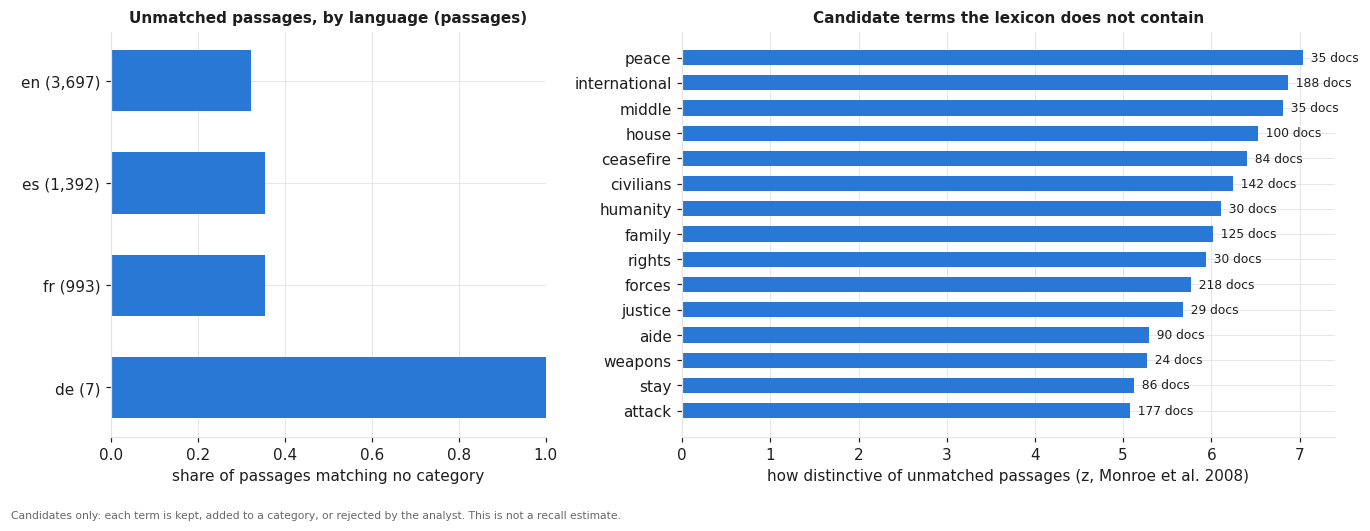


PRACTITIONER NOTE
  Precision is measurable because you can sample and check your matches; recall is not, because you
  cannot sample what a word list never saw. Reading the unmatched passages for distinctive vocabulary
  turns that gap into a list of candidate terms; the accepted count is evidence coverage was tested.


In [ ]:
# @title
# ==================================================================================================
# PHASE: LEXICON                                                        stage 3 of 5 in this phase
# STAGE 7b  RECALL OF THE LEXICON
# WHAT THIS CELL DOES: lists words in unmatched passages that the lexicon may be missing
# ==================================================================================================
# WHAT THIS CELL DOES
#   Reads the passages that no lexicon pattern matched and finds the vocabulary that sets them
#   apart from the matched passages, producing a list of candidate codebook terms.
#
# WHY
#   Recall cannot be measured directly: a term absent from the codebook leaves no missed passages
#   to sample. Clustering cannot fill the gap either, since it only groups passages already
#   matched. Reading the unmatched passages converts an unmeasurable quantity into an actionable
#   list of candidate additions.
#
# HOW
#   Weighted log-odds with an informative Dirichlet prior (Monroe et al. 2008), applied with the
#   unmatched passages as the target group and the matched passages as the reference corpus. The
#   variance term keeps the list to terms with real support, not typographical accidents.
#
# REFERENCES
#   Monroe, B.L., Colaresi, M.P. and Quinn, K.M. (2008) Fightin' words: lexical feature selection
#     and evaluation for identifying the content of political conflict. Political Analysis
#     16(4):372-403. DOI 10.1093/pan/mpn018

import os, re, math, unicodedata
import numpy as np, pandas as pd

heading("STAGE 7b  RECALL OF THE LEXICON")

MATCHED = passages["in_scope"].astype(bool)
UNMATCHED = ~MATCHED
print(f"  passages matched by the lexicon   : {int(MATCHED.sum()):,} "
      f"({MATCHED.mean():.1%})")
print(f"  passages matched by nothing        : {int(UNMATCHED.sum()):,} "
      f"({UNMATCHED.mean():.1%})")
print(f"  patterns in the lexicon            : {N_PATTERNS:,} across {len(CATEGORIES)} categories")

if int(UNMATCHED.sum()) < 30:
    print(f"  fewer than 30 unmatched passages: too few to characterise. No probe reported.")
    RECALL_CANDIDATES = pd.DataFrame()
else:
    # ---- tokenising, with the same filters the naming stage uses -------------
    LATIN = "a-zÀ-ɏ"
    TOKEN = re.compile(f"[{LATIN}][{LATIN}\\-']{{2,}}")
    URL_OR_EMAIL = re.compile(r"(?:https?://|www\.)\S+|\S+@\S+\.\S+", re.IGNORECASE)

    def fold(text):
        return "".join(character for character
                       in unicodedata.normalize("NFKD", str(text).lower())
                       if not unicodedata.combining(character))

    STOPWORDS = set("""
the a an and or but if then than that this these those there here of to in on at by for with from
as is are was were be been being have has had do does did will would can could should may might must
shall not no nor so such very more most much many few less least own same other another its it he she
they them their his her our your my we you i us who whom whose which what when where while about
against between into through during before after above below up down out off over under again
further once all any both each some too only now also per one two three four five
que los las del una unos unas por con para como pero mas muy este esta estos estas ese esa eso ser
son era eran fue fueron sido siendo tiene tienen tenia haber hay hubo desde hasta sobre entre sin
tras donde cuando porque aunque tambien solo otro otra otros otras cada todo toda todos todas
les des aux dans sur avec pour plus tres cette ces cet leur leurs nous vous ils elles etre est sont
etait etaient ete avoir ont avait avaient fait faire dont ainsi apres avant chez comme lorsque meme
aussi encore alors depuis pendant sous autre autres deja plusieurs numero
der die das den dem eines einer eine einen und oder aber wenn dann als dass dies diese diesem ist
sind war waren sein seine ihre ihrer nicht auch noch schon mehr sehr durch bei aus nach vor
said says say according report reports reported including include included among within across
people person also however therefore furthermore moreover thus hence due
qui une pas son ses mais donc car lui eux notre votre nos vos quel quelle ceci cela celui celle ceux
celles ici suis sommes etes sera seront serait aurait aura fait font tout toute toutes vers contre
selon jamais toujours moins peu beaucoup chaque certains certaines quelque quelques parmi afin lors
puis enfin notamment egalement aupres
sus esto nada algo algunos algunas mismo misma tanto muchos muchas poco ante mientras ellos ellas
nosotros usted ustedes estar puede pueden segun hacia
january february march april may june july august september october november december
janvier fevrier mars avril mai juin juillet aout septembre octobre novembre decembre
enero febrero marzo abril mayo junio julio agosto septiembre octubre noviembre diciembre
""".split())
    FOLDED_STOPWORDS = {fold(word) for word in STOPWORDS}
    _mask = re.compile(re.escape(str(CFG.place_placeholder)).lower())

    # Proper nouns are found by capitalisation rather than a name list, since a list would be
    # corpus-specific. A token capitalised in almost every occurrence is treated as a name.
    def proper_nouns(minimum_count=8, capitalised_share=0.85):
        column = "text_raw" if "text_raw" in passages.columns else "text"
        word = re.compile(f"[A-Za-zÀ-ɏ][A-Za-zÀ-ɏ\\-']{{2,}}")
        boundary = re.compile(r"(?:^|[.!?]\s+|\n)\s*$")
        upper, lower = {}, {}
        for text in passages[column].astype(str):
            text = URL_OR_EMAIL.sub(" ", text)
            for match in word.finditer(text):
                token, key = match.group(0), match.group(0).lower()
                if fold(key) in FOLDED_STOPWORDS:
                    continue
                if token[0].isupper():
                    if boundary.search(text[max(0, match.start() - 3):match.start()]):
                        continue
                    upper[key] = upper.get(key, 0) + 1
                else:
                    lower[key] = lower.get(key, 0) + 1
        return {key for key, count in upper.items()
                if count + lower.get(key, 0) >= minimum_count
                and count / (count + lower.get(key, 0)) >= capitalised_share}

    PROPER_NOUNS_PROBE = cached("recall_probe_proper_nouns", proper_nouns,
                                inputs=[fingerprint(passages["text_raw"].tolist()
                                                    if "text_raw" in passages.columns
                                                    else passages["text"].tolist()), 8, 0.85],
                                note="terms capitalised in almost every occurrence")

    # Terms already in the lexicon are excluded from the candidates. Patterns are regular
    # expressions, so literal words are extracted from them rather than matched as whole patterns.
    _in_lexicon = set()
    for category, languages in CODEBOOK.items():
        for language, patterns in languages.items():
            for pattern in patterns:
                for word in re.findall(r"[A-Za-zÀ-ɏ]{3,}", str(pattern)):
                    _in_lexicon.add(fold(word.lower()))
    print(f"  distinct words inside the lexicon patterns : {len(_in_lexicon):,}")
    print(f"  proper nouns excluded                      : {len(PROPER_NOUNS_PROBE):,}")

    def token_counts(texts):
        counter = {}
        for text in texts:
            for token in TOKEN.findall(URL_OR_EMAIL.sub(" ", str(text)).lower()):
                if (fold(token) in FOLDED_STOPWORDS or _mask.fullmatch(token)
                        or token in PROPER_NOUNS_PROBE or fold(token) in _in_lexicon):
                    continue
                counter[token] = counter.get(token, 0) + 1
        return counter

    def probe():
        inside = token_counts(passages.loc[UNMATCHED, "text"])
        outside = token_counts(passages.loc[MATCHED, "text"])
        inside_total, outside_total = sum(inside.values()), sum(outside.values())
        if not inside_total:
            return pd.DataFrame()
        combined = {token: inside.get(token, 0) + outside.get(token, 0)
                    for token in set(inside) | set(outside)}
        combined_total = inside_total + outside_total
        alpha_0 = float(len(combined))
        rows = []
        for token, count in inside.items():
            if count < 8:                      # minimum count for a candidate term
                continue
            other = outside.get(token, 0)
            prior = alpha_0 * combined.get(token, 0) / max(1, combined_total)
            a_in, a_out = count + prior, other + prior
            b_in = inside_total + alpha_0 - a_in
            b_out = outside_total + alpha_0 - a_out
            if min(a_in, a_out, b_in, b_out) <= 0:
                continue
            delta = math.log(a_in / b_in) - math.log(a_out / b_out)
            variance = 1.0 / a_in + 1.0 / a_out
            rate_in = count / inside_total
            rate_out = (other / outside_total) if outside_total else 1e-12
            rows.append({"term": token, "z": delta / math.sqrt(variance),
                         "count_unmatched": count, "count_matched": other,
                         "lift": rate_in / max(rate_out, 1e-12)})
        table = pd.DataFrame(rows).sort_values("z", ascending=False)
        return table

    RECALL_CANDIDATES = cached("recall_probe", probe,
                               inputs=[fingerprint(passages["text"].tolist()),
                                       fingerprint(sorted(_in_lexicon)),
                                       fingerprint(sorted(PROPER_NOUNS_PROBE)), 8],
                               note="candidate codebook terms from the unmatched passages")

    if not len(RECALL_CANDIDATES):
        print(f"  no candidate term met the frequency and distinctiveness threshold.")
    else:
        # document count per candidate, so a term from one report is not mistaken for a gap
        _docs = {}
        for term in RECALL_CANDIDATES["term"].head(60):
            hit = passages.loc[UNMATCHED & passages["text"].str.contains(
                re.escape(term), case=False, regex=True, na=False), "doc_id"]
            _docs[term] = int(hit.nunique())
        RECALL_CANDIDATES["documents"] = RECALL_CANDIDATES["term"].map(_docs)

        _path = os.path.join(FIGURE_DIR, "s07b_recall_probe_candidate_terms.csv")
        RECALL_CANDIDATES.to_csv(_path, index=False)

        print(f"  candidate terms, most distinctive first (lift = relative concentration):")
        print(f"    {'term':<20}  {'unmatched':>10}  {'matched':>8}  {'lift':>6}  {'docs':>8}")
        for _, row in RECALL_CANDIDATES.head(30).iterrows():
            documents = row.get("documents")
            print(f"    {str(row['term'])[:20]:<20}  {int(row['count_unmatched']):>10,}  "
                  f"{int(row['count_matched']):>8,}  {row['lift']:>6.1f}  "
                  f"{'' if pd.isna(documents) else f'{int(documents):>8,}'}")
        print(f"  {len(RECALL_CANDIDATES):,} candidate(s) written to {_path}")
        print(f"  add accepted terms to the codebook and re-run notebook 1 to see what remains.")

# ---- figure: where the lexicon finds nothing, and the words it may be missing ---------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
_by_language = (passages.assign(_unmatched=UNMATCHED).groupby("doc_language")["_unmatched"]
                .agg(["mean", "size"]).sort_values("size"))
axes[0].barh([f"{k} ({int(n):,})" for k, n in _by_language["size"].items()],
             _by_language["mean"], height=0.6, color=PALETTE[0])
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("share of passages matching no category")
axes[0].set_title("Unmatched passages, by language (passages)", fontsize=10)
if len(RECALL_CANDIDATES):
    _top = RECALL_CANDIDATES.head(15).iloc[::-1]
    axes[1].barh(_top["term"].astype(str), _top["z"], height=0.6, color=PALETTE[0])
    for k, row in enumerate(_top.itertuples()):
        if pd.notna(getattr(row, "documents", np.nan)):
            axes[1].text(row.z, k, f"  {int(row.documents)} docs", va="center", fontsize=8)
    axes[1].set_xlabel("how distinctive of unmatched passages (z, Monroe et al. 2008)")
    axes[1].set_title("Candidate terms the lexicon does not contain", fontsize=10)
else:
    axes[1].axis("off")
fig.tight_layout()
add_reference_footer(fig, "Candidates only: each term is kept, added to a category, or rejected by "
                          "the analyst. This is not a recall estimate.")
save_figure(fig, "s07b_recall_probe"); plt.show()

report("recall_probe.unmatched_passages", int(UNMATCHED.sum()), "passages", "Stage 7b")
report("recall_probe.unmatched_share", round(float(UNMATCHED.mean()), 4), "share", "Stage 7b")
report("recall_probe.candidate_terms", len(RECALL_CANDIDATES), "terms", "Stage 7b")
rule()

practitioner_note("Probing what your codebook missed", """
Precision is measurable because you can sample and check your matches; recall is not, because you
cannot sample what a word list never saw. Reading the unmatched passages for distinctive vocabulary
turns that gap into a list of candidate terms; the accepted count is evidence coverage was tested.
""")

## Stage 7c: corrected counts from a human sample   [phase: lexicon]

**Why.** Stage 7 checks the lexicon's matches, so it measures precision. A subject the lexicon
misses leaves no match to check, so recall stays unknown. This stage measures both.

**How.**
1. The cell draws a **random sample of all passages**: `HUMAN_SAMPLE_PER_GROUP` per country (40 by
   default, 320 in total), always the same passages because the draw is seeded.
2. It writes `s07c_human_coding_form.csv`. For each passage and each category you write 1 (the
   passage reports on it) or 0. The form never shows the lexicon's answer. The rules are in
   `s07c_coding_guide.md`. It takes about 3 hours.
3. Save the file as `s07c_human_coding_CODED.csv` (or `.xlsx`) in the same folder and run the
   notebook again.

**What you then get.**
- The lexicon's **precision and recall** per category, with 95% intervals.
- The **corrected share** of passages that report each category, per country and overall:
  the lexicon's share over all passages, plus the misses and minus the false alarms found in the
  sample. It is unbiased whatever errors the lexicon makes, because the sample is random.
  This is the difference estimator of survey sampling (Sarndal et al. 1992), which is also the
  prediction-powered estimate (Angelopoulos et al. 2023) and the design-based supervised estimate
  (Egami et al. 2023) of a mean.
- A list of the country x category cells where the lexicon's own share lies outside the interval.

  STAGE 7c  CORRECTED COUNTS FROM A HUMAN SAMPLE
  population            : 3,912 passages of the analysis set, in 8 countries
  sample                : 40 per country, simple random within each, seed 42
  form written          : 320 passages x 12 categories
    run_outputs/figures/s07c_human_coding_form.csv
    run_outputs/figures/s07c_coding_guide.md  (the instructions and the categories)
    The form shows each passage and the category names, never the lexicon's answer.

  NOT YET CODED. Fill the form (320 passages; about 3 hours per 300), save
  it as 's07c_human_coding_CODED.csv' next to it, and run notebook 1 again. Until
  then every count in this notebook is the lexicon's alone, with unknown recall.
  figure saved: s07c_corrected_shares (PNG, SVG; local and Drive)


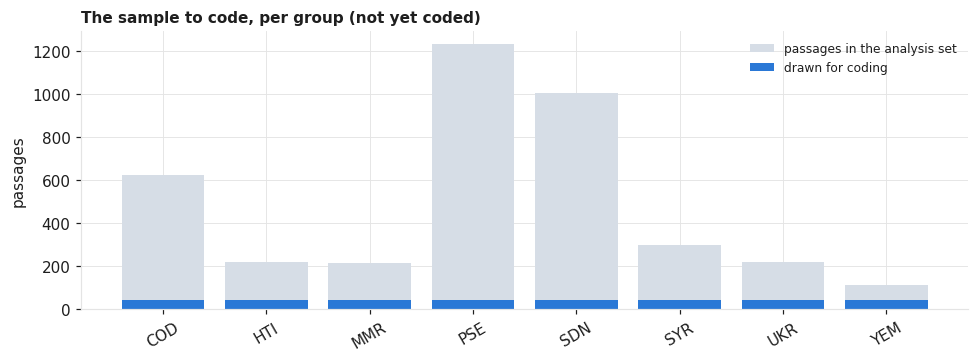


PRACTITIONER NOTE
  Code a small RANDOM sample of all passages by hand, without seeing the machine's answer, and use it
  to correct the machine's shares: the correction is unbiased by design, whatever the machine gets
  wrong, and it is the only way to measure recall. Report the corrected share with its interval.


In [ ]:
# @title
# ==================================================================================================
# PHASE: LEXICON                                                        stage 4 of 5 in this phase
# STAGE 7c  CORRECTED COUNTS FROM A HUMAN SAMPLE
# WHAT THIS CELL DOES: a random sample coded by a person corrects the lexicon's shares and measures
#                      its recall
# ==================================================================================================
# WHAT THIS CELL DOES
#   Draws a random sample of passages for a person to code by hand for every category. Once the
#   coded file exists, it corrects the lexicon's share of passages per group with it, with a 95%
#   interval, and measures the lexicon's precision AND recall.
#
# WHY
#   Stage 7 checks matches only, so it measures precision; a subject the lexicon misses leaves no
#   match to check. A random sample of ALL passages, coded without seeing the lexicon's answer,
#   shows both kinds of error. The corrected share is unbiased whatever errors the lexicon makes,
#   because the correction is measured on a sample drawn at random (a design-based guarantee).
#
# HOW
#   Population: the analysis set (one version per story, prose). Sample: HUMAN_SAMPLE_PER_GROUP
#   passages per group, simple random sampling within each group, seeded (stratified sampling).
#   The form shows the passage and the category names, never the lexicon's answer.
#   Corrected share in a group = the lexicon's share over ALL its passages + the share of misses
#   - the share of false alarms in its coded sample (the difference estimator of survey sampling,
#   which is also the prediction-powered and the design-based supervised estimate of a mean).
#   Interval: normal, with the finite-population correction. Each error rate counts one added error
#   in two added passages (in the spirit of Agresti and Coull 1998), so a small sample with no
#   observed error still has a width. Chosen by simulation (40 per group): coverage 96% or more at
#   every error rate tried, where the unadjusted interval covered as little as 32%.
#   The whole corpus: groups weighted by their size. Precision and recall: weighted by the
#   inverse sampling fraction, with stratified bootstrap intervals.
#
# REFERENCES
#   Angelopoulos, A.N., Bates, S., Fannjiang, C., Jordan, M.I. and Zrnic, T. (2023)
#     Prediction-powered inference. Science 382:669-674.
#   Egami, N., Hinck, M., Stewart, B.M. and Wei, H. (2023) Using imperfect surrogates for
#     downstream inference: design-based supervised learning for social science applications of
#     large language models. Advances in Neural Information Processing Systems 36 (NeurIPS 2023).
#   Sarndal, C.-E., Swensson, B. and Wretman, J. (1992) Model Assisted Survey Sampling. New York:
#     Springer.
#   Agresti, A. and Coull, B.A. (1998) Approximate is better than "exact" for interval estimation
#     of binomial proportions. The American Statistician 52(2):119-126.

import os
import numpy as np, pandas as pd

heading("STAGE 7c  CORRECTED COUNTS FROM A HUMAN SAMPLE")

HUMAN_SAMPLE_RESULT = None
_group_col = group_column(passages)
_population = (passages.loc[passages["in_analysis"].astype(bool)]
               if "in_analysis" in passages.columns else passages).copy()
_population["_pid"] = _population["passage_id"].astype(str)
_population["_group"] = (_population[_group_col].astype(str) if _group_col else "all")
_N = _population["_group"].value_counts().sort_index()
_PER_GROUP = int(CFG.human_sample_per_group)
_LABELS = [SHORT_LABELS.get(c, c) for c in CATEGORIES]
_CODE_COLUMNS = [f"code: {label}" for label in _LABELS]

print(f"  population            : {len(_population):,} passages of the analysis set, in "
      f"{len(_N)} {plural(CFG.group_noun, len(_N))}")
print(f"  sample                : {_PER_GROUP} per {CFG.group_noun}, simple random within each, "
      f"seed {CFG.seed}")

# ---- the sample: fixed by the seed, so every run draws the same passages -----------------------
_rng = np.random.default_rng(CFG.seed)
SAMPLE_IDS = []
for _g in _N.index:
    _ids = np.sort(_population.loc[_population["_group"] == _g, "_pid"].values)
    SAMPLE_IDS += list(_rng.choice(_ids, size=min(_PER_GROUP, len(_ids)), replace=False))
_sample = _population.set_index("_pid").loc[SAMPLE_IDS]
_sample = _sample.iloc[_rng.permutation(len(_sample))]         # mixed order, not group by group

FORM_PATH = os.path.join(FIGURE_DIR, "s07c_human_coding_form.csv")
GUIDE_PATH = os.path.join(FIGURE_DIR, "s07c_coding_guide.md")
if len(_sample):
    _form = pd.DataFrame({"passage_id": _sample.index, CFG.group_noun: _sample["_group"].values,
                          "language": _sample["doc_language"].astype(str).values})
    if "title" in _sample.columns:
        _form["title"] = _sample["title"].astype(str).str.slice(0, 160).values
    _form["passage"] = [" ".join(str(t).split()) for t in _sample[MATCH_COLUMN]]
    for column in _CODE_COLUMNS:
        _form[column] = ""
    _form["note"] = ""
    _form.to_csv(FORM_PATH, index=False, encoding="utf-8-sig")
    keep_on_drive(FORM_PATH)
    with open(GUIDE_PATH, "w", encoding="utf-8") as _fh:
        _fh.write("# How to code the sample\n\n"
                  "For each passage and each category, write 1 if the passage reports on the "
                  "subject anywhere, even in one sentence, and 0 if it does not. Leave nothing "
                  "blank: a row with a blank cell is not used. Judge the passage, not single "
                  "words. Save the file as `s07c_human_coding_CODED.csv` (or `.xlsx`) in the "
                  "same folder, here or on Drive, and run notebook 1 again.\n\n## Categories\n\n")
        for category, label in zip(CATEGORIES, _LABELS):
            _fh.write(f"- **{label}**: {category}\n")
    keep_on_drive(GUIDE_PATH)
    print(f"  form written          : {len(_form)} passages x {len(_CODE_COLUMNS)} categories")
    print(f"    {FORM_PATH}")
    print(f"    {GUIDE_PATH}  (the instructions and the categories)")
    print(f"    The form shows each passage and the category names, never the lexicon's answer.")
report("human_sample.drawn", len(_sample), "passages", "Stage 7c")


# ---- the coded file, when it exists, here or on Drive -----------------------------------------
def _find_coded():
    names = ("s07c_human_coding_CODED.csv", "s07c_human_coding_CODED.xlsx")
    for folder in (FIGURE_DIR,
                   os.path.join(globals().get("DURABLE_OUTPUT_DIR") or "",
                                os.path.relpath(FIGURE_DIR, CFG.output_dir))):
        for name in names:
            path = os.path.join(folder, name)
            if folder and os.path.exists(path):
                return path
    return None


def _as_code(value):
    text = str(value).strip().lower()
    return 1.0 if text in ("1", "1.0", "yes", "y", "true") else (
        0.0 if text in ("0", "0.0", "no", "n", "false") else np.nan)


def _estimate(frame, total, lexicon_share):
    """Corrected share for one group and category (difference estimator). `frame` holds the coded
    passages of the group with columns y (person) and f (lexicon)."""
    n = len(frame)
    misses = int(((frame["y"] == 1) & (frame["f"] == 0)).sum())
    alarms = int(((frame["y"] == 0) & (frame["f"] == 1)).sum())
    estimate = lexicon_share + (misses - alarms) / n
    pm, pf = (misses + 1) / (n + 2), (alarms + 1) / (n + 2)       # see HOW above
    variance = (pm * (1 - pm) + pf * (1 - pf) + 2 * pm * pf) / n * max(0.0, 1 - n / total)
    return estimate, variance, misses, alarms


CODED_PATH = _find_coded()
_shares, _accuracy = pd.DataFrame(), pd.DataFrame()
if CODED_PATH is None:
    print()
    print(f"  NOT YET CODED. Fill the form ({len(_sample)} passages; about 3 hours per 300), save")
    print("  it as 's07c_human_coding_CODED.csv' next to it, and run notebook 1 again. Until")
    print("  then every count in this notebook is the lexicon's alone, with unknown recall.")
else:
    _coded = (pd.read_excel(CODED_PATH) if CODED_PATH.endswith(".xlsx")
              else pd.read_csv(CODED_PATH, encoding="utf-8-sig"))
    _missing = [c for c in _CODE_COLUMNS if c not in _coded.columns]
    if _missing:
        raise RuntimeError(f"The coded file lacks the column(s) {_missing}; code the form this "
                           f"cell wrote, without renaming its columns.")
    _coded["passage_id"] = _coded["passage_id"].astype(str)
    for column in _CODE_COLUMNS:
        _coded[column] = _coded[column].map(_as_code)
    _complete = _coded[_coded[_CODE_COLUMNS].notna().all(axis=1)]
    _known = _complete[_complete["passage_id"].isin(_population["_pid"])]
    _unknown = len(_complete) - len(_known)
    _rows = _population.set_index("_pid").loc[_known["passage_id"]]
    print()
    print(f"  coded file            : {CODED_PATH}")
    print(f"  complete rows         : {len(_complete)} of {len(_coded)}"
          + (f"; {_unknown} not in the analysis set any more, left out" if _unknown else ""))

    _n = _rows["_group"].value_counts()
    _usable = [g for g in _N.index if _n.get(g, 0) >= 10]
    _thin = [g for g in _N.index if g not in _usable]
    if _thin:
        print(f"  fewer than 10 coded passages, not estimated: {', '.join(_thin)}")
    shares, accuracy = [], []
    for category, label, column in zip(CATEGORIES, _LABELS, _CODE_COLUMNS):
        frame = pd.DataFrame({"group": _rows["_group"].values,
                              "y": _known[column].values,
                              "f": _rows[f"cat::{category}"].astype(float).values})
        weighted_estimate, weighted_variance, weight_sum, lexicon_all = 0.0, 0.0, 0.0, 0.0
        for g in _usable:
            block = frame[frame["group"] == g]
            total = int(_N[g])
            lexicon = float(_population.loc[_population["_group"] == g,
                                            f"cat::{category}"].mean())
            estimate, variance, misses, alarms = _estimate(block, total, lexicon)
            half = 1.96 * np.sqrt(variance)
            low, high = wilson_interval(int(block["y"].sum()), len(block))
            shares.append({"group": g, "category": label, "N": total, "n": len(block),
                           "lexicon_share": lexicon, "human_share": float(block["y"].mean()),
                           "human_low": low / 100, "human_high": high / 100,
                           "corrected_share": float(np.clip(estimate, 0, 1)),
                           "ci_low": float(np.clip(estimate - half, 0, 1)),
                           "ci_high": float(np.clip(estimate + half, 0, 1)),
                           "misses": misses, "false_alarms": alarms})
            weight = total / len(_population)
            weighted_estimate += weight * estimate
            weighted_variance += weight ** 2 * variance
            weight_sum += weight
            lexicon_all += weight * lexicon
        if weight_sum:
            estimate = weighted_estimate / weight_sum
            half = 1.96 * np.sqrt(weighted_variance) / weight_sum
            shares.append({"group": "all", "category": label,
                           "N": int(_N[_usable].sum()), "n": int(_n[_usable].sum()),
                           "lexicon_share": lexicon_all / weight_sum,
                           "human_share": np.nan, "human_low": np.nan, "human_high": np.nan,
                           "corrected_share": float(np.clip(estimate, 0, 1)),
                           "ci_low": float(np.clip(estimate - half, 0, 1)),
                           "ci_high": float(np.clip(estimate + half, 0, 1)),
                           "misses": np.nan, "false_alarms": np.nan})

        # precision and recall, each coded passage weighted by N_g / n_g; stratified bootstrap
        usable = frame[frame["group"].isin(_usable)].reset_index(drop=True)
        weights = usable["group"].map(lambda g: _N[g] / _n[g]).values

        def _pr(idx):
            y, f, w = usable["y"].values[idx], usable["f"].values[idx], weights[idx]
            tp = float((w * y * f).sum())
            precision = tp / float((w * f).sum()) if (w * f).sum() else np.nan
            recall = tp / float((w * y).sum()) if (w * y).sum() else np.nan
            return precision, recall

        point = _pr(np.arange(len(usable)))
        boot_rng = np.random.default_rng(CFG.seed)
        strata = [np.flatnonzero(usable["group"].values == g) for g in _usable]
        draws = np.array([_pr(np.concatenate([boot_rng.choice(s, size=len(s)) for s in strata]))
                          for _ in range(1000)]) if len(usable) else np.empty((0, 2))
        bounds = (np.nanpercentile(draws, [2.5, 97.5], axis=0) if len(draws)
                  else np.full((2, 2), np.nan))
        f1 = (2 * point[0] * point[1] / (point[0] + point[1])
              if point[0] and point[1] and np.isfinite(point[0] + point[1]) else np.nan)
        accuracy.append({"category": label, "coded_yes": int(usable["y"].sum()),
                         "lexicon_yes": int(usable["f"].sum()),
                         "precision": point[0], "p_low": bounds[0][0], "p_high": bounds[1][0],
                         "recall": point[1], "r_low": bounds[0][1], "r_high": bounds[1][1],
                         "f1": f1})
    _shares, _accuracy = pd.DataFrame(shares), pd.DataFrame(accuracy)
    _shares["lexicon_outside_ci"] = ((_shares["lexicon_share"] < _shares["ci_low"])
                                     | (_shares["lexicon_share"] > _shares["ci_high"]))
    _shares.to_csv(os.path.join(FIGURE_DIR, "s07c_corrected_shares.csv"), index=False)
    _accuracy.to_csv(os.path.join(FIGURE_DIR, "s07c_lexicon_accuracy.csv"), index=False)

    print()
    print("  THE LEXICON AGAINST THE PERSON (weighted; 95% bootstrap intervals)")
    print(f"    {'category':<22} {'yes':>4}  {'precision':>17}  {'recall':>17}  {'F1':>5}")
    def _fmt(value, low, high):
        if not np.isfinite(value):
            return f"{'n/a':<17}"
        return f"{value:.2f} [{low:.2f}, {high:.2f}]"

    for row in _accuracy.itertuples():
        f1 = f"{row.f1:>5.2f}" if np.isfinite(row.f1) else "  n/a"
        print(f"    {row.category:<22} {row.coded_yes:>4}  "
              f"{_fmt(row.precision, row.p_low, row.p_high)}  "
              f"{_fmt(row.recall, row.r_low, row.r_high)}  {f1}")
    _all = _shares[_shares["group"] == "all"]
    if len(_all):
        print()
        print("  SHARE OF PASSAGES THAT REPORT EACH CATEGORY, WHOLE CORPUS")
        print(f"    {'category':<22} {'lexicon':>8}  {'corrected [95% interval]':>26}")
        for row in _all.itertuples():
            mark = "  lexicon outside the interval" if row.lexicon_outside_ci else ""
            print(f"    {row.category:<22} {row.lexicon_share:>8.1%}  {row.corrected_share:>8.1%} "
                  f"[{row.ci_low:.1%}, {row.ci_high:.1%}]{mark}")
    _off = _shares[(_shares["group"] != "all") & _shares["lexicon_outside_ci"]]
    print()
    print(f"  {CFG.group_noun} x category cells where the lexicon's share lies outside the "
          f"interval: {len(_off)} of {int((_shares['group'] != 'all').sum())}")
    for row in _off.head(12).itertuples():
        print(f"    {row.group:<12} {row.category:<22} lexicon {row.lexicon_share:.1%}, "
              f"corrected {row.corrected_share:.1%} [{row.ci_low:.1%}, {row.ci_high:.1%}]")
    print("  Stage 8 counts stories; this cell corrects shares of PASSAGES. Where a number must")
    print("  hold up, report the corrected share with its interval.")
    report("human_sample.coded_passages", int(_n[_usable].sum()) if _usable else 0, "passages",
           "Stage 7c")
    report("human_sample.mean_recall", round(float(_accuracy["recall"].mean()), 4), "share",
           "Stage 7c")
    report("human_sample.mean_precision", round(float(_accuracy["precision"].mean()), 4), "share",
           "Stage 7c")
    report("human_sample.cells_lexicon_outside_ci", int(len(_off)), "cells", "Stage 7c")

HUMAN_SAMPLE_RESULT = {"sample_ids": [str(v) for v in SAMPLE_IDS], "per_group": _PER_GROUP,
                       "coded_file": CODED_PATH, "shares": _shares, "accuracy": _accuracy}
rule()

# ---- figure: the corrected shares, or, before coding, what the sample covers ------------------
if len(_shares):
    _all = _shares[_shares["group"] == "all"].reset_index(drop=True)
    _cells = _shares[_shares["group"] != "all"]
    fig, axes = plt.subplots(1, 2, figsize=(15, max(4.2, 0.36 * len(_LABELS) + 1.4)),
                             gridspec_kw={"width_ratios": [1, 1.25]})
    ax = axes[0]
    y = np.arange(len(_all))
    ax.errorbar(_all["corrected_share"], y,
                xerr=[_all["corrected_share"] - _all["ci_low"],
                      _all["ci_high"] - _all["corrected_share"]],
                fmt="o", color=PALETTE[0], ms=7, capsize=3, label="corrected, 95% interval")
    ax.plot(_all["lexicon_share"], y, "D", color=OTHER, ms=6, label="lexicon alone")
    ax.set_yticks(y)
    ax.set_yticklabels(_all["category"])
    ax.invert_yaxis()
    ax.set_xlabel("share of passages that report the category")
    ax.set_title("Whole corpus: lexicon against the corrected share", fontsize=10, loc="left")
    ax.legend(fontsize=8, frameon=False, loc="lower right")
    ax = axes[1]
    _grid = _cells.pivot(index="category", columns="group",
                         values="corrected_share").reindex(_LABELS)
    _lex = _cells.pivot(index="category", columns="group", values="lexicon_share").reindex(_LABELS)
    _out = _cells.pivot(index="category", columns="group",
                        values="lexicon_outside_ci").reindex(_LABELS)
    _diff = (_grid - _lex) * 100
    _limit = max(5.0, float(np.nanmax(np.abs(_diff.values))) if _diff.size else 5.0)
    image = ax.imshow(_diff.values, cmap="RdBu", vmin=-_limit, vmax=_limit, aspect="auto")
    for i in range(_diff.shape[0]):
        for j in range(_diff.shape[1]):
            value = _diff.iat[i, j]
            if np.isfinite(value):
                ax.text(j, i, f"{value:+.0f}{'*' if bool(_out.iat[i, j]) else ''}",
                        ha="center", va="center", fontsize=7.5)
    ax.set_xticks(range(_diff.shape[1]))
    ax.set_xticklabels(_diff.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(_diff.shape[0]))
    ax.set_yticklabels(_diff.index, fontsize=8)
    ax.grid(False)
    fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02,
                 label="corrected minus lexicon, percentage points")
    ax.set_title(f"By {CFG.group_noun}: * = lexicon outside the 95% interval", fontsize=10,
                 loc="left")
    fig.tight_layout()
    add_reference_footer(fig, "Difference estimator (Sarndal et al. 1992); prediction-powered "
                              "inference (Angelopoulos et al. 2023); DSL (Egami et al. 2023).")
    save_figure(fig, "s07c_corrected_shares")
    plt.show()
elif len(_sample):
    fig, ax = plt.subplots(figsize=(9, 3.4))
    _drawn = _sample["_group"].value_counts().reindex(_N.index).fillna(0)
    ax.bar(_N.index.astype(str), _N.values, color="#d6dde6", label="passages in the analysis set")
    ax.bar(_N.index.astype(str), _drawn.values, color=PALETTE[0], label="drawn for coding")
    ax.set_ylabel("passages")
    ax.set_title("The sample to code, per group (not yet coded)", fontsize=10, loc="left")
    ax.legend(fontsize=8, frameon=False)
    ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    save_figure(fig, "s07c_corrected_shares")
    plt.show()

practitioner_note("Correcting automatic counts", """
Code a small RANDOM sample of all passages by hand, without seeing the machine's answer, and use it
to correct the machine's shares: the correction is unbiased by design, whatever the machine gets
wrong, and it is the only way to measure recall. Report the corrected share with its interval.
""")

  STAGE 8  COUNTRY BY CATEGORY TABLE
  documents by scope:
    single_group     1110
    multi_group       169
    regional           26
    global             57

  Country totals are not summed: a document in several groups
  is counted once per group.

  MAIN: per cent of single-group stories mentioning each category
  unit: stories, one version per release
short_label  Access & disruption  Child health  Chronic disease  Disability/rehab  Infectious disease  Malnutrition  Maternal/newborn  Mental health  Sexual violence care  Trauma/surgery  Vaccination  Water/sanitation
group                                                                                                                                                                                                                    
COD                         16.3          19.6              1.1               7.6                67.4          34.8              13.0           28.3                  50.0            25.0         17.4  

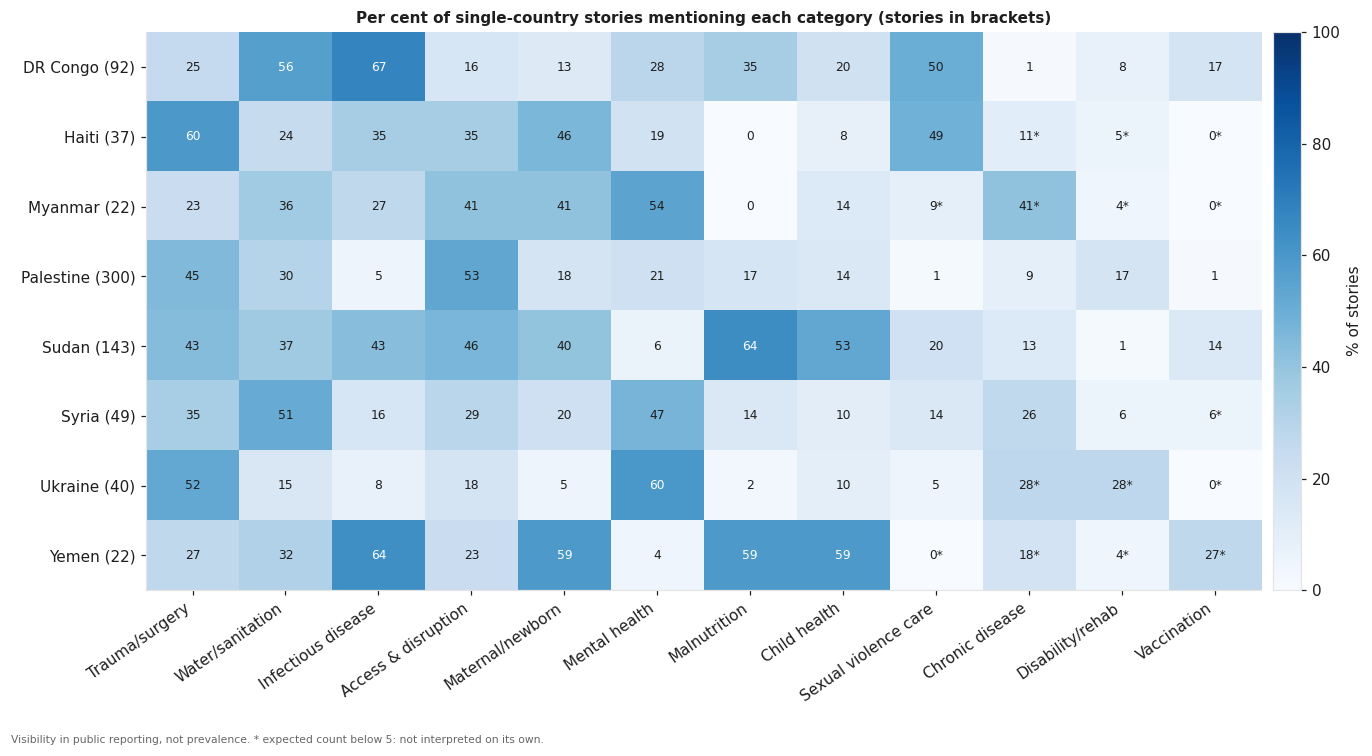


PRACTITIONER NOTE
  Fix the unit of analysis and report it beside every count; never mix two units in one table. Take
  the numerator and denominator from the same frame. Test sensitivity to that choice, such as counting
  every version of a story, and report the result even when nothing changes.


In [ ]:
# @title
# ==================================================================================================
# PHASE: LEXICON                                                        stage 5 of 5 in this phase
# STAGE 8  COUNTRY BY CATEGORY TABLE
# WHAT THIS CELL DOES: per cent of stories per country that mention each category
# ==================================================================================================
# WHAT THIS CELL DOES
#   Labels each document by group scope, then builds the group-by-category table: document and
#   passage shares mentioning each category per group, with Wilson intervals. Screens low-
#   expected-count cells and tests whether category rankings hold under two sensitivity checks.
#
# WHY
#   The unit of analysis is the document, not the passage: a document with many matching passages
#   counts the same as one with a single match. This measures how widely a subject appears in public
#   reporting, not how often it is mentioned; numerator and denominator share one frame.
#
# HOW
#   Documents are scored single_group, multi_group, regional or global from their group_all
#   field. The main table uses single-group documents, one version per story; sensitivity
#   tables add multi-group documents and every version of a story. Category rankings between
#   tables are compared with Spearman rank correlation.

import os
import numpy as np, pandas as pd
from scipy.stats import spearmanr

heading("STAGE 8  COUNTRY BY CATEGORY TABLE")

if not CAPABILITIES["group_comparison"]:
    print("  SKIPPED. No grouping column is set, so there is nothing to compare between groups.")
    print("  Set COLUMN_MAP['group'] in Stage 1 to enable this comparison.")
    GROUP_MAIN = GROUP_ALL = MAIN_MATRIX = ALL_MATRIX = GROUP_N = None
    SCOPE_SENSITIVITY = None
    rule()
else:
    # ---- scope: how many groups does each document belong to? ----
    def scope_label(all_groups):
        codes = [code.strip() for code in str(all_groups).split("|") if code.strip()]
        if "WLD" in codes:
            return "global"
        if len(codes) <= 1:
            return "single_group"
        return "multi_group" if len(codes) <= 3 else "regional"

    if CAPABILITIES["multi_group_scope"]:
        document_scope = (df_analysis.set_index("doc_id")["group_all"].map(scope_label))
        passages["scope"] = passages["doc_id"].map(document_scope).fillna("single_group")
        SCOPE_KNOWN = True
    else:
        passages["scope"] = "single_group"
        SCOPE_KNOWN = False
        print("  NOTE: this corpus has no multi-group data, so every document is treated as")
        print("  single-group; the sensitivity split below is not informative here.")

    scope_counts = passages.groupby("doc_id")["scope"].first().value_counts()
    print("  documents by scope:")
    for label in ("single_group", "multi_group", "regional", "global"):
        count = int(scope_counts.get(label, 0))
        if count or label == "single_group":
            print(f"    {label:<14} {count:>6}")
        report(f"scope.{label}", count, "documents", "Stage 8")
    print()
    print(f"  {CFG.group_noun.capitalize()} totals are not summed: a document in several groups")
    print("  is counted once per group.")

    # ---- the table ----
    def group_category_table(frame, label):
        """Document and passage shares per group, with Wilson intervals. Numerator and
        denominator for each share come from the same block."""
        rows = []
        for group, block in frame.groupby("group"):
            document_flags = block.groupby("doc_id")[CAT_COLS + BAR_COLS].max()
            n_documents, n_passages = len(document_flags), len(block)
            for category in CATEGORIES:
                hits = int(document_flags[f"cat::{category}"].sum())
                low, high = wilson_interval(hits, n_documents)
                rows.append({
                    "analysis": label, "group": group, "group_label": group_label(group),
                    "n_documents": n_documents, "n_passages": n_passages,
                    "category": category, "short_label": SHORT_LABELS.get(category, category),
                    "documents_mentioning": hits,
                    "document_pct": round(100 * hits / max(1, n_documents), 1),
                    "ci_low": round(low, 1), "ci_high": round(high, 1),
                    "passage_pct": round(100 * block[f"cat::{category}"].mean(), 1),
                    "precision_checked": category not in WEAK_CATEGORIES,
                })
        return pd.DataFrame(rows)

    # MAIN: one version per story (Stage 5a), single-group documents. A translation is the same
    # release, so counting it again would count one report two or three times.
    _main_version = passages["is_main_version"] if "is_main_version" in passages else True
    single = passages[(passages["scope"] == "single_group") & _main_version]
    GROUP_MAIN = group_category_table(single, "main, one version per story, single-group")
    GROUP_ALL  = group_category_table(passages[_main_version], "sensitivity, all scopes")
    GROUP_MAIN.to_csv(os.path.join(FIGURE_DIR, "s08_group_category_main.csv"), index=False)
    GROUP_ALL.to_csv(os.path.join(FIGURE_DIR, "s08_group_category_sensitivity.csv"), index=False)

    MAIN_MATRIX = GROUP_MAIN.pivot(index="group", columns="short_label", values="document_pct")
    ALL_MATRIX  = GROUP_ALL.pivot(index="group", columns="short_label", values="document_pct")
    GROUP_N = GROUP_MAIN.groupby("group")[["n_documents", "n_passages"]].first()

    print()
    print("  MAIN: per cent of single-group stories mentioning each category")
    print("  unit: stories, one version per release")
    print(MAIN_MATRIX.round(1).to_string())
    print()
    print("  documents and passages per row:")
    print(GROUP_N.to_string())
    for group in GROUP_N.index:
        report(f"group.{group}.documents", int(GROUP_N.loc[group, "n_documents"]),
               "documents", "Stage 8")

    # ---- small groups ----
    small = GROUP_N[GROUP_N["n_documents"] < CFG.small_group_n]
    if len(small):
        print()
        print(f"  SMALL GROUPS (fewer than {CFG.small_group_n} documents): report the interval,")
        print("  not the proportion alone:")
        for group in small.index:
            print(f"    {group_label(group)} [{group}]: "
                  f"{int(small.loc[group, 'n_documents'])} documents")
        report("group.small_groups", len(small), "groups", "Stage 8")

    # ---- expected-count screening ----
    observed = (GROUP_MAIN.pivot(index="group", columns="category",
                                 values="documents_mentioning").fillna(0))
    n_by_group = GROUP_N.loc[observed.index, "n_documents"].values[:, None].astype(float)
    total_documents = float(n_by_group.sum())
    category_share = (observed.sum(axis=0).values / max(1.0, total_documents))[None, :]
    expected = n_by_group * category_share
    thin_cells = int((expected < CFG.min_expected_cell).sum())
    print()
    print(f"  EXPECTED-COUNT SCREENING: below {CFG.min_expected_cell}: {thin_cells} of "
          f"{expected.size} cells")
    if thin_cells:
        print("  These cells are not interpreted individually in any later test.")
        thin = [(observed.index[i], observed.columns[j], round(float(expected[i, j]), 1))
                for i in range(expected.shape[0]) for j in range(expected.shape[1])
                if expected[i, j] < CFG.min_expected_cell]
        if len(thin) > 8:
            print(f"  first 8 of {len(thin)}, all listed in EXPECTED_COUNTS:")
        for group, category, value in thin[:8]:
            print(f"    {group_label(group):<14} {SHORT_LABELS.get(category, category):<22} "
                  f"expected {value}")
    report("group.thin_cells", thin_cells, "cells", "Stage 8")
    EXPECTED_COUNTS = pd.DataFrame(expected, index=observed.index, columns=observed.columns)
    THIN_CELL_MASK = EXPECTED_COUNTS < CFG.min_expected_cell

    # ---- does the ranking survive multi-group documents? ----
    rows = []
    for group in MAIN_MATRIX.index:
        if group not in ALL_MATRIX.index:
            continue
        main_row = MAIN_MATRIX.loc[group]
        all_row = ALL_MATRIX.loc[group].reindex(main_row.index)
        correlation, _ = spearmanr(main_row.values, all_row.values)
        rows.append({"group": group_label(group),
                     "n_single_group": int(GROUP_N.loc[group, "n_documents"]),
                     "rank_correlation": round(float(correlation), 3),
                     "top3_shared": len(set(main_row.nlargest(3).index)
                                        & set(all_row.nlargest(3).index)),
                     "largest_shift_pct": round(float((all_row - main_row).abs().max()), 1)})
    SCOPE_SENSITIVITY = pd.DataFrame(rows).sort_values("rank_correlation")
    SCOPE_SENSITIVITY.to_csv(os.path.join(FIGURE_DIR, "s08_scope_sensitivity.csv"), index=False)

    print()
    print("  SENSITIVITY: main against all documents")
    if not SCOPE_KNOWN:
        print("  Not informative: with no multi-group column, the two tables are identical.")
    print(SCOPE_SENSITIVITY.to_string(index=False))
    stable = int((SCOPE_SENSITIVITY["rank_correlation"] > 0.85).sum())
    print(f"\n  groups with essentially unchanged ranking: {stable} of {len(SCOPE_SENSITIVITY)}")

    # ---- counting every version instead of one per story ----
    print()
    print("  SENSITIVITY: every version counted, against one per story")
    every = group_category_table(passages[passages["scope"] == "single_group"], "every version")
    every_matrix = every.pivot(index="group", columns="short_label", values="document_pct")
    common_rows = MAIN_MATRIX.index.intersection(every_matrix.index)
    shift = (every_matrix.loc[common_rows] - MAIN_MATRIX.loc[common_rows]).abs()
    worst = shift.stack().idxmax()
    print(f"    documents, every version -> one per story : "
          f"{int(every.groupby('group')['n_documents'].first().sum()):,} -> "
          f"{int(GROUP_N['n_documents'].sum()):,}")
    print(f"    largest change to any cell : {float(shift.max().max()):.1f} percentage points "
          f"({group_label(worst[0])}, {worst[1]})")
    print(f"    mean change                : {float(shift.mean().mean()):.2f} percentage points")
    report("stories.largest_effect_pp", round(float(shift.max().max()), 2),
           "percentage points", "Stage 8")

    # ---- figure: the table itself, as a heatmap ----
    _matrix = MAIN_MATRIX.copy()
    _matrix = _matrix[_matrix.mean().sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(12.5, 0.55 * len(_matrix) + 2.2))
    image = ax.imshow(_matrix.values, cmap=SEQUENTIAL, vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(_matrix.shape[1]))
    ax.set_xticklabels(_matrix.columns, rotation=35, ha="right")
    ax.set_yticks(range(_matrix.shape[0]))
    ax.set_yticklabels([f"{group_label(g)} ({int(GROUP_N.loc[g, 'n_documents'])})"
                        for g in _matrix.index])
    _thin = THIN_CELL_MASK.rename(columns=SHORT_LABELS) if "THIN_CELL_MASK" in globals() else None
    for i, g in enumerate(_matrix.index):
        for j, c in enumerate(_matrix.columns):
            value = _matrix.iat[i, j]
            thin = bool(_thin.loc[g, c]) if _thin is not None and c in _thin.columns else False
            ax.text(j, i, f"{value:.0f}{'*' if thin else ''}", ha="center", va="center",
                    fontsize=8, color="white" if value > 55 else INK)
    ax.grid(False)
    fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01, label="% of stories")
    ax.set_title(f"Per cent of single-{CFG.group_noun} stories mentioning each category "
                 f"(stories in brackets)", fontsize=10)
    fig.tight_layout()
    add_reference_footer(fig, "Visibility in public reporting, not prevalence. * expected count "
                              "below 5: not interpreted on its own.")
    save_figure(fig, "s08_group_table"); plt.show()
    rule()

practitioner_note("Comparing groups", """
Fix the unit of analysis and report it beside every count; never mix two units in one table. Take
the numerator and denominator from the same frame. Test sensitivity to that choice, such as counting
every version of a story, and report the result even when nothing changes.
""")

## Stage 9: embed the passages   [phase: embedding]

**What.** Each passage becomes a vector of 4,096 numbers that places it by meaning, using
Qwen3-Embedding-8B (Zhang et al. 2025), one of the strongest open multilingual embedding models.

**Method.**
- The masked text is embedded, so place names cannot drive the vectors.
- Every passage gets the same task instruction, in English, as in the developers' own clustering
  evaluation: *Identify the topic or theme of the given passage from a humanitarian report*.
- Vectors are normalised; padding is on the left because the model pools its last token.

**Checks.** How many passages the length limit cut, the spread of similarities, and a translation
test: does a French or Spanish story land next to its English original (Libovicky, Rosa and Fraser
2020)?

**Language offsets.** A multilingual model still places each language slightly apart, and on the
real run one theme gathered French and Spanish passages. For each language, the cell measures the
average shift between a translation and its English original (same story), and removes it from
that language's passages (Yang, Yang, Cer and Darve 2021). With `LANGUAGE_CORRECTION = "auto"`,
it is kept only if translations then find their English original more often among ALL documents,
tested on stories not used to measure the shift. The printout shows the share before and after.

**Cost.** One GPU run, cached on Drive. The analysis set then goes on to dimension reduction.

  STAGE 9  EMBED THE PASSAGES
  passages to embed     : 6,089
  column read           : 'text' (masked)
  corpus fingerprint    : 398a55710067
  model                 : qwen3-8b
  maximum sequence      : 512 tokens
  batch size            : 16


  [embed_qwen3-8b] loaded from durable | written 2026-09-23 14:49 by run 54bd4f | key e967d94ba84a

  model in use          : qwen3-8b
  shape                 : 6,089 passages by 4,096 dimensions
  vector norm           : mean 1.0002, range 0.9995 to 1.0005
    normalised at encoding time; a norm far from 1.0 would mean something went wrong.

  passages likely truncated at 512 tokens: 0 (0.0%)
    None. Every passage fits inside the sequence limit.

  pairwise cosine on a 500-passage sample: mean 0.711, sd 0.100
    Near 1.0 would mean every passage collapsed to the same vector, near 0.0 no shared
    structure. Neither is expected.
  translation retrieval : 47% of 431 translations have their own English version as nearest English document
    

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

... (10 outputs left out)

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/381 [00:00<?, ?it/s]

  [embed_bge-m3] computed and saved | key d79b817fc51c | 24.9 MB | copied to durable storage
  second model          : bge-m3 (BAAI/bge-m3), 1,024 dimensions; language offsets applied
  figure saved: s09_embedding (PNG, SVG; local and Drive)


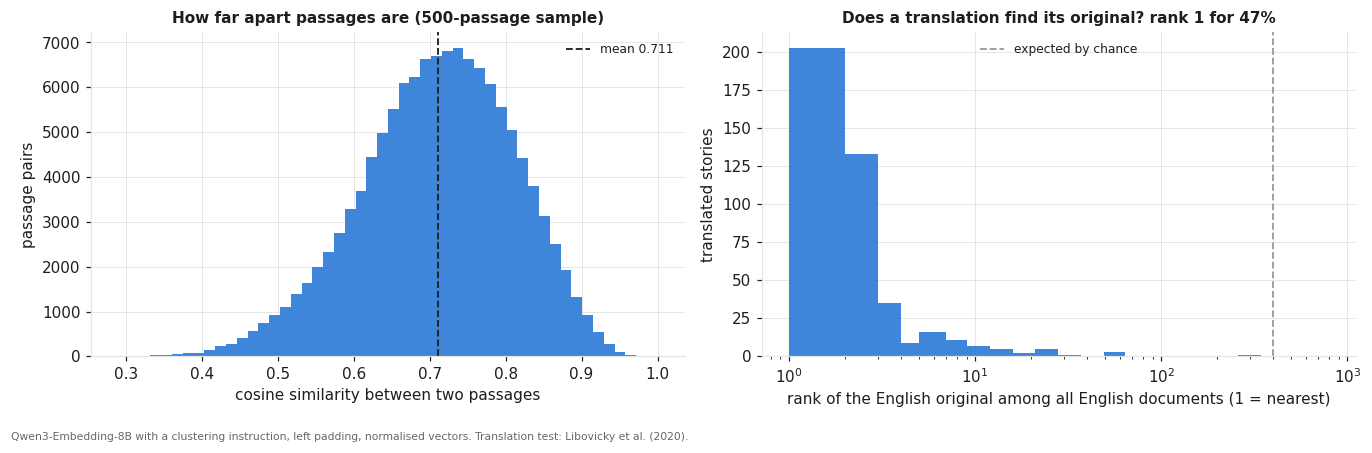


PRACTITIONER NOTE
  Read the model card before trusting the vectors: get the padding side or the instruction prefix
  wrong and the numbers look ordinary while meaning nothing. Cache by a fingerprint of the inputs,
  and report how much text the sequence limit cut.


In [ ]:
# @title
# ==================================================================================================
# PHASE: EMBEDDING                                                    the only stage in this phase
# STAGE 9  EMBED THE PASSAGES
# WHAT THIS CELL DOES: turns each passage into a 4,096-number vector (Qwen3-Embedding-8B, GPU,
#                      cached)
# ==================================================================================================
# WHAT THIS CELL DOES
#   Turns every passage (masked text) into a 4,096-number vector with Qwen3-Embedding-8B, then
#   tests whether a translation lands next to its original, and selects the analysis set.
#
# WHY
#   The vectors place passages by meaning; notebook 2 clusters them. This is the only GPU step, so
#   the vectors are cached against a fingerprint of their inputs and computed once.
#
# HOW
#   Each passage is prefixed with a clustering task instruction, in English and in the format the
#   developers used for their clustering evaluation: "Instruct: {task}\nQuery:{passage}".
#   The model pools the LAST token, so padding must be on the LEFT; the cell verifies it.
#   Translation test: for each translated story, the rank of its English version among all English
#   documents (parallel retrieval, a test of language neutrality).
#   Language offsets: each language's mean shift from English, estimated on translation pairs of
#   the same story, removed from its passages if, in a pool of ALL documents in all languages,
#   held-out translations then find their English original more often (LANGUAGE_CORRECTION;
#   after Libovicky et al. 2020 and Yang et al. 2021).
#   A second model of another family (SECOND_EMBEDDING_MODEL, BGE-M3 by default) embeds the same
#   passages for the robustness test of notebook 2 (Stage 16b).
#
# REFERENCES
#   Zhang, Y. et al. (2025) Qwen3 Embedding: advancing text embedding and reranking through
#     foundation models. arXiv:2506.05176.
#   Libovicky, J., Rosa, R. and Fraser, A. (2020) On the language neutrality of pre-trained
#     multilingual representations. Findings of EMNLP 2020.
#   Chen, J., Xiao, S., Zhang, P., Luo, K., Lian, D. and Liu, Z. (2024) BGE M3-Embedding:
#     multi-lingual, multi-functionality, multi-granularity text embeddings through self-knowledge
#     distillation. arXiv:2402.03216.
#   Yang, Z., Yang, Y., Cer, D. and Darve, E. (2021) A simple and effective method to eliminate the
#     self language bias in multilingual representations. EMNLP 2021:5825-5832.

import gc
import numpy as np, pandas as pd

heading("STAGE 9  EMBED THE PASSAGES")

EMBED_TEXTS = passages["text"].astype(str).tolist()          # the MASKED column
# The instruction, in the format of the model card and of the developers' clustering evaluation.
EMBED_PROMPT = (f"Instruct: {CFG.embedding_instruction.strip()}\nQuery:"
                if str(CFG.embedding_instruction).strip() else None)
EMBED_COLUMN = "text"
CORPUS_TEXT_FINGERPRINT = fingerprint(EMBED_TEXTS)

print(f"  passages to embed     : {len(EMBED_TEXTS):,}")
print(f"  column read           : '{EMBED_COLUMN}' (masked)")
print(f"  corpus fingerprint    : {CORPUS_TEXT_FINGERPRINT}")
print(f"  model                 : {', '.join(name for name, _ in CFG.embedding_models)}")
print(f"  maximum sequence      : {CFG.embedding_max_seq_len} tokens")
print(f"  batch size            : {CFG.embedding_batch_size}")
print()
if not GPU_AVAILABLE:
    print("  NO GPU IS AVAILABLE. If the vectors are not cached this cell will be slow. Change the")
    print("  runtime type to a GPU and run again; every other cell runs without one.")
print()


def embed_with(model_path, prompt=EMBED_PROMPT):
    def compute():
        set_all_seeds()
        from sentence_transformers import SentenceTransformer
        print(f"    loading {model_path} ...")
        # PADDING MUST BE ON THE LEFT for a model that pools its last token; the argument that sets
        # it was renamed between library versions, so both names are passed and the setting is then
        # READ BACK off the loaded tokenizer and asserted, below.
        pad_options = {"padding_side": "left"}
        options = {}
        if "qwen3-embedding" in model_path.lower():
            options = {"model_kwargs": {"torch_dtype": "float16"},
                       "tokenizer_kwargs": dict(pad_options),
                       "processor_kwargs": dict(pad_options)}
        try:
            model = SentenceTransformer(model_path,
                                        device="cuda" if GPU_AVAILABLE else None, **options)
        except TypeError:
            # An older library rejects processor_kwargs; a newer one may reject tokenizer_kwargs.
            options.pop("processor_kwargs", None)
            try:
                model = SentenceTransformer(model_path,
                                            device="cuda" if GPU_AVAILABLE else None, **options)
            except TypeError:
                options.pop("tokenizer_kwargs", None)
                model = SentenceTransformer(model_path,
                                            device="cuda" if GPU_AVAILABLE else None, **options)
                print("    neither argument name was accepted; the padding side is set directly")

        if "qwen3-embedding" in model_path.lower():
            tokenizer = getattr(model, "tokenizer", None)
            if tokenizer is None:
                first = model[0] if len(model) else None
                tokenizer = getattr(first, "tokenizer", None)
            if tokenizer is None:
                raise RuntimeError(
                    "Could not reach the tokenizer to verify the padding side; check how the "
                    "model was loaded.")
            if getattr(tokenizer, "padding_side", None) != "left":
                tokenizer.padding_side = "left"        # set it directly, then verify below
            assert tokenizer.padding_side == "left", (
                f"padding_side is {tokenizer.padding_side!r} after being set to 'left'; do not "
                f"continue with {model_path}, its pooled vector would be read off a padding token.")
            print(f"    padding side verified on the tokenizer: {tokenizer.padding_side}")
        model.max_seq_length = CFG.embedding_max_seq_len
        model.eval()
        vectors = model.encode(EMBED_TEXTS, batch_size=CFG.embedding_batch_size,
                               normalize_embeddings=True, show_progress_bar=True,
                               prompt=prompt)
        del model
        gc.collect()
        try:
            import torch
            torch.cuda.empty_cache()
        except Exception:
            pass
        return np.asarray(vectors, dtype=np.float32)
    return compute


embeddings = {}
for short_name, model_path in CFG.embedding_models:
    embeddings[short_name] = cached(
        f"embed_{short_name}",
        embed_with(model_path),
        inputs=[CORPUS_TEXT_FINGERPRINT, model_path, CFG.embedding_max_seq_len,
                CFG.embedding_batch_size, CFG.seed, EMBED_PROMPT],
        note=f"{len(EMBED_TEXTS)} passages from the '{EMBED_COLUMN}' column",
        # The vectors depend only on the passage text and the embedding settings, all classified
        # in Stage 1; a downstream threshold change does not discard a GPU-hour of cached work.
        scope="inputs")

if not embeddings:
    raise RuntimeError("No embedding model produced vectors. Check the runtime and the network.")

CHOSEN_MODEL = list(embeddings)[0]
X = embeddings[CHOSEN_MODEL]

# ---- checks that can actually fail -----------------------------------------
assert X.shape[0] == len(passages), (
    f"Embedding has {X.shape[0]} rows for {len(passages)} passages; the passage table changed "
    f"since caching. Raise CACHE_VERSION in Stage 1 to force a recomputation.")
assert np.isfinite(X).all(), "The embedding contains non-finite values; it cannot be used."

norms = np.linalg.norm(X, axis=1)
DEGENERATE = int((norms < 1e-6).sum())
assert DEGENERATE == 0, (f"{DEGENERATE} passage vector(s) are all zero. With left padding that "
                         f"normally means the passages were empty.")

print()
print(f"  model in use          : {CHOSEN_MODEL}")
print(f"  shape                 : {X.shape[0]:,} passages by {X.shape[1]:,} dimensions")
print(f"  vector norm           : mean {norms.mean():.4f}, "
      f"range {norms.min():.4f} to {norms.max():.4f}")
print("    normalised at encoding time; a norm far from 1.0 would mean something went wrong.")
report("embedding.passages", int(X.shape[0]), "passages", "Stage 9")
report("embedding.dimensions", int(X.shape[1]), "dimensions", "Stage 9")
report("embedding.norm_mean", round(float(norms.mean()), 4), "L2 norm", "Stage 9")

# ---- how much text was truncated -------------------------------------------
# A passage longer than the maximum sequence length is cut; the tail is not embedded.
approximate_tokens = (passages["word_count"] * 1.35      # a conservative words-to-tokens ratio
                      + (len(EMBED_PROMPT.split()) * 1.35 if EMBED_PROMPT else 0))
truncated = int((approximate_tokens > CFG.embedding_max_seq_len).sum())
print()
print(f"  passages likely truncated at {CFG.embedding_max_seq_len} tokens: {truncated} "
      f"({100 * truncated / max(1, len(passages)):.1f}%)")
if truncated:
    print("    Tails are not represented in the vector; raise EMBEDDING_MAX_SEQ_LEN in Stage 1 to")
    print("    include them, at a cost in memory and time.")
else:
    print("    None. Every passage fits inside the sequence limit.")
report("embedding.passages_truncated", truncated, "passages", "Stage 9")

# ---- a similarity spread, as a sanity check --------------------------------
rng = np.random.default_rng(CFG.seed)
sample = rng.choice(len(X), size=min(500, len(X)), replace=False)
block = X[sample]
similarities = (block @ block.T)[np.triu_indices(len(block), k=1)]
print()
print(f"  pairwise cosine on a {len(block)}-passage sample: "
      f"mean {similarities.mean():.3f}, sd {similarities.std():.3f}")
print("    Near 1.0 would mean every passage collapsed to the same vector, near 0.0 no shared")
print("    structure. Neither is expected.")
assert 0.02 < similarities.mean() < 0.97, (
    f"Mean pairwise similarity is {similarities.mean():.3f}, which is degenerate; the usual cause "
    f"with Qwen3-Embedding is right-side padding.")
report("embedding.mean_pairwise_cosine", round(float(similarities.mean()), 4),
       "cosine", "Stage 9")
rule()

# ---- does the embedding see a translation as the same text? ------------------------
# For each story, ranks its English version among all English documents by similarity to the
# other version: the parallel-retrieval test of language neutrality (Libovicky et al. 2020).
LANGUAGE_NEUTRALITY = None
_doc_of = passages["doc_id"].values
_doc_ids, _inverse = np.unique(_doc_of, return_inverse=True)
_doc_vec = np.zeros((len(_doc_ids), X.shape[1]), dtype=np.float32)
np.add.at(_doc_vec, _inverse, X)
_doc_vec /= np.maximum(np.linalg.norm(_doc_vec, axis=1, keepdims=True), 1e-12)
_info = passages.groupby("doc_id")[["story_id", "doc_language", "is_main_version"]].first()
_info = _info.loc[_doc_ids]
_en = np.flatnonzero((_info["doc_language"] == str(CFG.story_preferred_language)).values
                     & _info["is_main_version"].values)
_other = np.flatnonzero(~_info["is_main_version"].values
                        & (_info["doc_language"] != str(CFG.story_preferred_language)).values)
_story_to_en = {_info["story_id"].iat[k]: k for k in _en}
_ranks = []
for k in _other:
    target = _story_to_en.get(_info["story_id"].iat[k])
    if target is not None:
        scores = _doc_vec[_en] @ _doc_vec[k]
        _ranks.append(int((scores > float(_doc_vec[target] @ _doc_vec[k])).sum()) + 1)
if len(_ranks) >= 20:
    _ranks = np.array(_ranks)
    LANGUAGE_NEUTRALITY = {"pairs": int(len(_ranks)), "top1": float((_ranks == 1).mean()),
                           "median_rank": float(np.median(_ranks)), "candidates": int(len(_en))}
    print(f"  translation retrieval : {LANGUAGE_NEUTRALITY['top1']:.0%} of {len(_ranks)} "
          f"translations have their own English version as nearest English document")
    print(f"                          median rank {LANGUAGE_NEUTRALITY['median_rank']:.0f} of "
          f"{len(_en)}; chance would be 1 in {len(_en)}")
    report("embedding.translation_top1", round(LANGUAGE_NEUTRALITY["top1"], 4), "share", "Stage 9")

# ---- language offsets: remove the language, keep the content ------------------------
# The offset of a language is the mean difference between its version and the English version
# of the SAME story, so it holds the language and not the topic (plain centring by language,
# Libovicky et al. 2020, would also remove topics that one language reports more). The test is a
# MIXED pool: among all documents in all languages, is a translation's nearest document its own
# English original? A language offset pulls it towards other documents in its own language
# instead. Judged on stories the offsets were not estimated from (two-fold cross-fitting); in
# "auto" the offsets are kept only if that share rises.
LANGUAGE_OFFSETS, LANGUAGE_CORRECTION = estimate_language_offsets(
    X, passages, CFG.story_preferred_language, CFG.language_correction, CFG.seed)
if LANGUAGE_CORRECTION["top1_before"] is not None:
    print(f"  language offsets      : "
          f"{'APPLIED' if LANGUAGE_CORRECTION['applied'] else 'not applied'} "
          f"({CFG.language_correction}); languages {', '.join(sorted(LANGUAGE_OFFSETS)) or 'none'}")
    print(f"    held-out translations whose nearest document, in any language, is their English "
          f"original: {LANGUAGE_CORRECTION['top1_before']:.0%} -> "
          f"{LANGUAGE_CORRECTION['top1_after']:.0%}")
    report("embedding.language_offsets_applied", int(LANGUAGE_CORRECTION["applied"]), "0 or 1",
           "Stage 9")
    report("embedding.mixed_top1_before", round(LANGUAGE_CORRECTION["top1_before"], 4),
           "share", "Stage 9")
    report("embedding.mixed_top1_after", round(LANGUAGE_CORRECTION["top1_after"], 4),
           "share", "Stage 9")
else:
    print(f"  language offsets      : not estimated ({CFG.language_correction}; "
          f"{LANGUAGE_CORRECTION['pairs']} translation pairs)")

# ---- the analysis set: what the projection and the clustering see ------------------
X_ALL = X                      # the vectors as stored on disk; notebook 2 checks their hash
X_ADJUSTED = apply_language_offsets(X_ALL, passages["doc_language"].values, LANGUAGE_OFFSETS)
ANALYSIS_ROWS = np.flatnonzero(passages["in_analysis"].values)
X = X_ADJUSTED[ANALYSIS_ROWS]
# From here on every cache key names the analysis set and the offsets, so a change to either can
# never load a projection or a clustering made for another input.
EMBEDDING_FINGERPRINT = CORPUS_TEXT_FINGERPRINT
CORPUS_TEXT_FINGERPRINT = fingerprint([EMBEDDING_FINGERPRINT, ANALYSIS_ROWS.tolist(),
                                       {k: np.round(v, 6).tolist()
                                        for k, v in sorted(LANGUAGE_OFFSETS.items())}])

# How far the languages sit apart in the analysis set, before and after (silhouette of the
# language labels, cosine; near 0 = mixed by subject, as a multilingual embedding should be).
LANGUAGE_SEPARATION = {}
_langs = passages["doc_language"].values[ANALYSIS_ROWS].astype(str)
_common = pd.Series(_langs).value_counts()
_usable = np.isin(_langs, _common.index[_common >= 20])
if len(_common[_common >= 20]) >= 2:
    from sklearn.metrics import silhouette_score
    _rows = np.random.default_rng(CFG.seed).permutation(np.flatnonzero(_usable))[:2000]
    for _label, _vectors in (("before", X_ALL[ANALYSIS_ROWS]), ("after", X)):
        LANGUAGE_SEPARATION[_label] = float(silhouette_score(_vectors[_rows], _langs[_rows],
                                                             metric="cosine"))
    print(f"  language separation   : silhouette of language labels "
          f"{LANGUAGE_SEPARATION['before']:.3f} -> {LANGUAGE_SEPARATION['after']:.3f} "
          f"(0 = languages mixed)")
    report("embedding.language_separation", round(LANGUAGE_SEPARATION["after"], 4),
           "silhouette", "Stage 9")
print(f"  analysis set          : {len(ANALYSIS_ROWS):,} of {len(X_ALL):,} passages go on to "
      f"dimension reduction")
report("embedding.analysis_rows", int(len(ANALYSIS_ROWS)), "passages", "Stage 9")

# ---- a second, independent embedding model, for the robustness test in notebook 2 ----------
# The same passages, embedded by a model of another family (no instruction), with its own
# language offsets. Stage 16b clusters these vectors the same way: a sub-theme that does not come
# back depends on the first model rather than on the text. Its vectors travel in the bundle, in
# 16-bit, for the analysis set only.
SECOND_MODEL = None
if CFG.second_embedding_model:
    _name2, _path2 = CFG.second_embedding_model
    try:
        _X2 = cached(f"embed_{_name2}", embed_with(_path2, prompt=None),
                     inputs=[EMBEDDING_FINGERPRINT, _path2, CFG.embedding_max_seq_len,
                             CFG.embedding_batch_size, CFG.seed, None],
                     note=f"second model, {len(EMBED_TEXTS)} passages, no instruction",
                     scope="inputs")
    except Exception as exc:                          # reported, and notebook 2 says it is absent
        _X2 = None
        print(f"  second model          : {_path2} could not be computed "
              f"({type(exc).__name__}: {str(exc)[:80]}); Stage 16b will say so")
    if _X2 is not None:
        _X2 = np.asarray(_X2, dtype=np.float32)
        assert _X2.shape[0] == len(passages), (
            "The second model's vectors do not match the passages.")
        _offsets2, _record2 = estimate_language_offsets(
            _X2, passages, CFG.story_preferred_language, CFG.language_correction, CFG.seed)
        SECOND_MODEL = {
            "name": _name2, "path": _path2, "dimensions": int(_X2.shape[1]),
            "vectors": apply_language_offsets(_X2, passages["doc_language"].values,
                                              _offsets2)[ANALYSIS_ROWS].astype(np.float16),
            "language_correction": _record2}
        print(f"  second model          : {_name2} ({_path2}), {_X2.shape[1]:,} dimensions; "
              f"language offsets {'applied' if _record2['applied'] else 'not applied'}")

# ---- figure: the spread of the vectors, and whether translations find their original ------
_show_ranks = LANGUAGE_NEUTRALITY is not None
fig, axes = plt.subplots(1, 2 if _show_ranks else 1, figsize=(12.5 if _show_ranks else 7, 3.9),
                         squeeze=False)
ax = axes[0][0]
ax.hist(similarities, bins=50, color=PALETTE[0], alpha=0.9)
ax.axvline(similarities.mean(), color=INK, ls="--", lw=1.2,
           label=f"mean {similarities.mean():.3f}")
ax.set_xlabel("cosine similarity between two passages")
ax.set_ylabel("passage pairs")
ax.set_title(f"How far apart passages are ({len(block)}-passage sample)", fontsize=10)
ax.legend(fontsize=8, frameon=False)
if _show_ranks:
    ax = axes[0][1]
    _edges = np.unique(np.geomspace(1, max(2, LANGUAGE_NEUTRALITY["candidates"]), 25).astype(int))
    ax.hist(_ranks, bins=_edges, color=PALETTE[0], alpha=0.9)
    ax.set_xscale("log")
    ax.axvline(LANGUAGE_NEUTRALITY["candidates"] / 2, color=OTHER, ls="--", lw=1.2,
               label="expected by chance")
    ax.set_xlabel("rank of the English original among all English documents (1 = nearest)")
    ax.set_ylabel("translated stories")
    ax.set_title(f"Does a translation find its original? rank 1 for "
                 f"{LANGUAGE_NEUTRALITY['top1']:.0%}", fontsize=10)
    ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
add_reference_footer(fig, "Qwen3-Embedding-8B with a clustering instruction, left padding, "
                          "normalised vectors. Translation test: Libovicky et al. (2020).")
save_figure(fig, "s09_embedding"); plt.show()

practitioner_note("Embedding", """
Read the model card before trusting the vectors: get the padding side or the instruction prefix
wrong and the numbers look ordinary while meaning nothing. Cache by a fingerprint of the inputs,
and report how much text the sequence limit cut.
""")

## Stage 10: umap   [phase: dimension reduction]

**What.** Dimension reduction: from 4,096 dimensions to a few. Density-based clustering works poorly
in thousands of dimensions, so notebook 2 clusters in this reduced space.

**Method.** UMAP with cosine distance (McInnes, Healy and Melville 2018). The settings are chosen by
measurement: each candidate is scored by trustworthiness and continuity (Venna and Kaski 2001), which
ask whether neighbours stay neighbours. Near-ties go to the simpler setting.

**Why not parametric UMAP.** Parametric UMAP (Sainburg, McInnes and Gentner 2021) trains a neural
network to do the projection. Its gain is embedding *new* data later. This corpus is fixed, so that
gain does not apply, and the network would add training variance and a TensorFlow dependency.

  STAGE 10  UMAP
  mode                  : auto
  this analysis set     : 6bf86906b520
  frozen setting        : (80, 0.1, 10), tuned on no recorded corpus
  DECISION              : SEARCH
    because             : this is not the corpus the frozen setting was tuned on, so the setting carries no evidence here

  STEP 1  searching 24 settings on 3,912 passages (cached after the first run)
  [umap_search] not cached for key 4083a30d2816; computing ...
     1/24  (15, 0.0, 5)     harmonic 0.9254
     2/24  (15, 0.0, 10)    harmonic 0.9265
     3/24  (15, 0.0, 20)    harmonic 0.9261
     4/24  (15, 0.1, 5)     harmonic 0.9327
     5/24  (15, 0.1, 10)    harmonic 0.9334
     6/24  (15, 0.1, 20)    harmonic 0.9329
     7/24  (30, 0.0, 5)     harmonic 0.9294
     8/24  (30, 0.0, 10)    harmonic 0.9304
     9/24  (30, 0.0, 20)    harmonic 0.9299
    10/24  (30, 0.1, 5)     harmonic 0.9368
    11/24  (30, 0.1, 10)    harmonic 0.9361
    12/24  (30, 0.1, 20)    harmonic 0.9362
    13/24  (50, 0.

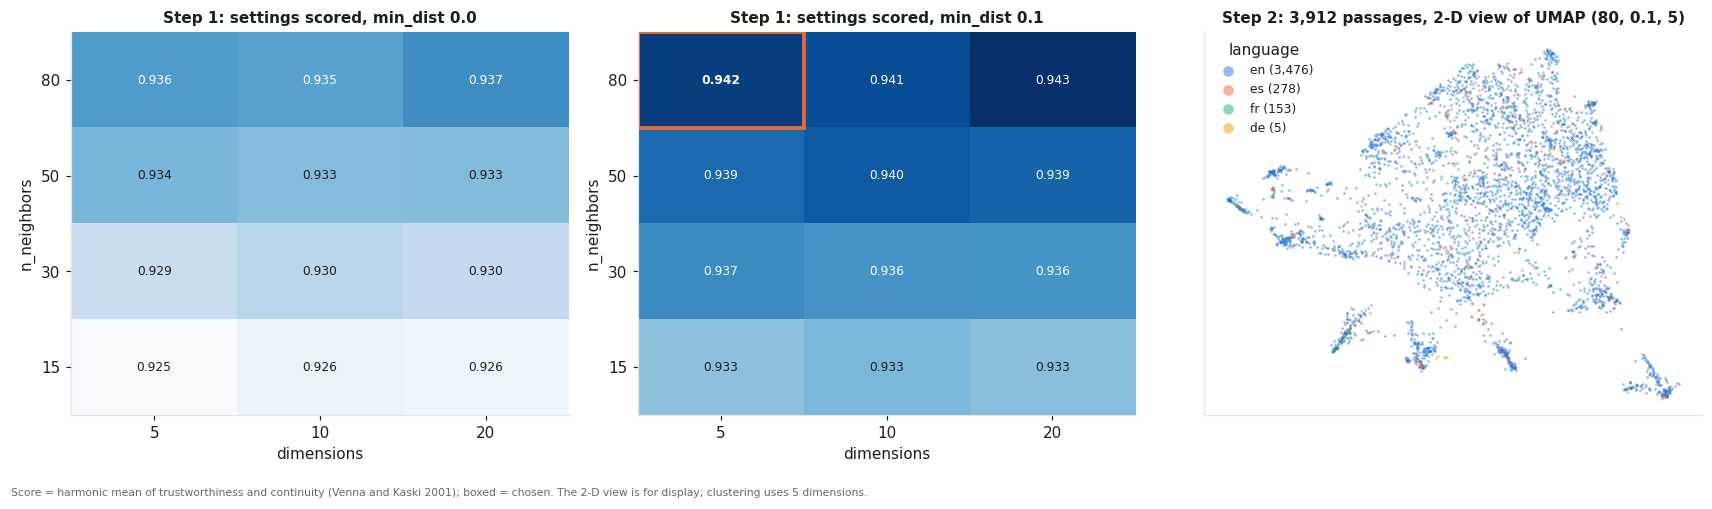


PRACTITIONER NOTE
  A setting tuned on one collection is tuned for that collection: record which corpus it was tuned on
  and search again when the corpus differs. When the grid barely separates the candidates, say so
  rather than presenting the choice as a tuned optimum.


In [ ]:
# @title
# ==================================================================================================
# PHASE: DIMENSION REDUCTION                                          the only stage in this phase
# STAGE 10  UMAP
# WHAT THIS CELL DOES: reduces 4,096 dimensions to a few with UMAP, settings chosen by measurement
# ==================================================================================================
# WHAT THIS CELL DOES
#   Dimension reduction. Step 1 chooses the UMAP setting by measurement; step 2 projects the
#   analysis set from 4,096 dimensions to the chosen few. The clustering in notebook 2 works there.
#
# WHY
#   Density clustering does not work in 4,096 dimensions, where distances concentrate. A setting
#   tuned on one corpus is tuned for that corpus, so it is re-measured or searched on this one.
#
# HOW
#   UMAP (McInnes, Healy and Melville 2018). Each candidate is scored by the harmonic mean of
#   trustworthiness and continuity (Venna and Kaski 2001): are neighbours kept, and are none
#   invented. Within PROJECTION_TIE_TOLERANCE of the best, the fewest dimensions win, then the
#   smaller neighbourhood. Parametric UMAP (Sainburg, McInnes and Gentner 2021) is not used: no new
#   passages are projected later, so it would add a neural network and training variance only.
#
# REFERENCES
#   McInnes, L., Healy, J. and Melville, J. (2018) UMAP: Uniform Manifold Approximation and
#     Projection for dimension reduction. arXiv:1802.03426.
#   Venna, J. and Kaski, S. (2001) Neighborhood preservation in nonlinear projection methods: an
#     experimental study. In ICANN 2001, LNCS 2130:485-491. Springer.
#   Sainburg, T., McInnes, L. and Gentner, T.Q. (2021) Parametric UMAP embeddings for
#     representation and semisupervised learning. Neural Computation 33(11):2881-2907.

import numpy as np, pandas as pd

# project() and projection_quality() are in the library (Stage 2); notebook 2 uses the same ones.
PROJECTION_MODE = str(CFG.projection_mode)
PROJECTION_TUNED_ON_CORPUS = str(CFG.projection_tuned_on_corpus)
PROJECTION_SEARCH_GRID = {
    "n_neighbors":   [int(v) for v in CFG.umap_neighbors_grid],
    "min_dist":      [float(v) for v in CFG.umap_min_dist_grid],
    "n_components":  [int(v) for v in CFG.umap_components_grid],
}

heading("STAGE 10  UMAP")

FINGERPRINT_MATCHES = (PROJECTION_TUNED_ON_CORPUS != ""
                       and PROJECTION_TUNED_ON_CORPUS == CORPUS_TEXT_FINGERPRINT)


print(f"  mode                  : {PROJECTION_MODE}")
print(f"  this analysis set     : {CORPUS_TEXT_FINGERPRINT}")
print(f"  frozen setting        : {tuple(CFG.umap_frozen)}, tuned on "
      f"{PROJECTION_TUNED_ON_CORPUS or 'no recorded corpus'}")

PROJECTION_SEARCH_TABLE = None
DECISION_REASON = ""

if PROJECTION_MODE == "frozen":
    DECISION = "frozen"
    DECISION_REASON = "the mode was set to 'frozen' explicitly"
elif PROJECTION_MODE == "search":
    DECISION = "search"
    DECISION_REASON = "the mode was set to 'search' explicitly"
elif not FINGERPRINT_MATCHES:
    DECISION = "search"
    DECISION_REASON = ("this is not the corpus the frozen setting was tuned on, so the setting "
                       "carries no evidence here")
else:
    # Same analysis set: keep the frozen setting only if it still clears the floor.
    Z_trial = cached("umap_frozen_trial", lambda: project(CFG.umap_frozen),
                     inputs=[CORPUS_TEXT_FINGERPRINT, CHOSEN_MODEL, tuple(CFG.umap_frozen),
                             CFG.seed], scope="inputs")
    harmonic, forward, backward = projection_quality(X, Z_trial)
    if harmonic >= CFG.projection_quality_floor:
        DECISION = "frozen"
        DECISION_REASON = (f"the same corpus, and the frozen setting measures {harmonic:.3f}, "
                           f"at or above the floor of {CFG.projection_quality_floor:.3f}")
        Z_best, BEST_UMAP = Z_trial, tuple(CFG.umap_frozen)
        HARMONIC_NOW, TRUST_NOW, CONTINUITY_NOW = harmonic, forward, backward
    else:
        DECISION = "search"
        DECISION_REASON = (f"the frozen setting measures {harmonic:.3f}, BELOW the floor of "
                           f"{CFG.projection_quality_floor:.3f}, so it no longer fits this data")

print(f"  DECISION              : {DECISION.upper()}")
print(f"    because             : {DECISION_REASON}")
print()

# PROJECTION_MODE = "frozen" reaches this point without a projection; make and measure it here.
if DECISION == "frozen" and "Z_best" not in globals():
    Z_best = cached("umap_frozen", lambda: project(CFG.umap_frozen),
                    inputs=[CORPUS_TEXT_FINGERPRINT, CHOSEN_MODEL, tuple(CFG.umap_frozen),
                            CFG.seed], scope="inputs")
    BEST_UMAP = tuple(CFG.umap_frozen)
    HARMONIC_NOW, TRUST_NOW, CONTINUITY_NOW = projection_quality(X, Z_best)
    if HARMONIC_NOW < CFG.projection_quality_floor:
        print(f"  WARNING: the frozen setting measures {HARMONIC_NOW:.3f}, below the floor of "
              f"{CFG.projection_quality_floor:.3f}. Set PROJECTION_MODE = 'auto'.")

if DECISION == "search":
    settings = [(n, d, c) for n in PROJECTION_SEARCH_GRID["n_neighbors"]
                for d in PROJECTION_SEARCH_GRID["min_dist"]
                for c in PROJECTION_SEARCH_GRID["n_components"]]
    print(f"  STEP 1  searching {len(settings)} settings on {len(X):,} passages "
          f"(cached after the first run)")

    def run_search():
        rows = []
        for position, setting in enumerate(settings, 1):
            projected = project(setting)
            harmonic, forward, backward = projection_quality(X, projected)
            rows.append({"n_neighbors": setting[0], "min_dist": setting[1],
                         "n_components": setting[2],
                         "trustworthiness": round(float(forward), 4),
                         "continuity": round(float(backward), 4),
                         "harmonic": round(float(harmonic), 4)})
            print(f"    {position:>2}/{len(settings)}  {str(setting):<16} harmonic "
                  f"{harmonic:.4f}")
        return pd.DataFrame(rows).sort_values("harmonic", ascending=False)

    # Keyed on its own inputs only, so an unrelated change in Stage 1 does not repeat the search.
    PROJECTION_SEARCH_TABLE = cached(
        "umap_search", run_search,
        inputs=[CORPUS_TEXT_FINGERPRINT, CHOSEN_MODEL, PROJECTION_SEARCH_GRID, CFG.seed,
                CFG.trustworthiness_k], scope="inputs")

    # A near tie is sampling noise (the scores come from one 600-passage sample), so the simpler
    # setting wins: fewest dimensions, then the smaller neighbourhood.
    _top = float(PROJECTION_SEARCH_TABLE["harmonic"].max())
    _tied = PROJECTION_SEARCH_TABLE[
        PROJECTION_SEARCH_TABLE["harmonic"] >= _top - float(CFG.projection_tie_tolerance)]
    winner = _tied.sort_values(["n_components", "n_neighbors", "harmonic"],
                              ascending=[True, True, False]).iloc[0]
    BEST_UMAP = (int(winner["n_neighbors"]), float(winner["min_dist"]),
                 int(winner["n_components"]))
    PROJECTION_TIE_COUNT = int(len(_tied))
    PROJECTION_TIE_MARGIN = float(_top - float(winner["harmonic"]))
    Z_best = cached("umap_best", lambda: project(BEST_UMAP),
                    inputs=[CORPUS_TEXT_FINGERPRINT, CHOSEN_MODEL, BEST_UMAP, CFG.seed],
                    scope="inputs")
    HARMONIC_NOW, TRUST_NOW, CONTINUITY_NOW = projection_quality(X, Z_best)

    print()
    print("  best five settings:")
    print(PROJECTION_SEARCH_TABLE.head(5).to_string(index=False))
    PROJECTION_SEARCH_TABLE.to_csv(os.path.join(FIGURE_DIR, "s10_projection_search.csv"),
                                   index=False)
    print()
    print(f"  chosen: n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]}, "
          f"dimensions={BEST_UMAP[2]}")
    if PROJECTION_TIE_COUNT > 1:
        print(f"    {PROJECTION_TIE_COUNT} settings tied within "
              f"{float(CFG.projection_tie_tolerance)} of the best ({_top:.4f}); the simplest was "
              f"taken, {PROJECTION_TIE_MARGIN:.4f} below the top. Report it as a tie broken on "
              f"simplicity.")
    else:
        print(f"    One setting leads the rest by more than "
              f"{float(CFG.projection_tie_tolerance)}.")
    _spread = float(PROJECTION_SEARCH_TABLE["harmonic"].max()
                    - PROJECTION_SEARCH_TABLE["harmonic"].min())
    print(f"  spread across the grid: {_spread:.4f}")
    if _spread < 0.02:
        print("    The grid barely separates the settings, so the choice is not load-bearing.")

# ---- step 2: the projection in use -------------------------------------------------------
print()
print(f"  STEP 2  projection in use: {BEST_UMAP}")
print(f"  measured on this data : trustworthiness {TRUST_NOW:.3f}, "
      f"continuity {CONTINUITY_NOW:.3f}, harmonic {HARMONIC_NOW:.3f}")
print(f"  shape                 : {Z_best.shape[0]:,} passages by {Z_best.shape[1]} dimensions")
report("projection.harmonic", round(float(HARMONIC_NOW), 4), "harmonic mean", "Stage 10")
report("projection.trustworthiness", round(float(TRUST_NOW), 4), "proportion", "Stage 10")
report("projection.continuity", round(float(CONTINUITY_NOW), 4), "proportion", "Stage 10")
report("projection.dimensions", int(Z_best.shape[1]), "dimensions", "Stage 10")

print(f"  (estimated on a seeded {min(600, len(X))}-passage sample)")
rule()

Z_two = cached("umap_2d", lambda: project((BEST_UMAP[0], BEST_UMAP[1], 2)),
               inputs=[CORPUS_TEXT_FINGERPRINT, CHOSEN_MODEL, BEST_UMAP[:2], 2, CFG.seed],
               scope="inputs")

# ---- figure: step 1 the settings searched, step 2 the corpus in the chosen projection ------
_grids = (sorted(PROJECTION_SEARCH_TABLE["min_dist"].unique())
          if PROJECTION_SEARCH_TABLE is not None else [])
fig, axes = plt.subplots(1, len(_grids) + 1, figsize=(5.2 * (len(_grids) + 1), 4.4), squeeze=False)
axes = axes[0]
_low = float(PROJECTION_SEARCH_TABLE["harmonic"].min()) if _grids else 0.0
_high = float(PROJECTION_SEARCH_TABLE["harmonic"].max()) if _grids else 1.0
for ax, min_dist in zip(axes, _grids):
    grid = (PROJECTION_SEARCH_TABLE[PROJECTION_SEARCH_TABLE["min_dist"] == min_dist]
            .pivot(index="n_neighbors", columns="n_components", values="harmonic"))
    image = ax.imshow(grid.values, cmap=SEQUENTIAL, vmin=_low, vmax=_high, aspect="auto",
                      origin="lower")
    ax.set_xticks(range(grid.shape[1]))
    ax.set_xticklabels(grid.columns)
    ax.set_yticks(range(grid.shape[0]))
    ax.set_yticklabels(grid.index)
    ax.set_xlabel("dimensions")
    ax.set_ylabel("n_neighbors")
    ax.grid(False)
    for i, n_neighbors in enumerate(grid.index):
        for j, n_components in enumerate(grid.columns):
            chosen = (n_neighbors, min_dist, n_components) == BEST_UMAP
            ax.text(j, i, f"{grid.iat[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    fontweight="bold" if chosen else "normal",
                    color="white" if grid.iat[i, j] > (_low + _high) / 2 else INK)
            if chosen:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, lw=2.5,
                                           edgecolor=PALETTE[1]))
    ax.set_title(f"Step 1: settings scored, min_dist {min_dist}", fontsize=10)
_languages = passages["doc_language"].to_numpy()[ANALYSIS_ROWS]
_names = pd.Series(_languages).value_counts().index.tolist()
_colour = dict(zip(_names, palette(len(_names))))
ax = axes[-1]
for name in _names:
    rows = _languages == name
    ax.scatter(Z_two[rows, 0], Z_two[rows, 1], s=3, alpha=0.5, color=_colour[name],
               linewidths=0, label=f"{name} ({int(rows.sum()):,})")
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.legend(fontsize=8, frameon=False, markerscale=4, title="language")
ax.set_title(f"Step 2: {len(Z_two):,} passages, 2-D view of UMAP {BEST_UMAP}", fontsize=10)
fig.tight_layout()
add_reference_footer(fig, "Score = harmonic mean of trustworthiness and continuity "
                          "(Venna and Kaski 2001); boxed = chosen. The 2-D view is for display; "
                          f"clustering uses {Z_best.shape[1]} dimensions.")
save_figure(fig, "s10_projection"); plt.show()

practitioner_note("Choosing a projection", """
A setting tuned on one collection is tuned for that collection: record which corpus it was tuned on
and search again when the corpus differs. When the grid barely separates the candidates, say so
rather than presenting the choice as a tuned optimum.
""")

## Stage 11: hand over to notebook 2   [phase: handover]

**What.** Saves everything notebook 2 needs in one bundle on Drive: the passage table, the analysis
set, the projection, the lexicon, the ledgers and every reported number. The embedding file is not
copied; the bundle records its name, shape and hash, and notebook 2 verifies all three.

**Check.** The reconciliation from the raw file to the analysed set must add up, or nothing is
written. Notebook 2 stops if the corpus or an upstream setting differs.

The figures and tables of this notebook are kept on Drive; notebook 2's last cell packs them, with
its own, into one download.

**Next.** Open notebook 2.

  STAGE 11  HAND OVER TO NOTEBOOK 2
  all 21 required objects are present
  RECONCILIATION, IN DOCUMENTS
    rows in the raw file : 1,481
      less    119  too short after cleaning
    analysed documents   : 1,362
    PASSES               : 1,481 - 119 = 1,362
  SEPARATELY, IN OTHER UNITS  (not documents, not added above)
          76  passage fragments below the floor  [word]
  numbers registered   : 76

  embedding file     : embed_qwen3-8b__e967d94ba84a.pkl
    location         : durable  (loaded)
    size             : 99.8 MB

  HANDOFF WRITTEN
    file      : handoff_nb1_to_nb2__6bf86906b520__565d749e9a73.pkl
    folder    : /content/drive/MyDrive/CIRP_MSF/checkpoints/handoff
    size      : 36.5 MB
    checksum  : 9674d844ed183df0
    a .json summary sits beside it, readable without unpickling
    the embedding is NOT inside; it is referenced by the name recorded above
    notebook 2 will check the corpus fingerprint 6bf86906b520 and the upstream
      settings, and will stop i

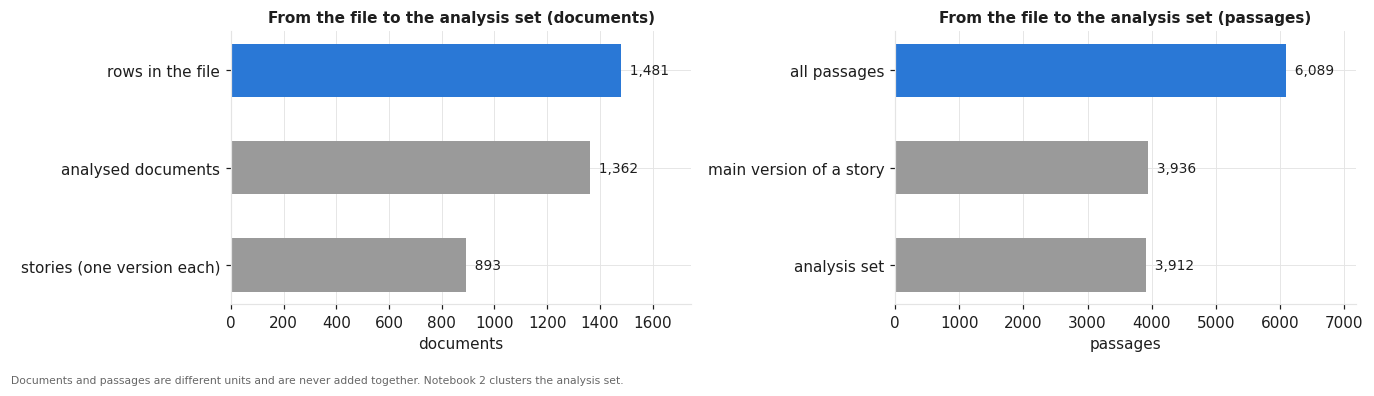

  tables kept on Drive  : 14 of 14

PRACTITIONER NOTE
  Write cross-notebook state to one bundle with a fingerprint of the inputs and settings, so the
  next notebook either matches or refuses to start. Reference a large array by its content-addressed
  name, with shape and hash recorded, rather than copying it.


In [ ]:
# @title
# ==================================================================================================
# PHASE: HANDOVER                                                     the only stage in this phase
# STAGE 11  HAND OVER TO NOTEBOOK 2
# WHAT THIS CELL DOES: saves everything notebook 2 needs in one checked bundle
# ==================================================================================================
# WHAT THIS CELL DOES
#   Verifies that every object notebook 2 needs is present, then writes them to one bundle in
#   durable storage. The embedding is referenced by name, shape and hash rather than copied,
#   since it already lives in durable storage and is 100 MB.
#
# WHY
#   A pipeline split across notebooks can let state cross the boundary invisibly, so a later
#   notebook runs on stale inputs without anyone noticing. The bundle carries fingerprints of
#   the corpus and the configuration, so notebook 2 either matches or stops.

import os, pickle, hashlib, datetime, json
import numpy as np, pandas as pd

heading("STAGE 11  HAND OVER TO NOTEBOOK 2")

# ---- objects notebook 2 needs; a missing one stops the run here ----
# write_handoff repeats this check, so it runs at both boundaries of the pipeline.
REQUIRED_FOR_NB2 = {
    "passages":        "the passage table, with the lexicon columns and the detected language",
    "df_analysis":     "the document table",
    "X_ALL":           "the embedding of every passage",
    "ANALYSIS_ROWS":   "the passages in the analysis set",
    "LANGUAGE_OFFSETS":"the language offsets applied to the vectors (may be empty)",
    "Z_best":          "the projection",
    "BEST_UMAP":       "the projection setting in use",
    "CFG":             "the configuration",
    "CATEGORIES":      "the lexicon's category names",
    "CODEBOOK":        "the lexicon itself",
    "N_PATTERNS":      "how many patterns the lexicon holds",
    "SHORT_LABELS":    "readable category labels",
    "BARRIER_SUBTYPES":"the barrier sub-concepts",
    "CANONICAL":       "the subject folds",
    "CAT_COLS":        "the lexicon column names",
    "CURATED_PLACE_WORDS": "the place words and demonyms the masking stage used",
    "CAPABILITIES":    "what this corpus supports",
    "CORPUS_LEDGER":   "the reconciliation from raw rows to the analysed set",
    "NUMBER_REGISTER": "every number reported so far",
    "CLEANING_LEDGER": "what each cleaning rule did",
    "ENVIRONMENT":     "the software versions that produced this",
}
_missing_now = [name for name in REQUIRED_FOR_NB2 if name not in globals()]
if _missing_now:
    print("  STOP. This run is incomplete and no handoff will be written.")
    for name in _missing_now:
        print(f"    missing: {name:<18} {REQUIRED_FOR_NB2[name]}")
    raise RuntimeError("Run every cell above, in order, before writing the handoff.")
print(f"  all {len(REQUIRED_FOR_NB2)} required objects are present")

# The ledger must reconcile: documents and passage fragments are different units, counted
# separately and never summed; a ledger that does not add up is caught here, not later.
_final_documents = len(df_analysis)
_doc_rows = [r for r in CORPUS_LEDGER if r.get("unit", "document") == "document"]
_other_rows = [r for r in CORPUS_LEDGER if r.get("unit", "document") != "document"]
if not _doc_rows:                        # older ledgers carry no unit field; fall back by name
    _other_rows = [r for r in CORPUS_LEDGER if r["step"] == "passage fragments below the floor"]
    _doc_rows = [r for r in CORPUS_LEDGER if r not in _other_rows]
_document_removed = sum(int(r["removed"]) for r in _doc_rows)
_document_expected = int(_doc_rows[0]["rows_in"]) - _document_removed

print(f"  RECONCILIATION, IN DOCUMENTS")
print(f"    rows in the raw file : {int(_doc_rows[0]['rows_in']):,}")
for row in _doc_rows:
    if int(row["removed"]):
        print(f"      less {int(row['removed']):>6,}  {row['step']}")
print(f"    analysed documents   : {_final_documents:,}")
assert _document_expected == _final_documents, (
    "Document ledger does not reconcile; do not hand this off.")
print(f"    PASSES               : {int(_doc_rows[0]['rows_in']):,} - {_document_removed:,} "
      f"= {_final_documents:,}")
if _other_rows:
    print(f"  SEPARATELY, IN OTHER UNITS  (not documents, not added above)")
    for row in _other_rows:
        print(f"    {int(row['removed']):>8,}  {row['step']}  "
              f"[{row.get('unit', 'unit not recorded')}]")
print(f"  numbers registered   : {len(NUMBER_REGISTER)}")

# ---- locate the embedding in durable storage, by name ----
# The filename comes from the cache register rather than being rebuilt here, so only one
# place decides Stage 9's output name.
_embedding_tag = f"embed_{CHOSEN_MODEL}"
_record = CACHE_FILES.get(_embedding_tag)

print()
if _record is None:
    print(f"  WARNING: no cache entry for '{_embedding_tag}'.")
    print("  Notebook 2 will recompute the embedding, which needs a GPU.")
    EMBEDDING_FILE = None
    EMBEDDING_LOCATION = None
    EMBEDDING_BYTES = 0
else:
    EMBEDDING_FILE = _record["filename"]
    EMBEDDING_LOCATION = _record["path"]
    EMBEDDING_BYTES = _record["bytes"]
    print(f"  embedding file     : {EMBEDDING_FILE}")
    print(f"    location         : {_record['location']}  ({_record['state']})")
    print(f"    size             : {EMBEDDING_BYTES / 1e6:.1f} MB")
    if _record["location"] != "durable":
        print("    WARNING: not in durable storage; it will be lost when the runtime ends.")
        print("    Mount Drive and re-run Stage 9 to place a durable copy.")

EMBEDDING_RECORD = {
    "tag": _embedding_tag,
    "file": EMBEDDING_FILE,
    "key": (_record or {}).get("key"),
    "location": (_record or {}).get("location", "none"),
    "bytes": EMBEDDING_BYTES,
    # FILE holds every passage (X_ALL); the projection covers only the analysis set.
    "shape": tuple(int(v) for v in X_ALL.shape),
    "dtype": str(X_ALL.dtype),
    "sha256_first_16": hashlib.sha256(np.ascontiguousarray(X_ALL).tobytes()).hexdigest()[:16],
    "norm_mean": round(float(np.linalg.norm(X_ALL, axis=1).mean()), 6),
    "analysis_rows": int(len(ANALYSIS_ROWS)),
    "cache_subfolder": os.path.basename(DURABLE_CACHE),
}

# ---- the bundle -------------------------------------------------------------
PAYLOAD = {
    "produced_by": "notebook 1, stages 0 to 11",
    "passages": passages,
    "df_analysis": df_analysis,
    "story_threshold": STORY_THRESHOLD,
    "language_consistency": LANGUAGE_CONSISTENCY,
    "language_neutrality": LANGUAGE_NEUTRALITY,
    # the offsets are applied again in notebook 2, to the vectors as stored on disk
    "language_offsets": {k: np.asarray(v, dtype=np.float32) for k, v in LANGUAGE_OFFSETS.items()},
    "language_correction": LANGUAGE_CORRECTION,
    "language_separation": LANGUAGE_SEPARATION,
    # the second embedding model's vectors for the analysis set (Stage 16b), or None
    "second_model": SECOND_MODEL,
    # the human-coded random sample and the corrected shares (Stage 7c), or None
    "human_sample": HUMAN_SAMPLE_RESULT,

    # the projection travels in the bundle since it is small; the embedding does not
    "Z_best": Z_best,
    "best_umap": tuple(BEST_UMAP),
    "projection_harmonic": round(float(HARMONIC_NOW), 4),
    "projection_decision": DECISION,
    "projection_decision_reason": DECISION_REASON,
    "embedding_record": EMBEDDING_RECORD,
    "chosen_model": CHOSEN_MODEL,

    # the lexicon travels too, so notebook 2 can select by scope without redefining it
    "categories": CATEGORIES,
    "codebook": CODEBOOK,
    "n_patterns": int(N_PATTERNS),  # real pattern count; differs from len(CODEBOOK) (= CATEGORIES)
    "short_labels": SHORT_LABELS,
    "barrier_subtypes": BARRIER_SUBTYPES,
    "canonical": CANONICAL,
    "cat_cols": CAT_COLS,
    "bar_cols": BAR_COLS,
    "weak_categories": sorted(WEAK_CATEGORIES),
    # Place words the masking stage used; notebook 2 needs them so the naming stage does not
    # turn a masked place name's derived form into part of a theme label.
    "curated_place_words": sorted(CURATED_PLACE_WORDS),
    "precision_table": PRECISION_TABLE,
    "precision_source": PRECISION_SOURCE,

    # what the corpus supports, and its groups
    "capabilities": CAPABILITIES,
    "groups": GROUPS,
    "group_labels": GROUP_LABELS,
    "group_noun": CFG.group_noun,

    # the deductive route's tables, so notebook 3 can compare the two routes
    "group_main": GROUP_MAIN,
    "group_all": GROUP_ALL,
    "group_n": GROUP_N,
    "scope_sensitivity": SCOPE_SENSITIVITY,

    # accumulating records; notebook 2 and 3 append to these, they never start fresh
    "corpus_ledger": CORPUS_LEDGER,
    "cleaning_ledger": CLEANING_LEDGER,
    "number_register": NUMBER_REGISTER,
    "figure_ledger": FIGURE_LEDGER,
    "practitioner_notes": PRACTITIONER_NOTES,
    "environment": ENVIRONMENT,
    # Hash of the source of every function this notebook defines. Notebook 2 compares it and
    # reports which functions changed; this is informational, not a gate on the run.
    "code_fingerprint": code_fingerprint(globals()),
}

# The required-objects check already ran above, so write_handoff need not repeat it here;
# passing no "__namespace__" key signals that. Stage 21 passes one, checking both boundaries.
RESULT = write_handoff("nb1_to_nb2", PAYLOAD, REQUIRED_FOR_NB2, CORPUS_TEXT_FINGERPRINT)
HANDOFF_PATH = RESULT["path"]
print_handoff(RESULT, extra_lines=[
    "the embedding is NOT inside; it is referenced by the name recorded above",
    f"notebook 2 will check the corpus fingerprint {CORPUS_TEXT_FINGERPRINT} and the upstream",
    f"  settings, and will stop if either differs",
])
HANDOFF_BYTES = RESULT["bytes"]

report("handoff.bytes", HANDOFF_BYTES, "bytes", "Stage 11")
report("handoff.passages", len(passages), "passages", "Stage 11")

# ---- figure: file to analysis set, in documents and in passages ----
_steps_docs = [
    ("rows in the file", int(_doc_rows[0]["rows_in"]) if _doc_rows else len(df_analysis)),
    ("analysed documents", len(df_analysis))]
if "story_id" in df_analysis.columns:
    _steps_docs.append(("stories (one version each)", int(df_analysis["story_id"].nunique())))
_steps_passages = [("all passages", len(passages)),
                   ("main version of a story", int(passages["is_main_version"].sum())),
                   ("analysis set", int(passages["in_analysis"].sum()))]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.4))
for ax, steps, unit in (
        (axes[0], _steps_docs, "documents"), (axes[1], _steps_passages, "passages")):
    labels = [name for name, _ in steps][::-1]
    values = [value for _, value in steps][::-1]
    ax.barh(labels, values, height=0.55, color=[OTHER] * (len(values) - 1) + [PALETTE[0]])
    for k, value in enumerate(values):
        ax.text(value, k, f"  {value:,}", va="center", fontsize=9)
    ax.set_xlim(0, max(values) * 1.18)
    ax.set_xlabel(unit)
    ax.set_title(f"From the file to the analysis set ({unit})", fontsize=10)
fig.tight_layout()
add_reference_footer(
    fig,
    "Documents and passages are different units and are never added together. "
    "Notebook 2 clusters the analysis set.")
save_figure(fig, "s11_handover"); plt.show()

# ---- keep notebook 1's tables on Drive beside its figures, for the download in notebook 2 ----
_tables = sorted(f for f in os.listdir(FIGURE_DIR) if f.endswith((".csv", ".json")))
_kept = [keep_on_drive(os.path.join(FIGURE_DIR, f)) for f in _tables]
print(f"  tables kept on Drive  : {sum(1 for k in _kept if k)} of {len(_tables)}"
      + ("" if globals().get("DURABLE_OUTPUT_DIR") else " (Drive not mounted)"))

practitioner_note("Handing over", """
Write cross-notebook state to one bundle with a fingerprint of the inputs and settings, so the
next notebook either matches or refuses to start. Reference a large array by its content-addressed
name, with shape and hash recorded, rather than copying it.
""")